# Triângulos Retângulos

**Módulo:** 04 – Geometria Plana

**Pré-requisitos:** [`0404a_triangulos_conceito_elementos_e_classificacao.ipynb`](0404a_triangulos_conceito_elementos_e_classificacao.ipynb) (classificação dos triângulos, **catetos** e **hipotenusa**, desigualdade triangular), [`0405a_congruencia_de_triangulos.ipynb`](0405a_congruencia_de_triangulos.ipynb) (caso **LLL**, usado na recíproca de Pitágoras), [`0407a_perpendicularidade.ipynb`](0407a_perpendicularidade.ipynb) (projeção ortogonal e distância de ponto a reta), [`0409a_paralelogramos_e_casos_particulares.ipynb`](0409a_paralelogramos_e_casos_particulares.ipynb) (diagonais do quadrado, do retângulo e do losango), [`0410a_pontos_notaveis_do_triangulo.ipynb`](0410a_pontos_notaveis_do_triangulo.ipynb) (circuncentro, incentro e a razão 2 : 1 do baricentro), [`0412a_circunferencia_e_circulo.ipynb`](0412a_circunferencia_e_circulo.ipynb) e [`0413a_angulos_na_circunferencia.ipynb`](0413a_angulos_na_circunferencia.ipynb) (tangente perpendicular ao raio, segmentos tangentes, corda; o triângulo retângulo inscrito na semicircunferência) e [`0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb`](0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb) (critério **AA** e potência de ponto, o motor das demonstrações deste notebook).

**Objetivos de aprendizagem:** ao final você será capaz de...
- Identificar os elementos de um triângulo retângulo (catetos, hipotenusa, altura relativa à hipotenusa, projeções) e **deduzir as relações métricas** a partir da semelhança de três triângulos.
- Enunciar, **demonstrar** e aplicar o **Teorema de Pitágoras** e a sua **recíproca**, classificar um triângulo quanto aos ângulos **só pelos lados** e reconhecer ternos pitagóricos.
- Usar os triângulos retângulos **notáveis** (45°–45°–90° e 30°–60°–90°) para obter diagonais, alturas e razões exatas.
- Aplicar Pitágoras em problemas com quadriláteros e circunferências: distância entre pontos, diagonais, losango, trapézio, tangente, corda e os raios das circunferências inscrita e circunscrita.

**Tempo estimado:** 90 a 105 minutos (é um dos notebooks mais densos do módulo: vale dividir em duas sessões, uma até a seção 3 e outra para as seções 4 e 5)

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/leandrofreiredealmeida/curso_matematica_python/blob/main/04_geometria_plana/0416a_triangulos_retangulos.ipynb)

## Quadrados nos lados

Pegue um triângulo com lados **3**, **4** e **5** (em centímetros, palitos, passos, tanto faz). Os lados de 3 e 4 formam um **canto reto**, como o canto de uma folha de papel. Agora construa um **quadrado** sobre cada lado e conte os quadradinhos de lado 1 dentro de cada um:

- sobre o lado 3 cabem $3 \times 3 = 9$ quadradinhos;
- sobre o lado 4 cabem $4 \times 4 = 16$;
- sobre o lado 5 cabem $5 \times 5 = 25$.

E $9 + 16 = 25$. Os dois quadrados menores, juntos, têm **exatamente** a área do quadrado maior. **Coincidência?**

**Antes de executar:** e se o canto **não** fosse reto? Se você abrisse um pouco mais o ângulo entre os lados de 3 e 4 (como uma dobradiça), o terceiro lado cresceria ou diminuiria? A soma $9 + 16$ continuaria igual ao quadrado do terceiro lado? Faça a sua aposta e rode as células abaixo (a primeira carrega as ferramentas do notebook).

In [1]:
import math
from math import gcd

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import ipywidgets as widgets
from IPython.display import display
from matplotlib.patches import Arc, Circle, Polygon, Rectangle, Wedge

# Paleta de cores Nord
NORD_FUNDO = "#2E3440"
NORD_PAINEL = "#3B4252"
NORD_LINHA = "#4C566A"
NORD_TEXTO = "#ECEFF4"
NORD_TEXTO_SEC = "#D8DEE9"
COR_PONTO = "#88C0D0"
COR_DESTAQUE = "#A3BE8C"
COR_ALERTA = "#BF616A"
COR_SECUNDARIA = "#81A1C1"
COR_EXTRA = "#B48EAD"
COR_AVISO = "#EBCB8B"


def estilizar_eixo(ax) -> None:
    """Aplica o estilo Nord padrão a um eixo do matplotlib."""
    ax.set_facecolor(NORD_FUNDO)
    ax.tick_params(colors=NORD_TEXTO_SEC)
    for spine in ax.spines.values():
        spine.set_color(NORD_LINHA)
    ax.grid(color=NORD_LINHA, linewidth=0.5, alpha=0.5)


# Ferramentas de desenho e de medida dos notebooks anteriores (0401a, 0402a, 0407a, 0410a, 0412a e 0415a)

def preparar_eixo(ax, pontos, margem: float = 0.8) -> None:
    """Deixa o eixo pronto para desenhos de geometria (estilo Nord, sem grade, sem números,
    escala igual) e enquadra todos os `pontos` com uma margem em volta."""
    estilizar_eixo(ax)
    ax.grid(False)
    xs = [p[0] for p in pontos]
    ys = [p[1] for p in pontos]
    ax.set_xlim(min(xs) - margem, max(xs) + margem)
    ax.set_ylim(min(ys) - margem, max(ys) + margem)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])


def direcao(angulo_graus: float) -> np.ndarray:
    """Vetor de tamanho 1 apontando na direção dada, em graus, a partir da horizontal (sentido anti-horário).

    (cos e sin vêm da Trigonometria, módulo 05; aqui só servem para apontar na direção certa.)
    """
    rad = math.radians(angulo_graus)
    return np.array([math.cos(rad), math.sin(rad)])


def direcao_de(origem, destino) -> float:
    """Direção, em graus, em que `destino` está quando visto de `origem`."""
    return math.degrees(math.atan2(destino[1] - origem[1], destino[0] - origem[0]))


def medir_angulo(vertice, P, Q) -> float:
    """Transferidor digital: medida, em graus, do ângulo com vértice em `vertice`
    formado pelas semirretas que passam por P e por Q (resultado entre 0° e 180°)."""
    u = np.subtract(P, vertice)
    v = np.subtract(Q, vertice)
    cosseno = np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v))
    return math.degrees(math.acos(np.clip(cosseno, -1, 1)))


def cruzamento(P, inclinacao_1: float, Q, inclinacao_2: float):
    """Ponto em que a reta que passa por P (com a inclinação `inclinacao_1`, em graus) cruza a reta
    que passa por Q (com a inclinação `inclinacao_2`). Devolve None se as duas retas tiverem a mesma
    direção, porque aí elas não se cruzam num ponto só.

    Por trás, é um sistema linear 2×2 (módulo 03): P + t·u = Q + k·v, com incógnitas t e k.
    """
    matriz = np.column_stack([direcao(inclinacao_1), -direcao(inclinacao_2)])
    if abs(np.linalg.det(matriz)) < 1e-12:
        return None
    t, _ = np.linalg.solve(matriz, np.subtract(Q, P))
    return np.array(P, dtype=float) + t * direcao(inclinacao_1)


def ponto_medio(P, Q) -> np.ndarray:
    """Ponto médio do segmento PQ: a média das coordenadas (0402a)."""
    return (np.asarray(P, dtype=float) + np.asarray(Q, dtype=float)) / 2


def iguais(x: float, y: float) -> bool:
    """Compara duas medidas com uma tolerância pequena (as contas com float têm arredondamentos)."""
    return math.isclose(x, y, rel_tol=1e-9, abs_tol=1e-6)


def desenhar_ponto(ax, p, nome: str = "", cor: str = COR_AVISO, deslocamento=(0.12, 0.15),
                   tamanho_fonte: int = 13) -> None:
    """Desenha um ponto com seu nome (letra maiúscula) ao lado."""
    ax.plot(*p, "o", color=cor, markersize=7, zorder=6)
    if nome:
        ax.text(p[0] + deslocamento[0], p[1] + deslocamento[1], nome, color=NORD_TEXTO, fontsize=tamanho_fonte,
                fontweight="bold", zorder=7)


def desenhar_segmento(ax, P, Q, cor: str = NORD_TEXTO, largura: float = 3.0, estilo: str = "-",
                      alpha: float = 1.0, zorder: int = 5) -> None:
    """Desenha o segmento PQ (só o pedaço entre P e Q)."""
    ax.plot(*zip(P, Q), color=cor, lw=largura, linestyle=estilo, alpha=alpha, zorder=zorder,
            solid_capstyle="round")


def desenhar_setor(ax, vertice, inicio: float, abertura: float, raio: float = 0.5, cor: str = COR_PONTO,
                   rotulo: str | None = None, marcar_reto: bool = True, raio_rotulo: float | None = None,
                   tamanho_fonte: int = 11) -> None:
    """Pinta o ângulo com vértice em `vertice` que começa na direção `inicio` e gira `abertura`
    graus no sentido anti-horário. O ângulo reto ganha o quadradinho no lugar do arco."""
    v = np.array(vertice, dtype=float)
    if marcar_reto and math.isclose(abertura, 90, abs_tol=1e-6):
        lado = 0.6 * raio
        canto = [v, v + lado * direcao(inicio), v + lado * (direcao(inicio) + direcao(inicio + 90)),
                 v + lado * direcao(inicio + 90)]
        ax.add_patch(Polygon(canto, closed=True, facecolor=cor, alpha=0.35, edgecolor=cor, lw=2))
    else:
        ax.add_patch(Wedge(v, raio, inicio, inicio + abertura, facecolor=cor, alpha=0.3, edgecolor="none"))
        ax.add_patch(Arc(v, 2 * raio, 2 * raio, theta1=inicio, theta2=inicio + abertura, color=cor, lw=2))
    if rotulo:
        distancia_rotulo = 1.6 * raio if raio_rotulo is None else raio_rotulo
        posicao = v + distancia_rotulo * direcao(inicio + abertura / 2)
        ax.text(*posicao, rotulo, color=cor, fontsize=tamanho_fonte, ha="center", va="center", fontweight="bold")


def desenhar_arco(ax, vertice, p, q, **opcoes) -> None:
    """Marca o ângulo de vértice `vertice` formado pelas semirretas que passam por p e por q
    (sempre a abertura menor, entre 0° e 180°). Aceita as mesmas opções de `desenhar_setor`."""
    inicio = direcao_de(vertice, p) % 360
    abertura = (direcao_de(vertice, q) - inicio) % 360
    if abertura > 180:
        inicio, abertura = direcao_de(vertice, q) % 360, 360 - abertura
    desenhar_setor(ax, vertice, inicio, abertura, **opcoes)


def rotular_fora(ax, P, texto: str, centro, cor: str = NORD_TEXTO, distancia: float = 0.35,
                 tamanho: int = 12) -> None:
    """Escreve `texto` perto do ponto P, afastado do `centro` (para não ficar em cima da figura)."""
    P = np.asarray(P, dtype=float)
    afastar = P - np.asarray(centro, dtype=float)
    afastar = afastar / np.linalg.norm(afastar) if np.linalg.norm(afastar) > 0 else np.array([0.0, 1.0])
    ax.text(*(P + distancia * afastar), texto, color=cor, fontsize=tamanho, fontweight="bold",
            ha="center", va="center", zorder=7)


def rotular_segmento(ax, P, Q, texto: str, cor: str = NORD_TEXTO, distancia: float = 0.35, longe_de=None,
                     tamanho: int = 11) -> None:
    """Escreve `texto` ao lado do meio do segmento PQ, afastado `distancia` na direção perpendicular a ele.
    Se `longe_de` for um ponto, o texto vai para o lado do segmento oposto a esse ponto."""
    P, Q = np.asarray(P, dtype=float), np.asarray(Q, dtype=float)
    u = (Q - P) / np.linalg.norm(Q - P)
    normal = np.array([-u[1], u[0]])
    meio = (P + Q) / 2
    if longe_de is not None and np.dot(meio - np.asarray(longe_de, dtype=float), normal) < 0:
        normal = -normal
    ax.text(*(meio + distancia * normal), texto, color=cor, fontsize=tamanho, fontweight="bold",
            ha="center", va="center", zorder=7)


def escrever_checklist(ax, itens, titulo: str = "") -> None:
    """Painel de texto com uma linha por item (texto, ok): ✓ verde quando vale, ✗ vermelho quando não (0410a)."""
    ax.set_facecolor(NORD_FUNDO)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")
    if titulo:
        ax.text(0.0, 0.97, titulo, color=NORD_TEXTO, fontsize=12, fontweight="bold", va="top")
    passo = min(0.13, 0.85 / max(len(itens), 1))
    for k, (texto, ok) in enumerate(itens):
        ax.text(0.0, 0.84 - k * passo, f"{'✓' if ok else '✗'}  {texto}", color=COR_DESTAQUE if ok else COR_ALERTA,
                fontsize=11, va="top")


def desenhar_circunferencia(ax, O, r: float, cor: str = COR_PONTO, estilo: str = "-",
                            largura: float = 2.5, preencher: bool = False, opacidade: float = 0.15) -> None:
    """Desenha a circunferência de centro O e raio r (a linha). Com `preencher=True`, pinta também a
    região interna: o círculo (0412a)."""
    O = tuple(np.asarray(O, dtype=float))
    if preencher:
        ax.add_patch(Circle(O, r, facecolor=cor, alpha=opacidade, edgecolor="none", zorder=1))
    ax.add_patch(Circle(O, r, fill=False, edgecolor=cor, lw=largura, linestyle=estilo, zorder=3))


def lados(t) -> tuple[float, float, float]:
    """Medidas (a, b, c) dos lados do triângulo t = (A, B, C), na convenção de 0404a: a = BC é oposto a A,
    b = CA é oposto a B e c = AB é oposto a C."""
    A, B, C = t
    return math.dist(B, C), math.dist(C, A), math.dist(A, B)


def angulos(t) -> tuple[float, float, float]:
    """Medidas, em graus, dos ângulos internos (Â, B̂, Ĉ) do triângulo t = (A, B, C)."""
    A, B, C = t
    return medir_angulo(A, B, C), medir_angulo(B, C, A), medir_angulo(C, A, B)


def triangulo_por_lados(a: float, b: float, c: float):
    """Triângulo (A, B, C) com BC = a, CA = b e AB = c: A na origem, B sobre o eixo x e C no cruzamento das
    circunferências λ(A, b) e λ(B, a) (0415a). Devolve None se as medidas não formam triângulo (0404a)."""
    if not abs(b - c) < a < b + c:
        return None
    x = (b**2 + c**2 - a**2) / (2 * c)
    y = math.sqrt(b**2 - x**2)
    return [np.array([0.0, 0.0]), np.array([c, 0.0]), np.array([x, y])]


def criterios_semelhanca(t1, t2) -> list[str]:
    """Lista dos critérios de semelhança ("AA", "LAL", "LLL") satisfeitos pelos triângulos t1 = (A, B, C) e
    t2 = (A', B', C'), com a correspondência dada pela ORDEM dos vértices (A↔A', B↔B', C↔C') (0415a)."""
    angulos_iguais = [math.isclose(x, y, abs_tol=1e-6) for x, y in zip(angulos(t1), angulos(t2))]
    razoes = [y / x for x, y in zip(lados(t1), lados(t2))]  # razoes[i]: lado oposto ao vértice i
    criterios = []
    if sum(angulos_iguais) >= 2:
        criterios.append("AA")
    for i in range(3):
        j, m = [x for x in range(3) if x != i]
        if angulos_iguais[i] and iguais(razoes[j], razoes[m]):
            criterios.append("LAL")
            break
    if iguais(razoes[0], razoes[1]) and iguais(razoes[1], razoes[2]):
        criterios.append("LLL")
    return criterios


def pe_da_altura(vertice, P, Q) -> np.ndarray:
    """Pé da altura traçada de `vertice` até a reta PQ: a projeção ortogonal do vértice sobre essa reta (0407a e
    0410a). Em coordenadas, H = P + ((V − P)·(Q − P) / |Q − P|²)·(Q − P)."""
    V, P, Q = (np.asarray(X, dtype=float) for X in (vertice, P, Q))
    u = Q - P
    return P + np.dot(V - P, u) / np.dot(u, u) * u


def distancia_ponto_reta(X, P, Q) -> float:
    """Distância do ponto X à reta PQ: a medida de X até o pé da perpendicular (0407a)."""
    return math.dist(X, pe_da_altura(X, P, Q))


def baricentro(A, B, C) -> np.ndarray:
    """Baricentro G: a média das coordenadas dos três vértices (0410a)."""
    return (np.asarray(A, dtype=float) + np.asarray(B, dtype=float) + np.asarray(C, dtype=float)) / 3


def incentro(A, B, C) -> np.ndarray:
    """Incentro I: a média dos vértices ponderada pelos lados opostos, I = (a·A + b·B + c·C) / (a + b + c) (0410a)."""
    a, b, c = lados([A, B, C])
    A, B, C = (np.asarray(X, dtype=float) for X in (A, B, C))
    return (a * A + b * B + c * C) / (a + b + c)


def circuncentro(A, B, C) -> np.ndarray:
    """Circuncentro: o cruzamento das mediatrizes de AB e de BC, as perpendiculares aos lados pelos pontos
    médios (0407a e 0410a)."""
    return cruzamento(ponto_medio(A, B), direcao_de(A, B) + 90, ponto_medio(B, C), direcao_de(B, C) + 90)


# Ferramentas novas deste notebook
# Notação fixa: a = BC (hipotenusa), b = CA e c = AB (catetos), h = AH (altura relativa à hipotenusa),
# m = BH (projeção de c) e n = HC (projeção de b). Cada cateto e a SUA projeção têm sempre a mesma cor.
COR_HIPOTENUSA = COR_AVISO  # a: amarelo
COR_CATETO_B = COR_DESTAQUE  # b e a sua projeção n: verde
COR_CATETO_C = COR_EXTRA  # c e a sua projeção m: roxo
COR_ALTURA = "#D08770"  # h: laranja
COR_TRIANGULO = COR_PONTO  # preenchimento dos triângulos
COR_CIRCULO = COR_SECUNDARIA  # circunferências


def triangulo_retangulo(a: float, posicao: float):
    """Triângulo ABC retângulo em A, com a hipotenusa BC = a sobre o eixo x (B = (0, 0) e C = (a, 0)) e o vértice
    A na semicircunferência de diâmetro BC, na direção `posicao` (em graus, entre 0° e 180°) vista do centro.
    Todo ponto dessa semicircunferência enxerga BC sob um ângulo reto (0413a)."""
    B, C = np.array([0.0, 0.0]), np.array([float(a), 0.0])
    A = ponto_medio(B, C) + (a / 2) * direcao(posicao)
    return A, B, C


def elementos(A, B, C) -> dict:
    """Elementos do triângulo ABC retângulo em A, na notação fixa do notebook: a = BC, b = CA, c = AB, o pé H da
    altura relativa à hipotenusa, h = AH, m = BH (projeção de c) e n = HC (projeção de b)."""
    H = pe_da_altura(A, B, C)
    return {"a": math.dist(B, C), "b": math.dist(C, A), "c": math.dist(A, B), "H": H,
            "h": math.dist(A, H), "m": math.dist(B, H), "n": math.dist(H, C)}


def desenhar_quadrado_no_lado(ax, P, Q, longe_de, cor: str, opacidade: float = 0.3, quadricular: bool = False,
                              rotulo: str | None = None, tamanho: int = 12) -> list[np.ndarray]:
    """Desenha o quadrado construído sobre o lado PQ, do lado oposto ao ponto `longe_de`, e devolve os seus
    vértices. Com `quadricular=True`, divide o quadrado em quadradinhos de lado 1 (para contar a área)."""
    P, Q = np.asarray(P, dtype=float), np.asarray(Q, dtype=float)
    u = Q - P
    normal = np.array([-u[1], u[0]])  # u girado de 90°: tem o mesmo tamanho do lado
    if np.dot(np.asarray(longe_de, dtype=float) - P, normal) > 0:
        normal = -normal
    vertices = [P, Q, Q + normal, P + normal]
    ax.add_patch(Polygon(vertices, closed=True, facecolor=cor, alpha=opacidade, edgecolor=cor, lw=2, zorder=1))
    lado = float(np.linalg.norm(u))
    if quadricular:
        for k in range(1, int(round(lado))):
            t = k / lado
            ax.plot(*zip(P + t * u, P + t * u + normal), color=cor, lw=0.8, alpha=0.6, zorder=2)
            ax.plot(*zip(P + t * normal, Q + t * normal), color=cor, lw=0.8, alpha=0.6, zorder=2)
    if rotulo:
        ax.text(*(P + u / 2 + normal / 2), rotulo, color=NORD_TEXTO, fontsize=tamanho, fontweight="bold",
                ha="center", va="center", zorder=7,
                bbox={"facecolor": NORD_FUNDO, "edgecolor": cor, "alpha": 0.85, "boxstyle": "round"})
    return vertices


def desenhar_elementos(ax, A, B, C, valores: bool = True, mostrar_altura: bool = True, tamanho: int = 12) -> None:
    """Figura padrão do triângulo ABC retângulo em A, com as cores fixas: a (amarelo), b e n (verde), c e m (roxo)
    e h (laranja). As projeções m e n aparecem como "réguas" logo abaixo da hipotenusa."""
    A, B, C = (np.asarray(X, dtype=float) for X in (A, B, C))
    el = elementos(A, B, C)
    a, H = el["a"], el["H"]
    u = (C - B) / a
    normal = np.array([-u[1], u[0]])
    if np.dot(A - B, normal) > 0:
        normal = -normal  # normal aponta para o lado oposto ao vértice A
    centro = (A + B + C) / 3

    def texto(nome: str, valor: float) -> str:
        return f"{nome} = {valor:.2f}" if valores else nome

    ax.add_patch(Polygon([A, B, C], closed=True, facecolor=COR_TRIANGULO, alpha=0.12, edgecolor="none", zorder=1))
    desenhar_segmento(ax, B, C, cor=COR_HIPOTENUSA, largura=3.5)
    desenhar_segmento(ax, C, A, cor=COR_CATETO_B, largura=3.5)
    desenhar_segmento(ax, A, B, cor=COR_CATETO_C, largura=3.5)
    desenhar_arco(ax, A, B, C, raio=0.09 * a, cor=NORD_TEXTO_SEC)
    rotular_segmento(ax, C, A, texto("b", el["b"]), cor=COR_CATETO_B, distancia=0.05 * a, longe_de=centro,
                     tamanho=tamanho)
    rotular_segmento(ax, A, B, texto("c", el["c"]), cor=COR_CATETO_C, distancia=0.05 * a, longe_de=centro,
                     tamanho=tamanho)
    ax.text(*(ponto_medio(B, C) + 0.2 * a * normal), texto("a", a), color=COR_HIPOTENUSA, fontsize=tamanho,
            fontweight="bold", ha="center", va="center")
    if mostrar_altura:
        desenhar_segmento(ax, A, H, cor=COR_ALTURA, largura=2.5, estilo="--")
        if el["m"] > 0.08 * a and el["n"] > 0.08 * a:
            desenhar_arco(ax, H, C, A, raio=0.06 * a, cor=COR_ALTURA)
        lado_livre = 1 if el["n"] >= el["m"] else -1  # escreve h do lado da projeção maior (mais espaço)
        ax.text(*(ponto_medio(A, H) + 0.02 * a * lado_livre * u), texto("h", el["h"]), color=COR_ALTURA,
                fontsize=tamanho, fontweight="bold", ha="left" if lado_livre * u[0] >= 0 else "right", va="center",
                zorder=7)
        deslocamento = 0.07 * a * normal
        for P, Q, cor, nome, valor in ((B, H, COR_CATETO_C, "m", el["m"]), (H, C, COR_CATETO_B, "n", el["n"])):
            if math.dist(P, Q) < 1e-9:
                continue
            desenhar_segmento(ax, P + deslocamento, Q + deslocamento, cor=cor, largura=3)
            for X in (P, Q):
                desenhar_segmento(ax, X + 0.6 * deslocamento, X + 1.4 * deslocamento, cor=cor, largura=1.5)
            ax.text(*(ponto_medio(P, Q) + 2.0 * deslocamento), texto(nome, valor), color=cor, fontsize=tamanho,
                    fontweight="bold", ha="center", va="center")
        desenhar_ponto(ax, H, cor=COR_ALTURA)
        ax.text(*(H - 0.05 * a * normal + 0.035 * a * u), "H", color=NORD_TEXTO, fontsize=tamanho + 1,
                fontweight="bold", ha="center", va="center", zorder=7)
    for X, nome in ((A, "A"), (B, "B"), (C, "C")):
        desenhar_ponto(ax, X, cor=NORD_TEXTO)
        rotular_fora(ax, X, nome, centro, distancia=0.055 * a, tamanho=tamanho + 1)

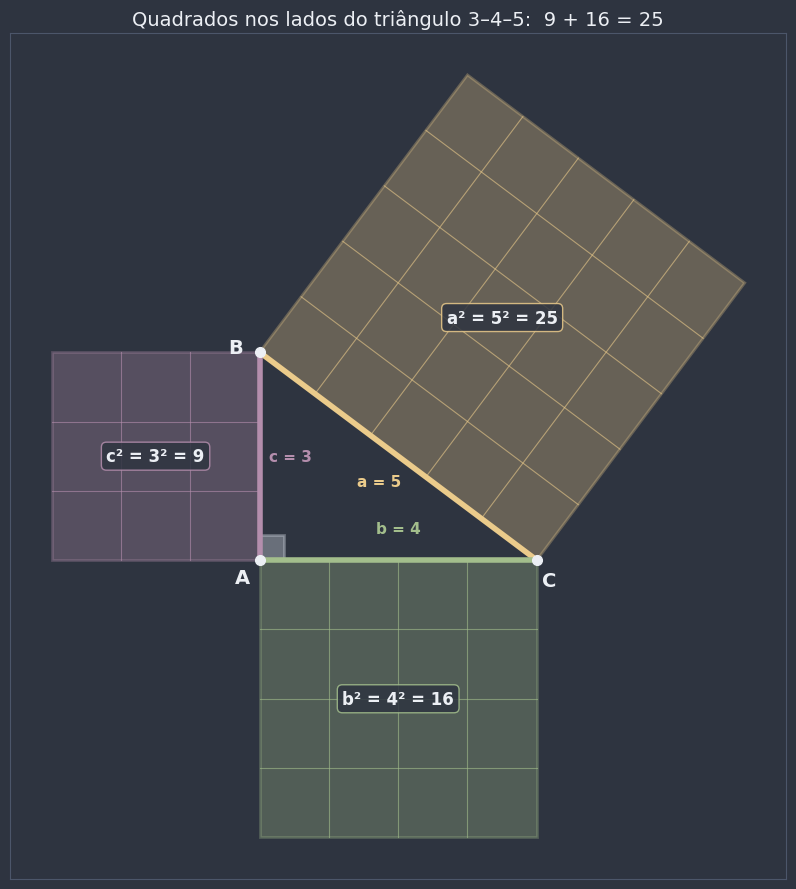

quadradinhos sobre o lado 3: 9,  sobre o lado 4: 16,  sobre o lado 5: 25
9 + 16 = 25  →  igual a 25? True


In [2]:
# O triângulo 3–4–5, com o ângulo reto em A, e um quadrado construído sobre cada lado
A_g, B_g, C_g = np.array([0.0, 0.0]), np.array([0.0, 3.0]), np.array([4.0, 0.0])
centro_g = (A_g + B_g + C_g) / 3

fig, ax = plt.subplots(figsize=(9, 9))
fig.patch.set_facecolor(NORD_FUNDO)
pontos_g = []
for P, Q, cor, nome in ((B_g, C_g, COR_HIPOTENUSA, "a"), (C_g, A_g, COR_CATETO_B, "b"), (A_g, B_g, COR_CATETO_C, "c")):
    lado = math.dist(P, Q)
    vertices = desenhar_quadrado_no_lado(ax, P, Q, centro_g, cor, quadricular=True,
                                         rotulo=f"{nome}² = {lado:g}² = {lado**2:g}")
    pontos_g += vertices
    desenhar_segmento(ax, P, Q, cor=cor, largura=4)
    rotular_segmento(ax, P, Q, f"{nome} = {lado:g}", cor=cor, distancia=0.45, longe_de=sum(vertices) / 4)
desenhar_arco(ax, A_g, B_g, C_g, raio=0.6, cor=NORD_TEXTO_SEC)
for X, nome in ((A_g, "A"), (B_g, "B"), (C_g, "C")):
    desenhar_ponto(ax, X, cor=NORD_TEXTO)
    rotular_fora(ax, X, nome, (2.5, 2.5), distancia=0.35, tamanho=14)
preparar_eixo(ax, pontos_g, margem=0.6)
ax.set_title("Quadrados nos lados do triângulo 3–4–5:  9 + 16 = 25", color=NORD_TEXTO, fontsize=14)
plt.tight_layout()
plt.show()

print(f"quadradinhos sobre o lado 3: {3**2},  sobre o lado 4: {4**2},  sobre o lado 5: {5**2}")
print(f"9 + 16 = {9 + 16}  →  igual a 25? {9 + 16 == 25}")

Conte os quadradinhos na figura: o quadrado roxo tem 9, o verde tem 16 e o amarelo tem 25. A notação já é a deste notebook inteiro: o ângulo reto fica em $A$, o lado oposto a ele é $a$ (amarelo) e os outros dois são $b$ (verde) e $c$ (roxo).

🕹️ **Widget interativo — a dobradiça:** agora os lados de 3 e 4 ficam presos no vértice de baixo, como uma **dobradiça**, e o slider `ângulo` abre ou fecha o ângulo entre eles (de 60° a 120°). O terceiro lado, $x$, é medido com as coordenadas. O painel da direita compara a soma $3^2 + 4^2 = 25$ (sempre a mesma!) com $x^2$ (o quadrado amarelo). Procure o ângulo em que as duas barras **empatam**. E observe o que acontece com $x^2$ quando o ângulo é **menor** ou **maior** que esse.

In [3]:
def explorar_dobradica(angulo: float) -> None:
    V = np.array([0.0, 0.0])  # o vértice da dobradiça
    C_w = np.array([4.0, 0.0])  # lado de 4, deitado
    B_w = 3 * direcao(angulo)  # lado de 3, aberto `angulo` graus
    x = math.dist(B_w, C_w)
    soma = 3**2 + 4**2
    empate = math.isclose(x**2, soma, abs_tol=1e-9)

    fig, (ax, ax_barras) = plt.subplots(1, 2, figsize=(15, 6.8), gridspec_kw={"width_ratios": [1.15, 1]})
    fig.patch.set_facecolor(NORD_FUNDO)
    centro = (V + B_w + C_w) / 3
    for P, Q, cor in ((B_w, C_w, COR_HIPOTENUSA), (C_w, V, COR_CATETO_B), (V, B_w, COR_CATETO_C)):
        desenhar_quadrado_no_lado(ax, P, Q, centro, cor, opacidade=0.28)
        desenhar_segmento(ax, P, Q, cor=cor, largura=3.5)
    rotular_segmento(ax, B_w, C_w, f"x = {x:.2f}", cor=COR_HIPOTENUSA, distancia=0.35, longe_de=(9, 9))
    desenhar_arco(ax, V, C_w, B_w, raio=0.6, cor=NORD_TEXTO_SEC, rotulo=f"{angulo:.0f}°", raio_rotulo=1.1)
    preparar_eixo(ax, [(-4.6, -4.4), (7.8, 8.6)], margem=0.2)
    ax.set_title("os lados de 3 e 4 fixos; o ângulo entre eles muda", color=NORD_TEXTO, fontsize=13)

    estilizar_eixo(ax_barras)
    ax_barras.barh(1, 9, color=COR_CATETO_C, alpha=0.85)
    ax_barras.barh(1, 16, left=9, color=COR_CATETO_B, alpha=0.85)
    ax_barras.barh(0, x**2, color=COR_HIPOTENUSA, alpha=0.85)
    ax_barras.axvline(soma, color=NORD_TEXTO_SEC, ls="--", lw=1.5)
    ax_barras.text(0.5, 1, "3² + 4² = 9 + 16 = 25", color=NORD_FUNDO, fontsize=12, fontweight="bold", va="center")
    ax_barras.text(0.5, 0, f"x² = {x**2:.2f}", color=NORD_FUNDO, fontsize=12, fontweight="bold", va="center")
    ax_barras.set_yticks([0, 1], ["terceiro lado²", "soma dos\noutros dois²"], color=NORD_TEXTO)
    ax_barras.set_xlim(0, 40)
    if empate:
        conclusao, cor_titulo = "x² = 3² + 4²: EMPATE (ângulo reto)", COR_DESTAQUE
    elif x**2 < soma:
        conclusao, cor_titulo = "x² < 3² + 4²: ângulo AGUDO", COR_AVISO
    else:
        conclusao, cor_titulo = "x² > 3² + 4²: ângulo OBTUSO", COR_ALERTA
    ax_barras.set_title(conclusao, color=cor_titulo, fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()


widgets.interact(
    explorar_dobradica,
    angulo=widgets.IntSlider(value=105, min=60, max=120, step=1, description="ângulo:"),
);

interactive(children=(IntSlider(value=105, description='ângulo:', max=120, min=60), Output()), _dom_classes=('…

O empate acontece **só em 90°**. Com o ângulo agudo, o terceiro lado é mais curto e $x^2 < 25$; com o ângulo obtuso, ele é mais comprido e $x^2 > 25$. Em uma única experiência, você acabou de descobrir **três** resultados deste notebook:

1. se o ângulo é reto, o quadrado do lado oposto é a soma dos quadrados dos outros dois (o **Teorema de Pitágoras**);
2. se essa igualdade vale, o ângulo é reto (a **recíproca**);
3. comparando $x^2$ com a soma, dá para saber se o ângulo é agudo ou obtuso **sem transferidor** (a **classificação pelos lados**, prometida em [`0404a_triangulos_conceito_elementos_e_classificacao.ipynb`](0404a_triangulos_conceito_elementos_e_classificacao.ipynb)).

Mas um experimento não é uma demonstração: o slider anda de 1° em 1°, e a tela mostra duas casas decimais. As provas chegam na seção 2.

### Um segundo problema: a TV de 55 polegadas

Quando uma loja anuncia "TV de **55 polegadas**", o número é a medida da **diagonal** da tela, e não da largura. As telas comuns têm proporção **16 : 9** (a largura está para a altura assim como 16 está para 9). **Quanto medem a largura e a altura de uma tela de 55"?** Será que ela cabe no rack de 1,20 m da sua sala?

Tente responder agora, com o que você já sabe. A resposta (com a conversão para centímetros) aparece na seção 4, e só precisa de duas ferramentas: semelhança e o triângulo retângulo escondido na tela.

### O fio condutor deste notebook

Os notebooks anteriores do módulo deixaram várias promessas para cá. O Teorema de Pitágoras já foi **usado** de forma antecipada, como conferência numérica, em [`0409a_paralelogramos_e_casos_particulares.ipynb`](0409a_paralelogramos_e_casos_particulares.ipynb) e [`0412a_circunferencia_e_circulo.ipynb`](0412a_circunferencia_e_circulo.ipynb); agora ele vai ser **demonstrado**, e a partir daqui vira ferramenta oficial. A cadeia de demonstrações é esta:

$$\text{Tales (0414a)} \;\longrightarrow\; \text{semelhança (0415a)} \;\longrightarrow\; \text{relações métricas (seção 1)} \;\longrightarrow\; \text{Pitágoras (seção 2)}$$

| Seção | A ideia em uma frase | Demonstrada com... |
|---|---|---|
| 1. Elementos e relações métricas | a altura relativa à hipotenusa divide o triângulo em dois triângulos semelhantes a ele | critério AA (0415a) e potência de ponto |
| 2. Pitágoras, recíproca e ternos | $a^2 = b^2 + c^2$, e só no triângulo retângulo | relações métricas, áreas e LLL (0405a) |
| 3. Triângulos notáveis | 45°–45°–90° e 30°–60°–90° têm lados "redondos" em $\sqrt{2}$ e $\sqrt{3}$ | Pitágoras na metade do quadrado e do equilátero |
| 4. Aplicações no plano | distâncias, diagonais, losango, trapézio, a TV | Pitágoras |
| 5. O triângulo retângulo e a circunferência | $R = \frac{a}{2}$, $r = \frac{b + c - a}{2}$, tangente, corda | Pitágoras e os notebooks 0410a, 0412a e 0413a |

## 1. Elementos e relações métricas

### Os elementos

Em todo este notebook, $ABC$ é um triângulo **retângulo em $A$**, e a notação é **fixa** (as cores também, em todas as figuras):

| Elemento | Nome | Medida | Cor |
|---|---|---|---|
| $\overline{BC}$, o lado oposto ao ângulo reto | **hipotenusa** | $a$ | amarelo |
| $\overline{CA}$ e $\overline{AB}$, os lados do ângulo reto | **catetos** | $b$ e $c$ | verde e roxo |
| $\overline{AH}$, com $H$ em $\overline{BC}$ e $\overline{AH} \perp \overline{BC}$ | **altura relativa à hipotenusa** | $h$ | laranja |
| $\overline{BH}$ | **projeção ortogonal** do cateto $c$ sobre a hipotenusa | $m$ | roxo (a cor de $c$) |
| $\overline{HC}$ | **projeção ortogonal** do cateto $b$ sobre a hipotenusa | $n$ | verde (a cor de $b$) |

A projeção ortogonal é a de [`0407a_perpendicularidade.ipynb`](0407a_perpendicularidade.ipynb): projetar o cateto $\overline{AB}$ sobre a reta $BC$ é "derrubar" a perpendicular por $A$, e o que sobra na reta é $\overline{BH}$. Como $H$ fica **entre** $B$ e $C$ (os ângulos $\hat{B}$ e $\hat{C}$ são agudos, [`0404a_triangulos_conceito_elementos_e_classificacao.ipynb`](0404a_triangulos_conceito_elementos_e_classificacao.ipynb)), vale

$$m + n = a.$$

### Os três triângulos semelhantes

A altura $\overline{AH}$ corta o triângulo $ABC$ em dois triângulos menores, $HBA$ e $HAC$, os dois **retângulos em $H$**. Este é o teaser de [`0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb`](0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb), agora demonstrado:

| Passo | Afirmação | Justificativa |
|---|---|---|
| 1 | $\triangle ABC \sim \triangle HBA$ | os dois têm um ângulo reto ($\hat{A}$ e $\hat{H}$) e o ângulo $\hat{B}$ é **comum**: critério **AA** |
| 2 | $\triangle ABC \sim \triangle HAC$ | um ângulo reto em cada ($\hat{A}$ e $\hat{H}$) e o ângulo $\hat{C}$ **comum**: critério **AA** |
| 3 | $\triangle HBA \sim \triangle HAC$ | os dois são semelhantes ao mesmo triângulo $ABC$ (a semelhança é transitiva) |

Atenção à **ordem das letras**, que diz quem corresponde a quem: em $\triangle ABC \sim \triangle HBA$, o vértice $A$ (reto) corresponde a $H$ (reto), $B$ corresponde a $B$ e $C$ corresponde a $A$. Por isso o ângulo $B\hat{A}H$ é igual a $\hat{C}$, e o ângulo $H\hat{A}C$ é igual a $\hat{B}$.

### As relações métricas

Cada semelhança dá uma proporção entre **lados homólogos** (opostos a ângulos iguais, [`0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb`](0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb)). Escolhendo bem os pares, saem quatro relações:

| Relação | De qual semelhança | A proporção | Multiplicando "em cruz" |
|---|---|---|---|
| 1 | $\triangle ABC \sim \triangle HBA$ | $\dfrac{BC}{BA} = \dfrac{BA}{BH}$, isto é, $\dfrac{a}{c} = \dfrac{c}{m}$ | $c^2 = a \cdot m$ |
| 2 | $\triangle ABC \sim \triangle HAC$ | $\dfrac{BC}{AC} = \dfrac{AC}{HC}$, isto é, $\dfrac{a}{b} = \dfrac{b}{n}$ | $b^2 = a \cdot n$ |
| 3 | $\triangle HBA \sim \triangle HAC$ | $\dfrac{HB}{HA} = \dfrac{HA}{HC}$, isto é, $\dfrac{m}{h} = \dfrac{h}{n}$ | $h^2 = m \cdot n$ |
| 4 | $\triangle ABC \sim \triangle HBA$ | $\dfrac{AC}{HA} = \dfrac{BC}{BA}$, isto é, $\dfrac{b}{h} = \dfrac{a}{c}$ | $b \cdot c = a \cdot h$ |

📌 **Definição formal (relações métricas no triângulo retângulo):** se $ABC$ é retângulo em $A$, com hipotenusa $a$, catetos $b$ e $c$, altura relativa à hipotenusa $h$ e projeções $m$ (de $c$) e $n$ (de $b$), então

$$c^2 = a \cdot m \qquad b^2 = a \cdot n \qquad h^2 = m \cdot n \qquad b \cdot c = a \cdot h \qquad \left(\text{e daí } h = \frac{b \cdot c}{a}\right).$$

💡 **Dica de memória:** "**cateto ao quadrado é hipotenusa vezes a projeção dele**" e "**altura ao quadrado é projeção vezes projeção**". A relação 3 diz que a altura é a **média geométrica** das projeções, $h = \sqrt{m \cdot n}$: a mesma média geométrica da PG em [`0303a_progressao_geometrica.ipynb`](../03_progressoes_matrizes_e_sistemas_lineares/0303a_progressao_geometrica.ipynb) ($m$, $h$, $n$ formam uma PG!) e a mesma construção de $\sqrt{a \cdot b}$ do Desafio 7 de [`0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb`](0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb).

**No código:** a primeira célula definiu `elementos(A, B, C)`, que calcula $a$, $b$, $c$, o pé $H$ (com `pe_da_altura`, a projeção ortogonal de [`0407a_perpendicularidade.ipynb`](0407a_perpendicularidade.ipynb)), $h$, $m$ e $n$. A célula abaixo usa o triângulo $B = (0, 0)$, $C = (25, 0)$, $A = (9, 12)$, confere as quatro relações e pede a `criterios_semelhanca` (de 0415a) que confirme as três semelhanças, sempre com os vértices **na ordem da correspondência**.

In [4]:
A1, B1, C1 = np.array([9.0, 12.0]), np.array([0.0, 0.0]), np.array([25.0, 0.0])
el1 = elementos(A1, B1, C1)
H1 = el1["H"]
print(f"ângulo em A: {medir_angulo(A1, B1, C1):.4f}°  (retângulo em A)")
print(f"a = {el1['a']:g},  b = {el1['b']:g},  c = {el1['c']:g}")
print(f"H = ({H1[0]:g}, {H1[1]:g}),  h = {el1['h']:g}  (distância de A à reta BC: "
      f"{distancia_ponto_reta(A1, B1, C1):g}),  m = {el1['m']:g},  n = {el1['n']:g}")

relacoes = [
    ("1. c² = a·m", el1["c"] ** 2, el1["a"] * el1["m"]),
    ("2. b² = a·n", el1["b"] ** 2, el1["a"] * el1["n"]),
    ("3. h² = m·n", el1["h"] ** 2, el1["m"] * el1["n"]),
    ("4. b·c = a·h", el1["b"] * el1["c"], el1["a"] * el1["h"]),
    ("   m + n = a", el1["m"] + el1["n"], el1["a"]),
]
display(pd.DataFrame([{"relação": nome, "lado esquerdo": f"{x:g}", "lado direito": f"{y:g}",
                       "confere?": "✅" if iguais(x, y) else "❌"} for nome, x, y in relacoes]))

print("ABC ~ HBA:", criterios_semelhanca([A1, B1, C1], [H1, B1, A1]))
print("ABC ~ HAC:", criterios_semelhanca([A1, B1, C1], [H1, A1, C1]))
print("HBA ~ HAC:", criterios_semelhanca([H1, B1, A1], [H1, A1, C1]))

ângulo em A: 90.0000°  (retângulo em A)
a = 25,  b = 20,  c = 15
H = (9, 0),  h = 12  (distância de A à reta BC: 12),  m = 9,  n = 16


,relação,lado esquerdo,lado direito,confere?
0,1. c² = a·m,225,225,✅
1,2. b² = a·n,400,400,✅
2,3. h² = m·n,144,144,✅
3,4. b·c = a·h,300,300,✅
4,m + n = a,25,25,✅


ABC ~ HBA: ['AA', 'LAL', 'LLL']
ABC ~ HAC: ['AA', 'LAL', 'LLL']
HBA ~ HAC: ['AA', 'LAL', 'LLL']


Tudo confere, com números inteiros: $15^2 = 225 = 25 \cdot 9$, $20^2 = 400 = 25 \cdot 16$, $12^2 = 144 = 9 \cdot 16$ e $20 \cdot 15 = 300 = 25 \cdot 12$. Os três pares passam nos três critérios de semelhança.

A representação gráfica. À esquerda, a figura padrão do notebook: cada cateto e a **sua** projeção na mesma cor ($c$ e $m$ roxos, $b$ e $n$ verdes), as projeções desenhadas como "réguas" abaixo da hipotenusa. À direita, os três triângulos **desmontados** e colocados na mesma posição (ângulo reto embaixo à esquerda, o ângulo igual a $\hat{B}$ marcado em azul): fica visível que são o **mesmo formato** em três tamanhos.

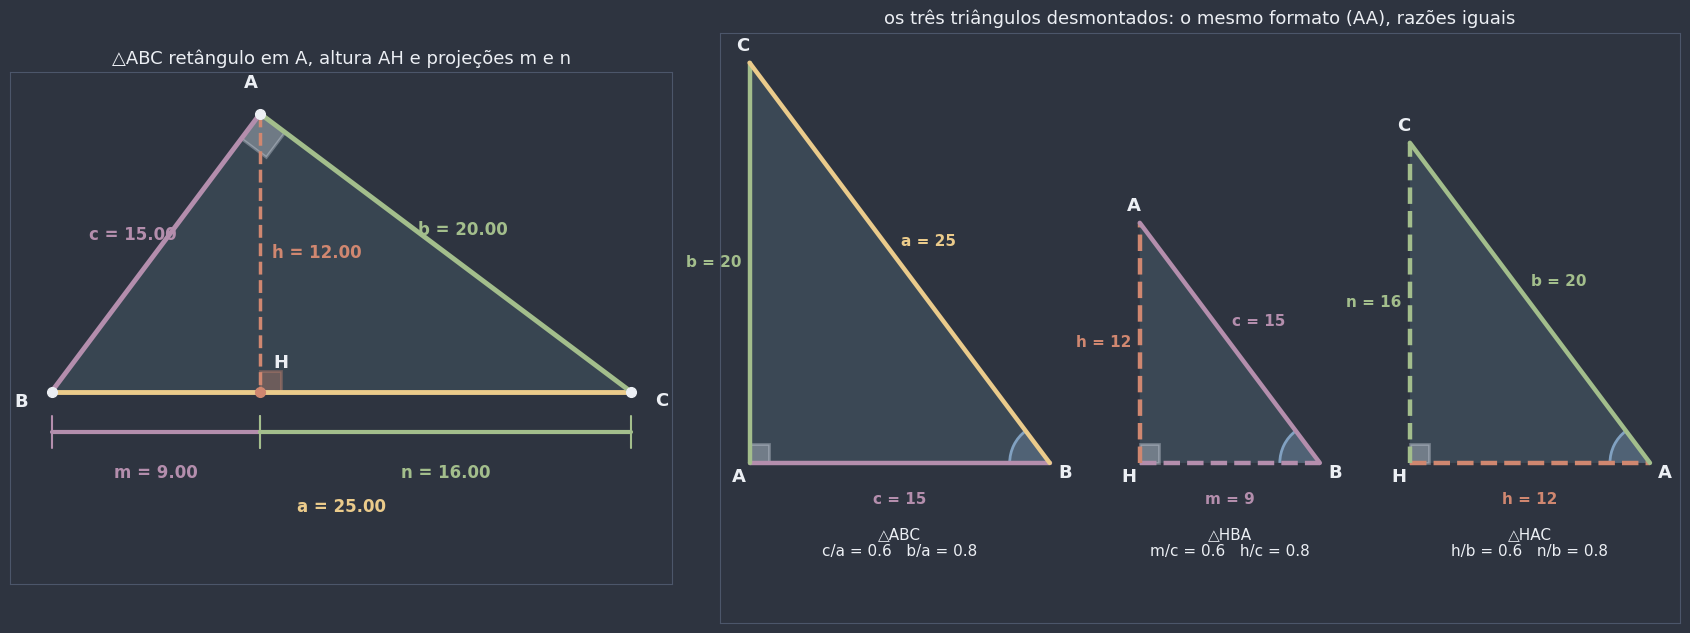

In [5]:
def posicao_padrao(cateto_adjacente: float, cateto_oposto: float, origem) -> list[np.ndarray]:
    """Triângulo retângulo com o ângulo reto em `origem`, o cateto adjacente ao ângulo marcado deitado (para a
    direita) e o cateto oposto em pé (para cima). Devolve [vértice reto, vértice do ângulo marcado, terceiro]."""
    O = np.asarray(origem, dtype=float)
    return [O, O + (cateto_adjacente, 0.0), O + (0.0, cateto_oposto)]


fig, (ax_fig, ax_desm) = plt.subplots(1, 2, figsize=(17, 6.8), gridspec_kw={"width_ratios": [1, 1.45]})
fig.patch.set_facecolor(NORD_FUNDO)
desenhar_elementos(ax_fig, A1, B1, C1)
preparar_eixo(ax_fig, [A1, B1, C1, (12.5, -6.5)], margem=1.8)
ax_fig.set_title("△ABC retângulo em A, altura AH e projeções m e n", color=NORD_TEXTO, fontsize=13)

a, b, c, h, m, n = (el1[k] for k in ("a", "b", "c", "h", "m", "n"))
# (nome, catetos (adjacente ao ângulo igual a B̂, oposto), hipotenusa, cores e rótulos de cada lado)
pecas = [
    ("△ABC", (c, b), a, (COR_CATETO_C, COR_CATETO_B, COR_HIPOTENUSA), ("c", "b", "a"), ("A", "B", "C")),
    ("△HBA", (m, h), c, (COR_CATETO_C, COR_ALTURA, COR_CATETO_C), ("m", "h", "c"), ("H", "B", "A")),
    ("△HAC", (h, n), b, (COR_ALTURA, COR_CATETO_B, COR_CATETO_B), ("h", "n", "b"), ("H", "A", "C")),
]
x0 = 0.0
pontos_desm = []
for nome, (adj, op), hip, cores, rotulos, vertices in pecas:
    R, P, Q = posicao_padrao(adj, op, (x0, 0.0))
    ax_desm.add_patch(Polygon([R, P, Q], closed=True, facecolor=COR_TRIANGULO, alpha=0.15, edgecolor="none"))
    for (X, Y), cor, rotulo, medida in zip(((R, P), (R, Q), (P, Q)), cores, rotulos, (adj, op, hip)):
        estilo = "--" if rotulo in ("m", "n", "h") else "-"
        desenhar_segmento(ax_desm, X, Y, cor=cor, largura=3.2, estilo=estilo)
        rotular_segmento(ax_desm, X, Y, f"{rotulo} = {medida:g}", cor=cor, distancia=1.8,
                         longe_de=(R + P + Q) / 3)
    desenhar_arco(ax_desm, R, P, Q, raio=1.6, cor=NORD_TEXTO_SEC)
    desenhar_arco(ax_desm, P, R, Q, raio=2.0, cor=COR_SECUNDARIA)
    for X, letra in zip((R, P, Q), vertices):
        rotular_fora(ax_desm, X, letra, (R + P + Q) / 3, distancia=0.9, tamanho=13)
    ax_desm.text(x0 + adj / 2, -3.2, f"{nome}\n{rotulos[0]}/{rotulos[2]} = {adj / hip:g}   "
                 f"{rotulos[1]}/{rotulos[2]} = {op / hip:g}", color=NORD_TEXTO, fontsize=11, ha="center", va="top")
    pontos_desm += [R, P, Q]
    x0 += adj + 4.5
preparar_eixo(ax_desm, pontos_desm + [np.array([0.0, -6.5])], margem=1.5)
ax_desm.set_title("os três triângulos desmontados: o mesmo formato (AA), razões iguais", color=NORD_TEXTO,
                  fontsize=13)
plt.tight_layout()
plt.show()

Nas três peças, "cateto adjacente ÷ hipotenusa" vale 0,6 e "cateto oposto ÷ hipotenusa" vale 0,8: é a proporção entre lados homólogos. As relações métricas são só essas igualdades de razões, com os denominadores multiplicados "em cruz". Repare também nas peças da direita: a altura $h$ (laranja) aparece **duas vezes**, uma como cateto "em pé" de $HBA$ e outra como cateto "deitado" de $HAC$. É por isso que ela é a média geométrica de $m$ e $n$.

🕹️ **Widget interativo:** o slider `posição` move o vértice $A$ ao longo da **semicircunferência de diâmetro $BC$** (pontilhada), com $a = 10$ fixo. Pelo [`0413a_angulos_na_circunferencia.ipynb`](0413a_angulos_na_circunferencia.ipynb), todo ponto dessa semicircunferência enxerga $\overline{BC}$ sob um ângulo **reto**: o triângulo continua retângulo em $A$ o tempo todo. O painel recalcula as quatro relações (e a média geométrica) em tempo real. Leve $A$ para perto de $B$: o que acontece com $m$, $h$ e $n$? E quando $A$ está no ponto mais alto?

In [6]:
def explorar_relacoes(posicao: float) -> None:
    A_w, B_w, C_w = triangulo_retangulo(10.0, posicao)
    el = elementos(A_w, B_w, C_w)
    a, b, c, h, m, n = (el[k] for k in ("a", "b", "c", "h", "m", "n"))

    fig, (ax, ax_lista) = plt.subplots(1, 2, figsize=(15, 6.4), gridspec_kw={"width_ratios": [1.35, 1]})
    fig.patch.set_facecolor(NORD_FUNDO)
    ax.add_patch(Arc((5, 0), 10, 10, theta1=0, theta2=180, color=COR_CIRCULO, lw=1.5, ls=":"))
    desenhar_elementos(ax, A_w, B_w, C_w, tamanho=11)
    preparar_eixo(ax, [(-0.5, -2.6), (10.5, 5.6)], margem=0.6)
    ax.set_title(f"A na semicircunferência de diâmetro BC (posição {posicao:.0f}°)", color=NORD_TEXTO, fontsize=13)
    itens = [
        (f"Â = {medir_angulo(A_w, B_w, C_w):.2f}°", math.isclose(medir_angulo(A_w, B_w, C_w), 90, abs_tol=1e-6)),
        (f"c² = {c**2:.3f}   a·m = {a * m:.3f}", iguais(c**2, a * m)),
        (f"b² = {b**2:.3f}   a·n = {a * n:.3f}", iguais(b**2, a * n)),
        (f"h² = {h**2:.3f}   m·n = {m * n:.3f}", iguais(h**2, m * n)),
        (f"b·c = {b * c:.3f}   a·h = {a * h:.3f}", iguais(b * c, a * h)),
        (f"h = {h:.3f} = √(m·n) = {math.sqrt(m * n):.3f}  (média geométrica)", iguais(h, math.sqrt(m * n))),
        (f"m + n = {m + n:.3f} = a", iguais(m + n, a)),
    ]
    escrever_checklist(ax_lista, itens, "As relações métricas")
    plt.tight_layout()
    plt.show()


widgets.interact(
    explorar_relacoes,
    posicao=widgets.IntSlider(value=125, min=15, max=165, step=1, description="posição:"),
);

interactive(children=(IntSlider(value=125, description='posição:', max=165, min=15), Output()), _dom_classes=(…

### Fechando o teaser de 0415a: duas demonstrações de $h^2 = m \cdot n$

A relação 3 já tinha aparecido em [`0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb`](0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb), por um caminho completamente diferente. As duas demonstrações, lado a lado:

| | Por semelhança | Por potência de ponto |
|---|---|---|
| Ideia | $\triangle HBA \sim \triangle HAC$ (AA) | $A$ está na circunferência de diâmetro $\overline{BC}$ ([`0413a_angulos_na_circunferencia.ipynb`](0413a_angulos_na_circunferencia.ipynb)) |
| Passo-chave | lados homólogos: $\dfrac{HB}{HA} = \dfrac{HA}{HC}$ | prolongando $\overline{AH}$ até cortar a circunferência em $A'$, a corda $\overline{AA'}$ é perpendicular ao diâmetro, então $H$ é o seu ponto médio ([`0412a_circunferencia_e_circulo.ipynb`](0412a_circunferencia_e_circulo.ipynb)): $HA = HA' = h$ |
| Conclusão | $\dfrac{m}{h} = \dfrac{h}{n}$, logo $h^2 = m \cdot n$ | duas cordas que se cortam em $H$: $HB \cdot HC = HA \cdot HA'$, logo $m \cdot n = h \cdot h$ |

Dois caminhos independentes, a mesma conclusão. A figura abaixo mostra as duas leituras no triângulo da célula anterior.

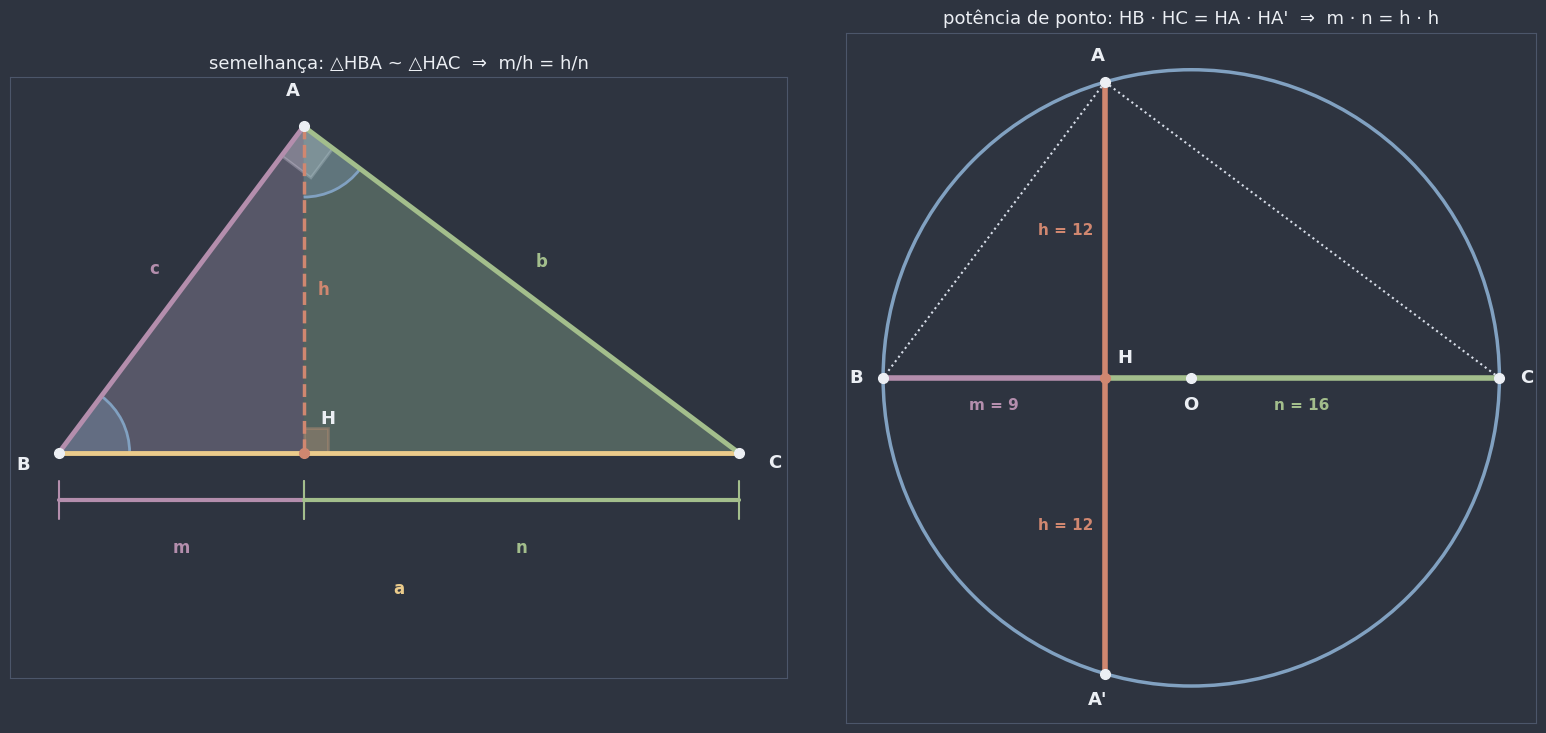

HB · HC = 144,  HA · HA' = 144,  Pot(H) = OH² − r² = -144


In [7]:
fig, (ax_s, ax_p) = plt.subplots(1, 2, figsize=(16, 7.4))
fig.patch.set_facecolor(NORD_FUNDO)

# Por semelhança: os triângulos HBA e HAC sombreados
desenhar_elementos(ax_s, A1, B1, C1, valores=False)
ax_s.add_patch(Polygon([H1, B1, A1], closed=True, facecolor=COR_CATETO_C, alpha=0.25, edgecolor="none"))
ax_s.add_patch(Polygon([H1, A1, C1], closed=True, facecolor=COR_CATETO_B, alpha=0.25, edgecolor="none"))
desenhar_arco(ax_s, B1, H1, A1, raio=2.6, cor=COR_SECUNDARIA)
desenhar_arco(ax_s, A1, H1, C1, raio=2.6, cor=COR_SECUNDARIA)
preparar_eixo(ax_s, [A1, B1, C1, (12.5, -6.5)], margem=1.8)
ax_s.set_title("semelhança: △HBA ~ △HAC  ⇒  m/h = h/n", color=NORD_TEXTO, fontsize=13)

# Por potência de ponto: as cordas BC e AA' se cortam em H
O1, r1 = ponto_medio(B1, C1), el1["a"] / 2
A_linha = np.array([A1[0], -A1[1]])  # o simétrico de A em relação ao diâmetro BC
desenhar_circunferencia(ax_p, O1, r1, cor=COR_CIRCULO)
desenhar_segmento(ax_p, B1, H1, cor=COR_CATETO_C, largura=4)
desenhar_segmento(ax_p, H1, C1, cor=COR_CATETO_B, largura=4)
desenhar_segmento(ax_p, A1, A_linha, cor=COR_ALTURA, largura=4)
desenhar_segmento(ax_p, A1, B1, cor=NORD_TEXTO_SEC, largura=1.5, estilo=":")
desenhar_segmento(ax_p, A1, C1, cor=NORD_TEXTO_SEC, largura=1.5, estilo=":")
for X, nome in ((A1, "A"), (B1, "B"), (C1, "C"), (A_linha, "A'"), (O1, "O")):
    desenhar_ponto(ax_p, X, cor=NORD_TEXTO)
    rotular_fora(ax_p, X, nome, O1 + (0, 0.01), distancia=1.1, tamanho=13)
desenhar_ponto(ax_p, H1, "H", cor=COR_ALTURA, deslocamento=(0.5, 0.6))
for P, Q, texto, cor in ((B1, H1, f"m = {el1['m']:g}", COR_CATETO_C), (H1, C1, f"n = {el1['n']:g}", COR_CATETO_B)):
    rotular_segmento(ax_p, P, Q, texto, cor=cor, distancia=1.1, longe_de=A1)
rotular_segmento(ax_p, A1, H1, f"h = {el1['h']:g}", cor=COR_ALTURA, distancia=1.6, longe_de=C1)
rotular_segmento(ax_p, H1, A_linha, f"h = {math.dist(H1, A_linha):g}", cor=COR_ALTURA, distancia=1.6, longe_de=C1)
preparar_eixo(ax_p, [(O1[0] - r1, -r1), (O1[0] + r1, r1)], margem=1.5)
ax_p.set_title("potência de ponto: HB · HC = HA · HA'  ⇒  m · n = h · h", color=NORD_TEXTO, fontsize=13)
plt.tight_layout()
plt.show()

pot_H = math.dist(O1, H1) ** 2 - r1**2
print(f"HB · HC = {el1['m'] * el1['n']:g},  HA · HA' = {math.dist(H1, A1) * math.dist(H1, A_linha):g},  "
      f"Pot(H) = OH² − r² = {pot_H:g}")

A potência de $H$ é $-144$: negativa porque $H$ está **dentro** da circunferência, e com valor absoluto $m \cdot n = h^2 = 144$, exatamente como em [`0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb`](0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb).

⚠️ **Erro comum: trocar $m$ e $n$.** A projeção de $c$ é $m$, e ela fica **do lado de $B$** (o cateto $c = AB$ "cai" sobre $\overline{BH}$); a projeção de $b$ é $n$, do lado de $C$. A relação é sempre **cateto com a projeção dele mesmo**: $c^2 = a \cdot m$ e $b^2 = a \cdot n$. Quem escreve $c^2 = a \cdot n$ erra a conta (no exemplo, daria $225 = 25 \cdot 16 = 400$, falso). Por isso as figuras pintam cada cateto e a sua projeção da **mesma cor**: faça o mesmo nos seus rascunhos.

⚠️ **Erro comum: usar $h$ como se fosse um cateto.** A altura relativa à hipotenusa é **interna** ao triângulo e é **menor** que os dois catetos (ela é cateto dos triângulos menores, cujas hipotenusas são $b$ e $c$).

📖 **Leitura complementar:** [Triângulo retângulo](https://pt.wikipedia.org/wiki/Tri%C3%A2ngulo_ret%C3%A2ngulo) (Wikipédia) e, para quem lê em inglês, [Geometric mean theorem](https://en.wikipedia.org/wiki/Geometric_mean_theorem), o nome que a relação $h^2 = m \cdot n$ recebe em inglês.

**Pergunta de checagem:** em um triângulo retângulo, as projeções dos catetos sobre a hipotenusa medem 4 e 9. Quanto medem a altura relativa à hipotenusa e a hipotenusa?

**Pergunta de checagem:** no widget, quando $A$ se aproxima de $B$, o que acontece com $m$, com $h$ e com $n$? As relações continuam valendo no limite?

## 2. O Teorema de Pitágoras, a recíproca e os ternos

📌 **Teorema de Pitágoras:** em todo triângulo retângulo, o quadrado da hipotenusa é igual à soma dos quadrados dos catetos:

$$a^2 = b^2 + c^2.$$

### Demonstração 1: um corolário das relações métricas

As relações 1 e 2 da seção 1 dizem que $c^2 = a \cdot m$ e $b^2 = a \cdot n$. Somando as duas:

$$b^2 + c^2 = a \cdot n + a \cdot m = a\,(m + n) = a \cdot a = a^2. \qquad \blacksquare$$

Três linhas. O teorema mais famoso da geometria "cai" das relações métricas, que caíram da semelhança, que caiu de Tales. É a cadeia anunciada no gancho.

### Demonstração 2: por áreas (a demonstração visual)

Desenhe um quadrado de lado $b + c$ e arrume **quatro cópias** do triângulo retângulo (catetos $b$ e $c$, hipotenusa $a$) dentro dele, de duas maneiras:

- **disposição (i):** um triângulo em cada canto, com as hipotenusas viradas para dentro. O que sobra no meio é um **quadrado de lado $a$** (os seus ângulos são retos porque, em cada lado do quadrado grande, os dois ângulos agudos dos triângulos somam 90°: $\hat{B} + \hat{C} = 90°$, [`0404a_triangulos_conceito_elementos_e_classificacao.ipynb`](0404a_triangulos_conceito_elementos_e_classificacao.ipynb)).
- **disposição (ii):** os quatro triângulos juntados dois a dois, formando **dois retângulos** $b \times c$ em cantos opostos. O que sobra são **dois quadrados**, de lados $b$ e $c$.

O quadrado grande é o mesmo, e os quatro triângulos são os mesmos (só foram **deslizados**, sem girar nem deformar). Retirando partes iguais de áreas iguais, sobram áreas iguais: $a^2 = b^2 + c^2$. $\blacksquare$

(Só usamos a área de um quadrado, lado × lado, e a ideia de "retirar partes iguais". O estudo geral de áreas é tema de [`0420a_areas_de_superficies_planas.ipynb`](0420a_areas_de_superficies_planas.ipynb).)

🕹️ **Widget interativo — a prova em movimento:** o slider `t` desliza os quatro triângulos da disposição (i) ($t = 0$) até a disposição (ii) ($t = 1$); os sliders `b` e `c` mudam os catetos. As áreas que sobram aparecem pintadas nas duas posições extremas. Confira que nenhum triângulo gira no caminho: cada um só **desliza**.

In [8]:
def posicoes_prova_por_areas(b: float, c: float):
    """Os quatro triângulos retângulos de catetos b e c dentro do quadrado de lado b + c, na disposição (i), e o
    deslocamento que leva cada um à disposição (ii). Cada triângulo é [vértice reto, ponta do cateto b, ponta do
    cateto c]; os deslocamentos são translações (os triângulos não giram)."""
    s = b + c
    triangulos = [
        np.array([[0, 0], [b, 0], [0, c]], dtype=float),
        np.array([[s, 0], [s, b], [b, 0]], dtype=float),
        np.array([[s, s], [c, s], [s, b]], dtype=float),
        np.array([[0, s], [0, c], [c, s]], dtype=float),
    ]
    deslocamentos = [np.array([c, 0.0]), np.array([-b, c]), np.array([0.0, -b]), np.array([0.0, 0.0])]
    return triangulos, deslocamentos


def explorar_prova_por_areas(t: float, b: float, c: float) -> None:
    s = b + c
    a = math.sqrt(b**2 + c**2)  # (só para escrever o valor no painel; a figura não usa a)
    triangulos, deslocamentos = posicoes_prova_por_areas(b, c)

    fig, (ax, ax_lista) = plt.subplots(1, 2, figsize=(15, 6.8), gridspec_kw={"width_ratios": [1, 1.05]})
    fig.patch.set_facecolor(NORD_FUNDO)
    ax.add_patch(Rectangle((0, 0), s, s, fill=False, edgecolor=NORD_TEXTO, lw=2.5))
    if math.isclose(t, 0):
        meio = [(b, 0), (s, b), (c, s), (0, c)]
        ax.add_patch(Polygon(meio, closed=True, facecolor=COR_HIPOTENUSA, alpha=0.35, edgecolor="none"))
        ax.text(s / 2, s / 2, "a²", color=COR_HIPOTENUSA, fontsize=20, fontweight="bold", ha="center", va="center")
    if math.isclose(t, 1):
        ax.add_patch(Rectangle((0, 0), c, c, facecolor=COR_CATETO_C, alpha=0.35, edgecolor="none"))
        ax.add_patch(Rectangle((c, c), b, b, facecolor=COR_CATETO_B, alpha=0.35, edgecolor="none"))
        ax.text(c / 2, c / 2, "c²", color=COR_CATETO_C, fontsize=20, fontweight="bold", ha="center", va="center")
        ax.text(c + b / 2, c + b / 2, "b²", color=COR_CATETO_B, fontsize=20, fontweight="bold", ha="center",
                va="center")
    for tri, desl in zip(triangulos, deslocamentos):
        R, Pb, Pc = tri + t * desl
        ax.add_patch(Polygon([R, Pb, Pc], closed=True, facecolor=COR_TRIANGULO, alpha=0.45, edgecolor="none"))
        desenhar_segmento(ax, R, Pb, cor=COR_CATETO_B, largura=2.5)
        desenhar_segmento(ax, R, Pc, cor=COR_CATETO_C, largura=2.5)
        desenhar_segmento(ax, Pb, Pc, cor=COR_HIPOTENUSA, largura=2.5)
    preparar_eixo(ax, [(0, 0), (s, s)], margem=0.4)
    nome = "(i)" if math.isclose(t, 0) else ("(ii)" if math.isclose(t, 1) else "deslizando...")
    ax.set_title(f"quadrado de lado b + c = {s:g}   {nome}", color=NORD_TEXTO, fontsize=13)

    itens = [
        (f"quadrado grande: (b + c)² = {s:g}² = {s**2:g}", True),
        (f"4 triângulos: 4 · (b·c/2) = 2bc = {2 * b * c:g}", True),
        (f"sobra em (i): a² = {s**2:g} − {2 * b * c:g} = {s**2 - 2 * b * c:g}", True),
        (f"sobra em (ii): b² + c² = {b**2:g} + {c**2:g} = {b**2 + c**2:g}", True),
        (f"logo a² = b² + c²  e  a = {a:.4f}", iguais(s**2 - 2 * b * c, b**2 + c**2)),
    ]
    escrever_checklist(ax_lista, itens, "A mesma área, contada de dois jeitos")
    plt.tight_layout()
    plt.show()


widgets.interact(
    explorar_prova_por_areas,
    t=widgets.FloatSlider(value=0.0, min=0.0, max=1.0, step=0.1, description="t:"),
    b=widgets.FloatSlider(value=4.0, min=1.0, max=6.0, step=0.5, description="b:"),
    c=widgets.FloatSlider(value=3.0, min=1.0, max=6.0, step=0.5, description="c:"),
);

interactive(children=(FloatSlider(value=0.0, description='t:', max=1.0), FloatSlider(value=4.0, description='b…

A área de cada triângulo é $\frac{b \cdot c}{2}$ porque ele é **metade** de um retângulo $b \times c$ cortado pela diagonal (as duas metades são congruentes por LLL, [`0405a_congruencia_de_triangulos.ipynb`](0405a_congruencia_de_triangulos.ipynb)). A disposição (ii) mostra isso: cada retângulo do canto é formado por dois triângulos.

🕵️ **Curiosidade histórica:** o teorema leva o nome de **Pitágoras de Samos** (século VI a.C.), mas a relação é **bem mais antiga**. Uma tábua de argila babilônica, a **Plimpton 322** (de cerca de 1800 a.C.), traz uma tabela de números que, segundo a interpretação aceita por muitos historiadores, são lados de triângulos retângulos com medidas inteiras. Também não se sabe se o próprio Pitágoras deu uma demonstração: os registros sobre ele foram escritos séculos depois. Desde então, o teorema ganhou **centenas** de demonstrações diferentes; um livro de 1940, *The Pythagorean Proposition*, de E. S. Loomis, reúne mais de 350. Uma delas é de **James Garfield**, que anos depois seria presidente dos Estados Unidos: em 1876, quando era deputado, ele publicou uma prova que usa um **trapézio** formado por dois triângulos retângulos e um triângulo isósceles (é a metade da figura (i)!).

### A recíproca

📌 **Recíproca do Teorema de Pitágoras:** se os lados de um triângulo satisfazem $a^2 = b^2 + c^2$, então o triângulo é **retângulo** (e o ângulo reto é o oposto ao lado $a$).

*Demonstração.* Seja $ABC$ um triângulo com $BC = a$, $CA = b$, $AB = c$ e $a^2 = b^2 + c^2$. Construa **outro** triângulo, $A'B'C'$, com um ângulo reto em $A'$ e catetos $A'C' = b$ e $A'B' = c$. Pelo Teorema de Pitágoras (já demonstrado), a hipotenusa dele mede $B'C' = \sqrt{b^2 + c^2} = \sqrt{a^2} = a$. Então os dois triângulos têm os **três lados iguais** ($a$, $b$, $c$) e são congruentes pelo caso **LLL** ([`0405a_congruencia_de_triangulos.ipynb`](0405a_congruencia_de_triangulos.ipynb)). Ângulos correspondentes de triângulos congruentes são iguais: $\hat{A} = \hat{A'} = 90°$. $\blacksquare$

### Classificação do triângulo pelos lados

Cumprindo a promessa de [`0404a_triangulos_conceito_elementos_e_classificacao.ipynb`](0404a_triangulos_conceito_elementos_e_classificacao.ipynb): sendo $a$ o **maior** lado de um triângulo de lados $a$, $b$, $c$,

📌 **Definição formal (classificação quanto aos ângulos, pelos lados):**

| Comparação | Classificação |
|---|---|
| $a^2 < b^2 + c^2$ | **acutângulo** (o maior ângulo é agudo) |
| $a^2 = b^2 + c^2$ | **retângulo** |
| $a^2 > b^2 + c^2$ | **obtusângulo** (o maior ângulo é obtuso) |

O caso do meio é Pitágoras com a sua recíproca. Os outros dois são a **dobradiça** do gancho: fixando $b$ e $c$ e abrindo o ângulo entre eles, o lado oposto só **cresce**, e ele é igual a $\sqrt{b^2 + c^2}$ exatamente em 90°. Ângulo menor, lado menor; ângulo maior, lado maior. A demonstração rigorosa dos casos agudo e obtuso usa projeções e fica para [`0417a_triangulos_quaisquer.ipynb`](0417a_triangulos_quaisquer.ipynb); aqui ela é **verificada numericamente**.

Por que comparar com o **maior** lado? Porque o maior ângulo é oposto ao maior lado ([`0404a_triangulos_conceito_elementos_e_classificacao.ipynb`](0404a_triangulos_conceito_elementos_e_classificacao.ipynb)), e um triângulo é obtusângulo ou retângulo conforme o seu **maior** ângulo.

**No código:** `classifica_por_lados(x, y, z)` aceita as medidas em qualquer ordem: ordena, testa a **desigualdade triangular** antes de tudo (o maior lado tem de ser menor que a soma dos outros dois) e compara $a^2$ com $b^2 + c^2$ usando `math.isclose`, porque medidas com casas decimais (como 0,3; 0,4; 0,5) quase nunca dão uma igualdade **exata** no computador. A coluna "maior ângulo (medido)" confere a resposta com o transferidor digital, construindo o triângulo pelos lados.

In [9]:
def classifica_por_lados(x: float, y: float, z: float) -> str:
    """Classifica o triângulo de lados x, y, z (em qualquer ordem) quanto aos ângulos, só pelos lados:
    'acutângulo', 'retângulo', 'obtusângulo' ou 'não forma triângulo'."""
    a, b, c = sorted((x, y, z), reverse=True)  # a é o MAIOR lado
    if c <= 0 or a >= b + c:  # desigualdade triangular (0404a)
        return "não forma triângulo"
    if math.isclose(a**2, b**2 + c**2, rel_tol=1e-9, abs_tol=1e-12):
        return "retângulo"
    return "acutângulo" if a**2 < b**2 + c**2 else "obtusângulo"


def eh_retangulo(x: float, y: float, z: float) -> bool:
    """True se x, y, z são os lados de um triângulo retângulo (recíproca de Pitágoras)."""
    return classifica_por_lados(x, y, z) == "retângulo"


exemplos = [(3, 4, 5), (13, 5, 12), (0.3, 0.4, 0.5), (1, 1, math.sqrt(2)), (2, 3, 4), (5, 5, 5), (8, 15, 18),
            (6, 6, 8), (1, 2, 3), (2, 10, 3)]
linhas = []
for x, y, z in exemplos:
    a, b, c = sorted((x, y, z), reverse=True)
    t = triangulo_por_lados(a, b, c)
    linhas.append({
        "lados": f"{x:g}, {y:g}, {z:g}",
        "a² (maior lado)": f"{a**2:g}",
        "b² + c²": f"{b**2 + c**2:g}",
        "classificação pelos lados": classifica_por_lados(x, y, z),
        "maior ângulo (medido)": "—" if t is None else f"{max(angulos(t)):.4f}°",
    })
display(pd.DataFrame(linhas))
print("0,3² + 0,4² == 0,5²  (comparação exata com ==):", 0.3**2 + 0.4**2 == 0.5**2)
print("eh_retangulo(0.3, 0.4, 0.5):", eh_retangulo(0.3, 0.4, 0.5))

# A dobradiça do gancho, em tabela: lados 3 e 4 fixos, ângulo entre eles variando
linhas = []
for angulo in range(60, 121, 10):
    x = math.dist(3 * direcao(angulo), (4, 0))
    linhas.append({"ângulo entre 3 e 4": f"{angulo}°", "terceiro lado x": f"{x:.4f}", "x²": f"{x**2:.4f}",
                   "3² + 4²": 25, "x² × 25": "<" if x**2 < 25 - 1e-9 else ("=" if x**2 <= 25 + 1e-9 else ">"),
                   "classificação": classifica_por_lados(3, 4, x)})
display(pd.DataFrame(linhas))

,lados,a² (maior lado),b² + c²,classificação pelos lados,maior ângulo (medido)
0,"3, 4, 5",25,25,retângulo,90.0000°
1,"13, 5, 12",169,169,retângulo,90.0000°
2,"0.3, 0.4, 0.5",0.25,0.25,retângulo,90.0000°
3,"1, 1, 1.41421",2,2,retângulo,90.0000°
4,"2, 3, 4",16,13,obtusângulo,104.4775°
5,"5, 5, 5",25,50,acutângulo,60.0000°
6,"8, 15, 18",324,289,obtusângulo,98.3855°
7,"6, 6, 8",64,72,acutângulo,83.6206°
8,"1, 2, 3",9,5,não forma triângulo,—
9,"2, 10, 3",100,13,não forma triângulo,—


0,3² + 0,4² == 0,5²  (comparação exata com ==): True
eh_retangulo(0.3, 0.4, 0.5): True


,ângulo entre 3 e 4,terceiro lado x,x²,3² + 4²,x² × 25,classificação
0,60°,3.6056,13.0000,25,<,acutângulo
1,70°,4.0977,16.7915,25,<,acutângulo
2,80°,4.5643,20.8324,25,<,acutângulo
3,90°,5.0000,25.0000,25,=,retângulo
4,100°,5.4007,29.1676,25,>,obtusângulo
5,110°,5.7627,33.2085,25,>,obtusângulo
6,120°,6.0828,37.0000,25,>,obtusângulo


Na primeira tabela, o "maior ângulo" medido confirma cada classificação (90° nos retângulos, menos de 90° nos acutângulos, mais nos obtusângulos), e os dois últimos trios **nem formam triângulo**. Repare na linha de `print`: em Python, `0.3**2 + 0.4**2 == 0.5**2` dá **False**, por causa dos arredondamentos dos números com vírgula. Por isso a função usa `math.isclose`.

Na segunda tabela, a dobradiça: o terceiro lado cresce junto com o ângulo, e $x^2$ passa por 25 exatamente em 90°. (Em 60°, o terceiro lado nem é o maior, e a classificação usa $4^2 = 16$ contra $3^2 + x^2 = 22$: acutângulo, como deveria.)

### Ternos pitagóricos

📌 **Definição formal:** um **terno pitagórico** é um trio de números **inteiros positivos** que podem ser os lados de um triângulo retângulo, isto é, com (hipotenusa)² = (cateto)² + (cateto)². Os mais conhecidos: $(3, 4, 5)$, $(5, 12, 13)$, $(8, 15, 17)$ e $(7, 24, 25)$.

- **Múltiplos de um terno são ternos:** $(6, 8, 10)$, $(9, 12, 15)$, ... são a **mesma figura ampliada** (triângulos semelhantes, [`0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb`](0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb)): $(3k)^2 + (4k)^2 = 9k^2 + 16k^2 = 25k^2 = (5k)^2$.
- Um terno sem fator comum aos três números é **primitivo**: $(3, 4, 5)$ é primitivo, $(6, 8, 10)$ não é.
- **Fórmula de Euclides:** para inteiros $p > q > 0$, os números

$$\left(p^2 - q^2,\; 2pq,\; p^2 + q^2\right)$$

formam um terno pitagórico. Confira: $(p^2 - q^2)^2 + (2pq)^2 = p^4 - 2p^2q^2 + q^4 + 4p^2q^2 = p^4 + 2p^2q^2 + q^4 = (p^2 + q^2)^2$. O terno é **primitivo** quando $p$ e $q$ não têm divisor comum (são **coprimos**) e têm **paridades diferentes** (um par e um ímpar); e todo terno primitivo aparece assim.

🎯 **Aplicação prática — o esquadro de 12 nós:** pedreiros e carpinteiros conferem cantos retos com o terno $(3, 4, 5)$: marcam 3 unidades numa parede, 4 na outra, e o canto está "no esquadro" se a distância entre as marcas der exatamente 5 (é a **recíproca** de Pitágoras!). Uma corda com **12 nós** igualmente espaçados, esticada em forma de triângulo 3–4–5, também produz um ângulo reto. É o mesmo problema dos cantos da fundação do gancho de [`0409a_paralelogramos_e_casos_particulares.ipynb`](0409a_paralelogramos_e_casos_particulares.ipynb).

**No código:** `ternos_primitivos(limite)` gera os ternos primitivos com hipotenusa até `limite` pela fórmula de Euclides, e um `assert` compara o resultado com uma busca "na força bruta" (todos os trios de inteiros).

In [10]:
def ternos_primitivos(limite: int) -> list[tuple[int, int, int]]:
    """Ternos pitagóricos primitivos (cateto menor, cateto maior, hipotenusa) com hipotenusa até `limite`, pela
    fórmula de Euclides: p > q > 0, coprimos e de paridades diferentes. Ordenados pela hipotenusa."""
    ternos = []
    p = 2
    while p * p + 1 <= limite:
        for q in range(1, p):
            if (p - q) % 2 == 1 and gcd(p, q) == 1 and p * p + q * q <= limite:
                x, y = p * p - q * q, 2 * p * q
                ternos.append((min(x, y), max(x, y), p * p + q * q))
        p += 1
    return sorted(ternos, key=lambda t: (t[2], t[0]))


# Conferência na força bruta: todos os trios de inteiros com hipotenusa até 100, sem fator comum
forca_bruta = sorted(((x, y, z) for z in range(1, 101) for y in range(1, z) for x in range(1, y)
                      if x * x + y * y == z * z and gcd(gcd(x, y), z) == 1), key=lambda t: (t[2], t[0]))
assert ternos_primitivos(100) == forca_bruta
assert all(x * x + y * y == z * z for x, y, z in ternos_primitivos(5000))
print(f"ternos primitivos com hipotenusa até 100: {len(forca_bruta)} (Euclides e força bruta concordam)")

tabela = []
for p in range(2, 6):
    for q in range(1, p):
        x, y, z = p * p - q * q, 2 * p * q, p * p + q * q
        tabela.append({"p": p, "q": q, "p² − q²": x, "2pq": y, "p² + q²": z,
                       "primitivo?": "sim" if (p - q) % 2 == 1 and gcd(p, q) == 1 else f"não (÷{gcd(gcd(x, y), z)})"})
display(pd.DataFrame(tabela))

ternos primitivos com hipotenusa até 100: 16 (Euclides e força bruta concordam)


,p,q,p² − q²,2pq,p² + q²,primitivo?
0,2,1,3,4,5,sim
1,3,1,8,6,10,não (÷2)
2,3,2,5,12,13,sim
3,4,1,15,8,17,sim
4,4,2,12,16,20,não (÷4)
5,4,3,7,24,25,sim
6,5,1,24,10,26,não (÷2)
7,5,2,21,20,29,sim
8,5,3,16,30,34,não (÷2)
9,5,4,9,40,41,sim


A tabela mostra a fórmula em ação: $(p, q) = (2, 1)$ dá $(3, 4, 5)$, $(3, 2)$ dá $(5, 12, 13)$, $(4, 1)$ dá $(15, 8, 17)$, $(4, 3)$ dá $(7, 24, 25)$. Quando $p$ e $q$ são os dois ímpares, como $(3, 1)$, sai $(8, 6, 10)$: um terno, mas **não** primitivo (é o dobro de $(4, 3, 5)$).

A representação gráfica. À esquerda, a corda de 12 nós do esquadro. À direita, cada terno primitivo com hipotenusa até 3000 vira um ponto (cateto, cateto) no plano. Todos ficam dentro de um quarto de círculo de raio 3000 (a hipotenusa é a **distância** do ponto até a origem, como você vai ver na seção 4), e os ternos com o mesmo $q$ na fórmula de Euclides ficam sobre uma mesma **parábola**: em destaque, $q = 1$, $2$ e $3$ (com $q$ fixo, $x = p^2 - q^2$ e $y = 2pq$ dão $x = \frac{y^2}{4q^2} - q^2$, uma função quadrática de $y$, como em [`0108a_funcao_quadratica_grafico_e_propriedades.ipynb`](../01_conjuntos_e_funcoes/0108a_funcao_quadratica_grafico_e_propriedades.ipynb)).

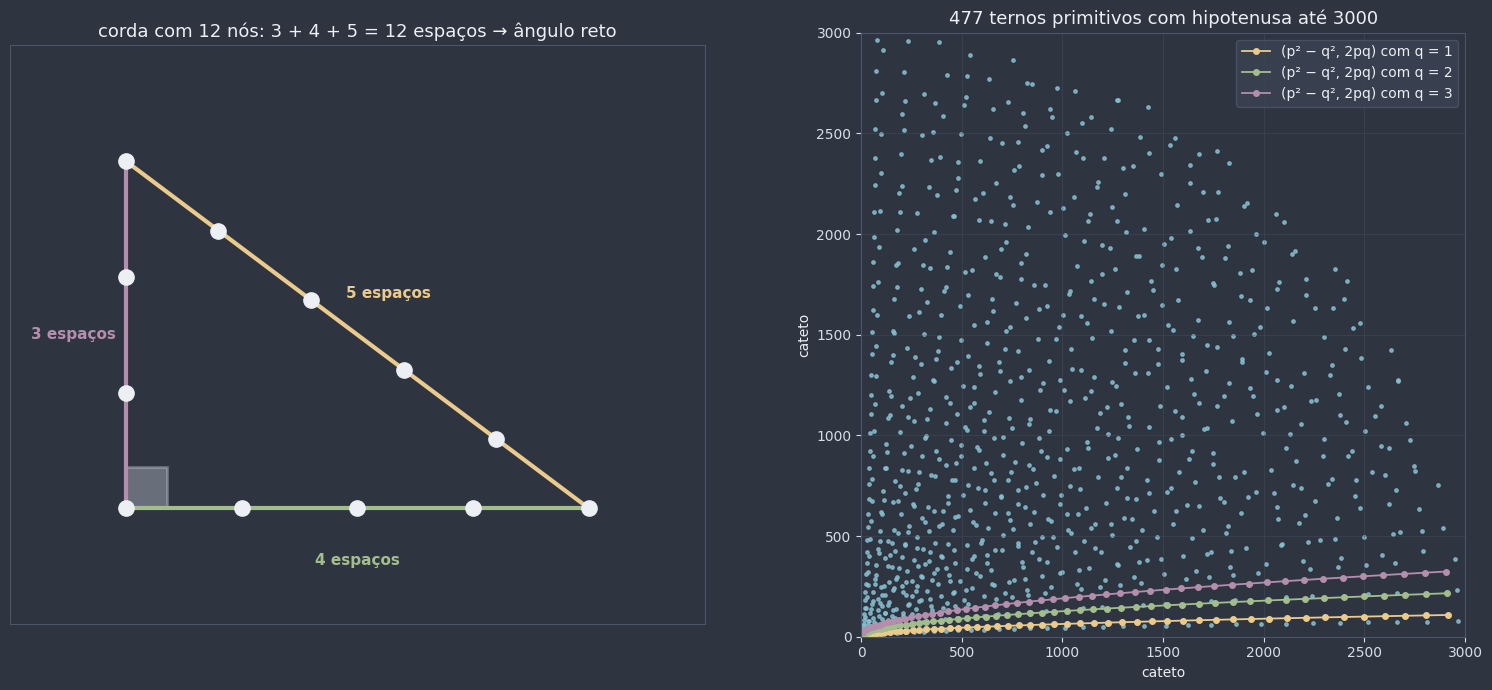

In [11]:
fig, (ax_corda, ax_ternos) = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={"width_ratios": [1, 1.2]})
fig.patch.set_facecolor(NORD_FUNDO)

# A corda de 12 nós esticada em triângulo 3–4–5
A_c, B_c, C_c = np.array([0.0, 0.0]), np.array([0.0, 3.0]), np.array([4.0, 0.0])
for P, Q, cor in ((A_c, C_c, COR_CATETO_B), (C_c, B_c, COR_HIPOTENUSA), (B_c, A_c, COR_CATETO_C)):
    desenhar_segmento(ax_corda, P, Q, cor=cor, largura=3)
    passos = int(round(math.dist(P, Q)))
    for k in range(passos):
        ax_corda.plot(*(P + k / passos * (Q - P)), "o", color=NORD_TEXTO, markersize=11, zorder=6)
    rotular_segmento(ax_corda, P, Q, f"{passos} espaços", cor=cor, distancia=0.45, longe_de=(1.3, 1))
desenhar_arco(ax_corda, A_c, B_c, C_c, raio=0.6, cor=NORD_TEXTO_SEC)
preparar_eixo(ax_corda, [A_c, B_c, C_c], margem=1.0)
ax_corda.set_title("corda com 12 nós: 3 + 4 + 5 = 12 espaços → ângulo reto", color=NORD_TEXTO, fontsize=13)

# Os ternos primitivos como pontos (cateto, cateto)
ternos = ternos_primitivos(3000)
xs = [t[0] for t in ternos] + [t[1] for t in ternos]
ys = [t[1] for t in ternos] + [t[0] for t in ternos]
estilizar_eixo(ax_ternos)
ax_ternos.scatter(xs, ys, s=6, color=COR_PONTO, alpha=0.8)
for q, cor in ((1, COR_AVISO), (2, COR_DESTAQUE), (3, COR_EXTRA)):
    curva = [(p * p - q * q, 2 * p * q) for p in range(q + 1, 60) if p * p + q * q <= 3000]
    ax_ternos.plot(*zip(*curva), "-o", color=cor, ms=4, lw=1.3, label=f"(p² − q², 2pq) com q = {q}")
ax_ternos.legend(facecolor=NORD_PAINEL, edgecolor=NORD_LINHA, labelcolor=NORD_TEXTO, loc="upper right")
ax_ternos.set_xlim(0, 3000)
ax_ternos.set_ylim(0, 3000)
ax_ternos.set_aspect("equal")
ax_ternos.set_xlabel("cateto", color=NORD_TEXTO)
ax_ternos.set_ylabel("cateto", color=NORD_TEXTO)
ax_ternos.set_title(f"{len(ternos)} ternos primitivos com hipotenusa até 3000", color=NORD_TEXTO, fontsize=13)
plt.tight_layout()
plt.show()

🕵️ **Curiosidade histórica — a crise dos irracionais:** no quadrado de lado 1, a diagonal divide o quadrado em dois triângulos retângulos de catetos 1 e 1, e Pitágoras dá $d^2 = 1^2 + 1^2 = 2$, isto é, $d = \sqrt{2}$. Segundo a tradição, foi dentro da própria escola pitagórica que se descobriu que $\sqrt{2}$ **não é razão de dois inteiros**: a diagonal e o lado do quadrado são **incomensuráveis** (não existe uma unidade, por menor que seja, que caiba um número inteiro de vezes em cada um). Conta-se que a descoberta abalou os pitagóricos, para quem "tudo é número" (inteiro ou razão de inteiros). Os relatos são lendários, mas o resultado matemático é sólido, e é exatamente a incomensurabilidade que obrigou [`0414a_teorema_de_tales.ipynb`](0414a_teorema_de_tales.ipynb) a tratar separadamente o caso das razões irracionais.

A ideia da demonstração de que $\sqrt{2}$ é irracional, em três passos (o desenvolvimento completo é tema de [`0103a_conjuntos_numericos.ipynb`](../01_conjuntos_e_funcoes/0103a_conjuntos_numericos.ipynb)): (1) suponha que $\sqrt{2} = \frac{p}{q}$, com inteiros positivos; (2) então $p^2 = 2q^2$; (3) mas o número de fatores 2 na decomposição de $p^2$ é **par** (é o dobro do de $p$), enquanto em $2q^2$ é **ímpar**. Absurdo.

A célula abaixo não prova nada (nenhuma busca finita prova), mas **mostra** o fenômeno: para cada denominador $q$ de 1 a 10 000, procura o $p$ que deixa $\frac{p}{q}$ mais perto de $\sqrt{2}$ e confere se $p^2 = 2q^2$. As frações vão chegando cada vez mais perto, e a diferença $p^2 - 2q^2$ (calculada com inteiros, sem arredondamento) nunca chega a zero.

In [12]:
raiz_de_2 = math.sqrt(2)
recordes, melhor_erro, achou_exata = [], float("inf"), False
for q in range(1, 10_001):
    for p in (math.floor(q * raiz_de_2), math.ceil(q * raiz_de_2)):
        if p * p == 2 * q * q:  # comparação exata, só com inteiros
            achou_exata = True
        erro = abs(p / q - raiz_de_2)
        if erro < melhor_erro:
            melhor_erro = erro
            recordes.append({"p/q": f"{p}/{q}", "(p/q)²": f"{(p / q) ** 2:.12f}", "p² − 2q²": p * p - 2 * q * q,
                             "|p/q − √2|": f"{erro:.1e}"})
display(pd.DataFrame(recordes))
print(f"alguma fração p/q com q ≤ 10 000 tem (p/q)² = 2 exatamente? {achou_exata}")

,p/q,(p/q)²,p² − 2q²,|p/q − √2|
0,1/1,1.000000000000,-1,4.1e-01
1,3/2,2.250000000000,1,8.6e-02
2,4/3,1.777777777778,-2,8.1e-02
3,7/5,1.960000000000,-1,1.4e-02
4,17/12,2.006944444444,1,2.5e-03
5,24/17,1.993079584775,-2,2.4e-03
6,41/29,1.998810939358,-1,4.2e-04
7,99/70,2.000204081633,1,7.2e-05
8,140/99,1.999795939190,-2,7.2e-05
9,239/169,1.999964987220,-1,1.2e-05


alguma fração p/q com q ≤ 10 000 tem (p/q)² = 2 exatamente? False


As melhores aproximações são $\frac{3}{2}, \frac{7}{5}, \frac{17}{12}, \frac{41}{29}, \frac{99}{70}, \ldots$, e o erro cai de $10^{-1}$ para $10^{-9}$. Repare na coluna $p^2 - 2q^2$: ela vale sempre $+1$ ou $-1$, **nunca 0**. Chegar perto, dá; acertar, nunca.

📎 **Conexão:** o número $\sqrt{2}$ e os outros $\sqrt{n}$ voltam no Desafio 6 (a espiral de Teodoro) e já fazem parte do mapa de [`0103a_conjuntos_numericos.ipynb`](../01_conjuntos_e_funcoes/0103a_conjuntos_numericos.ipynb).

⚠️ **Erros comuns:**

1. **Aplicar $a^2 = b^2 + c^2$ a um triângulo que não é retângulo.** O teorema exige o ângulo reto. Num triângulo de lados 5, 6 e 7, por exemplo, $7^2 = 49 \neq 61 = 5^2 + 6^2$.
2. **Tomar um cateto como "$a$".** A hipotenusa é **sempre** o maior lado, oposta ao ângulo reto. Com catetos 6 e 10, a hipotenusa é $\sqrt{136} \approx 11{,}66$, e **não** $\sqrt{10^2 - 6^2} = 8$.
3. **Esquecer a desigualdade triangular.** Antes de classificar, confira se as medidas formam triângulo: $(1, 2, 3)$ "passa" na comparação ($9 > 5$, "obtusângulo"), mas nem triângulo forma.

📖 **Leitura complementar:** [Teorema de Pitágoras](https://pt.wikipedia.org/wiki/Teorema_de_Pit%C3%A1goras), [Pitágoras](https://pt.wikipedia.org/wiki/Pit%C3%A1goras), [Terno pitagórico](https://pt.wikipedia.org/wiki/Terno_pitag%C3%B3rico) e [Plimpton 322](https://pt.wikipedia.org/wiki/Plimpton_322) (Wikipédia).

**Pergunta de checagem:** os lados 7, 24 e 25 formam um triângulo retângulo? E os lados 6, 7 e 9: qual é a classificação? E 4, 5 e 7?

**Pergunta de checagem:** um terreno tem um canto que deveria ser reto. Você mede 6 m num lado, 8 m no outro e 10,2 m entre as marcas. O canto está aberto ou fechado demais?

## 3. Triângulos retângulos notáveis

Dois triângulos retângulos aparecem o tempo todo em geometria, em provas e em desenho técnico, e têm uma vantagem enorme: as medidas deles **não dependem de calculadora**. Os dois nascem de figuras que você já conhece, cortadas ao meio.

### O triângulo 45°–45°–90°: metade de um quadrado

Corte um quadrado de lado $x$ pela diagonal. Cada metade é um triângulo retângulo **isósceles**: catetos iguais a $x$ e ângulos agudos de 45° (a diagonal do quadrado é bissetriz dos ângulos retos, [`0409a_paralelogramos_e_casos_particulares.ipynb`](0409a_paralelogramos_e_casos_particulares.ipynb)). Por Pitágoras, a hipotenusa $d$ satisfaz

$$d^2 = x^2 + x^2 = 2x^2 \quad\Longrightarrow\quad d = x\sqrt{2}.$$

Consequência: **a diagonal do quadrado de lado $\ell$ mede $\ell\sqrt{2}$**. É a diagonal incomensurável da seção 2.

### O triângulo 30°–60°–90°: metade de um triângulo equilátero

Corte um triângulo equilátero de lado $2x$ por uma altura. No equilátero, a altura é também mediana e bissetriz ([`0410a_pontos_notaveis_do_triangulo.ipynb`](0410a_pontos_notaveis_do_triangulo.ipynb)): ela divide a base em duas metades de medida $x$ e o ângulo de 60° do topo em dois de 30°. Cada metade é um triângulo retângulo com ângulos de 30°, 60° e 90°, hipotenusa $2x$ e cateto menor $x$. Por Pitágoras, o cateto maior $y$ satisfaz

$$y^2 + x^2 = (2x)^2 \quad\Longrightarrow\quad y^2 = 3x^2 \quad\Longrightarrow\quad y = x\sqrt{3}.$$

Consequências:

- **a altura do triângulo equilátero de lado $\ell$ mede $\dfrac{\ell\sqrt{3}}{2}$** (é o $y$ com $x = \frac{\ell}{2}$);
- **em todo triângulo retângulo com um ângulo de 30°, o cateto oposto a esse ângulo mede a metade da hipotenusa** (todos esses triângulos são semelhantes à metade do equilátero, pelo critério AA);
- no equilátero, os quatro pontos notáveis coincidem, e o baricentro divide a altura na razão $2 : 1$ ([`0410a_pontos_notaveis_do_triangulo.ipynb`](0410a_pontos_notaveis_do_triangulo.ipynb)). Então o raio da circunferência **inscrita** é $r = \frac{h}{3} = \frac{\ell\sqrt{3}}{6}$ e o da **circunscrita** é $R = \frac{2h}{3} = \frac{\ell\sqrt{3}}{3}$, com $r : R = 1 : 2$.

📌 **Definição formal (triângulos retângulos notáveis):**

| Triângulo | Cateto oposto ao menor ângulo | Outro cateto | Hipotenusa | De onde vem |
|---|---|---|---|---|
| 45°–45°–90° | $x$ | $x$ | $x\sqrt{2}$ | metade do quadrado de lado $x$ |
| 30°–60°–90° | $x$ (oposto a 30°) | $x\sqrt{3}$ (oposto a 60°) | $2x$ | metade do equilátero de lado $2x$ |

| Consequência | Fórmula |
|---|---|
| diagonal do quadrado de lado $\ell$ | $\ell\sqrt{2}$ |
| altura do equilátero de lado $\ell$ | $\dfrac{\ell\sqrt{3}}{2}$ |
| cateto oposto a 30° | metade da hipotenusa |
| raios do equilátero de lado $\ell$ | $r = \dfrac{\ell\sqrt{3}}{6}$, $R = \dfrac{\ell\sqrt{3}}{3}$ |

**No código:** a célula abaixo **não usa** as fórmulas para construir os triângulos. O 45°–45°–90° sai das coordenadas do quadrado; o 30°–60°–90° sai de `triangulo_por_lados(2x, 2x, 2x)` (o equilátero construído pelos lados, como em 0415a) e de `pe_da_altura`. Depois, as razões medidas são comparadas com $\sqrt{2}$, $\sqrt{3}$ e $2$.

In [13]:
def metade_do_quadrado(x: float):
    """Triângulo 45°–45°–90°: o quadrado de lado x cortado pela diagonal. Devolve (vértice reto, os outros dois)
    e o quadrado inteiro (a figura-origem)."""
    P0, P1, P2, P3 = (np.array(p, dtype=float) for p in ((0, 0), (x, 0), (x, x), (0, x)))
    return (P1, P0, P2), [P0, P1, P2, P3]


def metade_do_equilatero(x: float):
    """Triângulo 30°–60°–90°: o equilátero de lado 2x cortado pela altura. Devolve (vértice reto M, o vértice do
    ângulo de 60°, o vértice do ângulo de 30°) e o equilátero inteiro (a figura-origem)."""
    P, Q, T = triangulo_por_lados(2 * x, 2 * x, 2 * x)  # construído pelos lados, sem usar √3
    M = pe_da_altura(T, P, Q)
    return (M, P, T), [P, Q, T]


linhas = []
for x in (1, 2, 2.5, 5, 10):
    (R, P, Q), _ = metade_do_quadrado(x)
    (M, V60, V30), _ = metade_do_equilatero(x)
    linhas.append({
        "x": x,
        "45-45-90: hipotenusa/x": f"{math.dist(P, Q) / x:.6f}",
        "ângulos": f"{medir_angulo(P, R, Q):.1f}°, {medir_angulo(Q, R, P):.1f}°",
        "30-60-90: cateto maior/x": f"{math.dist(M, V30) / x:.6f}",
        "hipotenusa/x": f"{math.dist(V60, V30) / x:.6f}",
        "ângulos ": f"{medir_angulo(V60, M, V30):.1f}°, {medir_angulo(V30, M, V60):.1f}°",
    })
display(pd.DataFrame(linhas))
print(f"√2 = {math.sqrt(2):.6f}   √3 = {math.sqrt(3):.6f}")

# Altura e raios do triângulo equilátero, medidos e pela fórmula
linhas = []
for lado in (1, 2, 6, 10):
    P, Q, T = triangulo_por_lados(lado, lado, lado)
    G = baricentro(P, Q, T)  # no equilátero, G = I = O
    linhas.append({"lado ℓ": lado,
                   "altura medida": f"{math.dist(T, pe_da_altura(T, P, Q)):.6f}",
                   "ℓ√3/2": f"{lado * math.sqrt(3) / 2:.6f}",
                   "r medido (G até um lado)": f"{distancia_ponto_reta(G, P, Q):.6f}",
                   "ℓ√3/6": f"{lado * math.sqrt(3) / 6:.6f}",
                   "R medido (G até um vértice)": f"{math.dist(G, T):.6f}",
                   "ℓ√3/3": f"{lado * math.sqrt(3) / 3:.6f}"})
display(pd.DataFrame(linhas))

,x,45-45-90: hipotenusa/x,ângulos,30-60-90: cateto maior/x,hipotenusa/x,ângulos
0,1.0,1.414214,"45.0°, 45.0°",1.732051,2.000000,"60.0°, 30.0°"
1,2.0,1.414214,"45.0°, 45.0°",1.732051,2.000000,"60.0°, 30.0°"
2,2.5,1.414214,"45.0°, 45.0°",1.732051,2.000000,"60.0°, 30.0°"
3,5.0,1.414214,"45.0°, 45.0°",1.732051,2.000000,"60.0°, 30.0°"
4,10.0,1.414214,"45.0°, 45.0°",1.732051,2.000000,"60.0°, 30.0°"


√2 = 1.414214   √3 = 1.732051


,lado ℓ,altura medida,ℓ√3/2,r medido (G até um lado),ℓ√3/6,R medido (G até um vértice),ℓ√3/3
0,1,0.866025,0.866025,0.288675,0.288675,0.577350,0.577350
1,2,1.732051,1.732051,0.577350,0.577350,1.154701,1.154701
2,6,5.196152,5.196152,1.732051,1.732051,3.464102,3.464102
3,10,8.660254,8.660254,2.886751,2.886751,5.773503,5.773503


As razões não mudam com $x$: hipotenusa $\div\, x = 1{,}414214 = \sqrt{2}$ no primeiro triângulo; cateto maior $\div\, x = 1{,}732051 = \sqrt{3}$ e hipotenusa $\div\, x = 2$ no segundo. Os ângulos medidos são 45°, 45° e 60°, 30°. Na segunda tabela, as medidas feitas nas figuras coincidem com as fórmulas.

🕹️ **Widget interativo:** escolha o triângulo notável no seletor e mude a medida $x$ no slider. A figura-origem (o quadrado ou o equilátero) aparece ao fundo, em tom suave, e cada lado do triângulo é rotulado em função de $x$ e com o seu valor. O painel confere as razões: elas **não dependem de $x$**, porque todos os triângulos desenhados são semelhantes (AA).

In [14]:
def explorar_notaveis(tipo: str, x: float) -> None:
    fig, (ax, ax_lista) = plt.subplots(1, 2, figsize=(15, 6.6), gridspec_kw={"width_ratios": [1.2, 1]})
    fig.patch.set_facecolor(NORD_FUNDO)
    if tipo == "45°–45°–90°":
        (R, P, Q), origem = metade_do_quadrado(x)
        rotulos = (f"x = {x:g}", f"x = {x:g}", f"x√2 ≈ {x * math.sqrt(2):.2f}")
        angulos_nomes = ("45°", "45°")
        razoes = [(f"hipotenusa / cateto = {math.dist(P, Q) / x:.4f} = √2", iguais(math.dist(P, Q) / x, math.sqrt(2))),
                  (f"cateto / cateto = {math.dist(R, Q) / math.dist(R, P):.4f} = 1", iguais(math.dist(R, Q), x))]
    else:
        (R, P, Q), origem = metade_do_equilatero(x)
        rotulos = (f"x = {x:g}", f"x√3 ≈ {x * math.sqrt(3):.2f}", f"2x = {2 * x:g}")
        angulos_nomes = ("60°", "30°")
        razoes = [(f"cateto maior / cateto menor = {math.dist(R, Q) / x:.4f} = √3",
                   iguais(math.dist(R, Q) / x, math.sqrt(3))),
                  (f"hipotenusa / cateto menor = {math.dist(P, Q) / x:.4f} = 2", iguais(math.dist(P, Q) / x, 2)),
                  (f"cateto oposto a 30° = {x:g} = metade da hipotenusa", iguais(2 * x, math.dist(P, Q)))]
    ax.add_patch(Polygon(origem, closed=True, facecolor=NORD_LINHA, alpha=0.35, edgecolor=NORD_TEXTO_SEC, lw=1.5,
                         ls="--"))
    ax.add_patch(Polygon([R, P, Q], closed=True, facecolor=COR_TRIANGULO, alpha=0.3, edgecolor="none"))
    centro = (R + P + Q) / 3
    for (X, Y), cor, rotulo in zip(((R, P), (R, Q), (P, Q)), (COR_CATETO_C, COR_CATETO_B, COR_HIPOTENUSA), rotulos):
        desenhar_segmento(ax, X, Y, cor=cor, largura=3.5)
        rotular_segmento(ax, X, Y, rotulo, cor=cor, distancia=0.65, longe_de=centro, tamanho=12)
    desenhar_arco(ax, R, P, Q, raio=0.45, cor=NORD_TEXTO_SEC)
    desenhar_arco(ax, P, R, Q, raio=0.7, cor=COR_SECUNDARIA, rotulo=angulos_nomes[0], raio_rotulo=1.15)
    desenhar_arco(ax, Q, R, P, raio=0.7, cor=COR_SECUNDARIA, rotulo=angulos_nomes[1], raio_rotulo=1.15)
    preparar_eixo(ax, [(-0.8, -0.8), (10.8, 9.4)], margem=0.3)
    ax.set_title(f"{tipo} com x = {x:g}", color=NORD_TEXTO, fontsize=13)
    itens = razoes + [(f"ângulos medidos: {medir_angulo(R, P, Q):.1f}°, {medir_angulo(P, R, Q):.1f}°, "
                       f"{medir_angulo(Q, R, P):.1f}°", True)]
    escrever_checklist(ax_lista, itens, "As razões não dependem de x")
    plt.tight_layout()
    plt.show()


widgets.interact(
    explorar_notaveis,
    tipo=widgets.Dropdown(options=["45°–45°–90°", "30°–60°–90°"], value="30°–60°–90°", description="triângulo:"),
    x=widgets.FloatSlider(value=3.0, min=0.5, max=5.0, step=0.5, description="x:"),
);

interactive(children=(Dropdown(description='triângulo:', index=1, options=('45°–45°–90°', '30°–60°–90°'), valu…

⚠️ **Erro comum: confundir qual cateto é $x$ e qual é $x\sqrt{3}$ no 30°–60°–90°.** A regra vem de [`0404a_triangulos_conceito_elementos_e_classificacao.ipynb`](0404a_triangulos_conceito_elementos_e_classificacao.ipynb): ao **menor** ângulo opõe-se o **menor** lado. O cateto **menor**, $x$, é oposto ao ângulo de **30°**; o cateto **maior**, $x\sqrt{3}$, é oposto ao de **60°**. Na dúvida, lembre que $\sqrt{3} \approx 1{,}73$ é maior que 1, e que a hipotenusa ($2x$) tem de ser o maior lado de todos.

📎 **Conexão (para a Trigonometria):** em cada um desses triângulos, as razões "cateto ÷ hipotenusa" e "cateto ÷ cateto" **dependem só dos ângulos** (todos os 30°–60°–90° são semelhantes, [`0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb`](0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb)). Por exemplo, no 30°–60°–90°, o cateto oposto a 30° dividido pela hipotenusa é sempre $\frac{x}{2x} = \frac{1}{2}$. Essas razões têm nome (**seno**, **cosseno** e **tangente**), e os valores exatos para 30°, 45° e 60° saem justamente destes dois triângulos, em [`0505a_arcos_notaveis.ipynb`](../05_trigonometria/0505a_arcos_notaveis.ipynb) e [`0509a_triangulos_retangulos.ipynb`](../05_trigonometria/0509a_triangulos_retangulos.ipynb). Aqui, nada de trigonometria: só Pitágoras.

🎯 **Aplicação prática — os esquadros de desenho:** o estojo de desenho técnico tem **dois esquadros**: um de 45° e um de 30°–60°. São exatamente os dois triângulos notáveis, e é por isso que arquitetos e engenheiros conseguem traçar, sem transferidor, os ângulos de 15°, 30°, 45°, 60°, 75°, 90°... (somando e subtraindo os ângulos dos dois esquadros).

🎯 **Aplicação prática — telhados:** um telhado de duas águas com inclinação de 30° e vão de 8 m tem cada "água" como a hipotenusa de um 30°–60°–90° de cateto maior 4 m. Então $x\sqrt{3} = 4$, $x = \frac{4}{\sqrt{3}} \approx 2{,}31$ m (a altura da cumeeira) e o caibro mede $2x \approx 4{,}62$ m.

📖 **Leitura complementar:** [Triângulo equilátero](https://pt.wikipedia.org/wiki/Tri%C3%A2ngulo_equil%C3%A1tero) (Wikipédia): altura e raios das circunferências inscrita e circunscrita.

**Pergunta de checagem:** a diagonal de um quadrado mede 10 cm. Quanto mede o lado? E quanto mede a altura de um triângulo equilátero de lado 10 cm?

## 4. Aplicações no plano

Agora o Teorema de Pitágoras é ferramenta oficial. Em cada problema abaixo, o trabalho é sempre o mesmo: **achar o triângulo retângulo escondido** e perguntar "o que eu sei sobre dois dos lados dele?".

**1. Distância entre dois pontos.** Dados $A(x_1, y_1)$ e $B(x_2, y_2)$, o ponto $R(x_2, y_1)$ forma com eles um triângulo retângulo em $R$ (um lado horizontal, outro vertical), com catetos $|x_2 - x_1|$ e $|y_2 - y_1|$. A distância $AB$ é a hipotenusa:

$$d(A, B) = \sqrt{(x_2 - x_1)^2 + (y_2 - y_1)^2}.$$

Esta é a fórmula que o código usa desde [`0402a_segmento_de_reta.ipynb`](0402a_segmento_de_reta.ipynb), em `math.dist` e `math.hypot`, e que até agora foi aceita "de confiança": **está justificada**. Ela é o ponto de partida de 📌 Geometria Analítica.

**2. Diagonal do retângulo.** A diagonal corta o retângulo de lados $a$ e $b$ em dois triângulos retângulos de catetos $a$ e $b$: $d = \sqrt{a^2 + b^2}$. No quadrado, $d = \ell\sqrt{2}$ (seção 3). **A TV de 55" do gancho:** a tela é um retângulo **semelhante** ao de lados 16 e 9, cuja diagonal é $\sqrt{16^2 + 9^2} = \sqrt{337}$. A razão de semelhança é $k = \frac{55}{\sqrt{337}}$, e então

$$\text{largura} = \frac{55 \cdot 16}{\sqrt{337}} \approx 47{,}9'' \qquad \text{altura} = \frac{55 \cdot 9}{\sqrt{337}} \approx 27{,}0''.$$

**3. Losango.** As diagonais do losango se cortam **ao meio** e são **perpendiculares** ([`0409a_paralelogramos_e_casos_particulares.ipynb`](0409a_paralelogramos_e_casos_particulares.ipynb)): elas dividem o losango em quatro triângulos retângulos congruentes, de catetos $\frac{d_1}{2}$ e $\frac{d_2}{2}$ e hipotenusa igual ao lado:

$$\ell = \sqrt{\left(\frac{d_1}{2}\right)^2 + \left(\frac{d_2}{2}\right)^2}.$$

Cumprindo a promessa de 0409a: diagonais de 6 cm e 8 cm dão semidiagonais 3 e 4, e o lado é **5 cm**.

**4. Trapézio.** Num trapézio isósceles de bases $B$ e $b$ e lados oblíquos $\ell$, as perpendiculares baixadas das pontas da base menor ([`0407a_perpendicularidade.ipynb`](0407a_perpendicularidade.ipynb) e [`0408a_quadrilateros_definicao_elementos_e_trapezios.ipynb`](0408a_quadrilateros_definicao_elementos_e_trapezios.ipynb)) recortam um retângulo no meio e dois triângulos retângulos nas pontas, cada um com cateto $\frac{B - b}{2}$ na base. A altura é o outro cateto:

$$h = \sqrt{\ell^2 - \left(\frac{B - b}{2}\right)^2}.$$

Por exemplo, bases 10 e 4 e lados 5: cada "ponta" mede $\frac{10 - 4}{2} = 3$, e $h = \sqrt{25 - 9} = 4$. (No trapézio **retângulo**, há uma ponta só, de medida $B - b$.)

**5. Altura do triângulo isósceles.** A altura relativa à base de um isósceles é também mediana ([`0410a_pontos_notaveis_do_triangulo.ipynb`](0410a_pontos_notaveis_do_triangulo.ipynb)): ela forma dois triângulos retângulos de hipotenusa igual ao lado e cateto igual à metade da base. No equilátero, é o resultado da seção 3.

🎯 **Aplicação prática — escadas:** uma escada de 5 m apoiada numa parede, com o pé a 3 m da parede, alcança $\sqrt{5^2 - 3^2} = 4$ m de altura. (A parede e o chão formam o ângulo reto; a escada é a hipotenusa.)

In [15]:
def distancia(P, Q) -> float:
    """Distância entre os pontos P e Q: a hipotenusa do triângulo retângulo de catetos |Δx| e |Δy|."""
    return math.sqrt((Q[0] - P[0]) ** 2 + (Q[1] - P[1]) ** 2)


def diagonal_retangulo(base: float, altura: float) -> float:
    """Diagonal do retângulo de lados `base` e `altura`: a hipotenusa de catetos base e altura."""
    return math.sqrt(base**2 + altura**2)


def lado_losango(d1: float, d2: float) -> float:
    """Lado do losango de diagonais d1 e d2: a hipotenusa de catetos d1/2 e d2/2."""
    return math.sqrt((d1 / 2) ** 2 + (d2 / 2) ** 2)


def altura_trapezio_isosceles(base_maior: float, base_menor: float, lado: float) -> float | None:
    """Altura do trapézio isósceles: o cateto que falta no triângulo de hipotenusa `lado` e cateto
    (B − b)/2. Devolve None se o lado for curto demais para fechar o trapézio."""
    ponta = (base_maior - base_menor) / 2
    if lado <= ponta:
        return None
    return math.sqrt(lado**2 - ponta**2)


def dimensoes_tela(diagonal: float, proporcao_largura: float, proporcao_altura: float) -> tuple[float, float]:
    """Largura e altura de uma tela a partir da diagonal e da proporção (por exemplo, 16 : 9): a tela é semelhante
    ao retângulo de lados 16 e 9, e a razão de semelhança é diagonal ÷ √(16² + 9²)."""
    k = diagonal / diagonal_retangulo(proporcao_largura, proporcao_altura)
    return k * proporcao_largura, k * proporcao_altura


# 1. A fórmula da distância concorda com math.dist e math.hypot, para pontos sorteados
gerador = np.random.default_rng(16)
for _ in range(1000):
    P, Q = gerador.uniform(-50, 50, 2), gerador.uniform(-50, 50, 2)
    assert iguais(distancia(P, Q), math.dist(P, Q)) and iguais(distancia(P, Q), math.hypot(*(Q - P)))
print("distância: a fórmula de Pitágoras confere com math.dist e math.hypot em 1000 pares de pontos")

# 2. A TV de 55 polegadas (1 polegada = 2,54 cm)
largura, altura = dimensoes_tela(55, 16, 9)
assert iguais(diagonal_retangulo(largura, altura), 55)
print(f"TV de 55\": {largura:.2f}\" × {altura:.2f}\"  =  {largura * 2.54:.1f} cm × {altura * 2.54:.1f} cm")

# 3, 4 e a escada
assert iguais(lado_losango(6, 8), 5)
assert iguais(altura_trapezio_isosceles(10, 4, 5), 4)
assert iguais(math.sqrt(5**2 - 3**2), 4)
print(f"losango de diagonais 6 e 8: lado {lado_losango(6, 8):g};  trapézio de bases 10 e 4 e lados 5: altura "
      f"{altura_trapezio_isosceles(10, 4, 5):g};  escada de 5 m com o pé a 3 m: alcança {math.sqrt(16):g} m")

telas = [("monitor", 24, 16, 9), ("TV", 32, 16, 9), ("TV", 43, 16, 9), ("TV", 55, 16, 9), ("TV", 65, 16, 9),
         ("TV", 75, 16, 9), ("notebook", 15.6, 16, 9), ("celular (19,5 : 9)", 6.1, 19.5, 9)]
linhas = []
for nome, diag, pl, pa in telas:
    larg, alt = dimensoes_tela(diag, pl, pa)
    linhas.append({"tela": nome, "diagonal (pol.)": diag, "largura (cm)": f"{larg * 2.54:.1f}",
                   "altura (cm)": f"{alt * 2.54:.1f}", "diagonal (cm)": f"{diag * 2.54:.1f}"})
display(pd.DataFrame(linhas))

distância: a fórmula de Pitágoras confere com math.dist e math.hypot em 1000 pares de pontos
TV de 55": 47.94" × 26.96"  =  121.8 cm × 68.5 cm
losango de diagonais 6 e 8: lado 5;  trapézio de bases 10 e 4 e lados 5: altura 4;  escada de 5 m com o pé a 3 m: alcança 4 m


,tela,diagonal (pol.),largura (cm),altura (cm),diagonal (cm)
0,monitor,24.0,53.1,29.9,61.0
1,TV,32.0,70.8,39.8,81.3
2,TV,43.0,95.2,53.5,109.2
3,TV,55.0,121.8,68.5,139.7
4,TV,65.0,143.9,80.9,165.1
5,TV,75.0,166.0,93.4,190.5
6,notebook,15.6,34.5,19.4,39.6
7,"celular (19,5 : 9)",6.1,14.1,6.5,15.5


A TV de 55" tem cerca de **122 cm × 68 cm**: cabe no rack de 1,20 m? Por pouco, **não** (sem contar a borda da TV!). A tabela mostra a mesma conta para outras telas. Repare que dobrar a diagonal dobra a largura e a altura (semelhança): a de 65" não é "um pouco maior" que a de 32", é **duas vezes** mais larga.

A representação gráfica: os quatro problemas com o triângulo retângulo escondido em destaque.

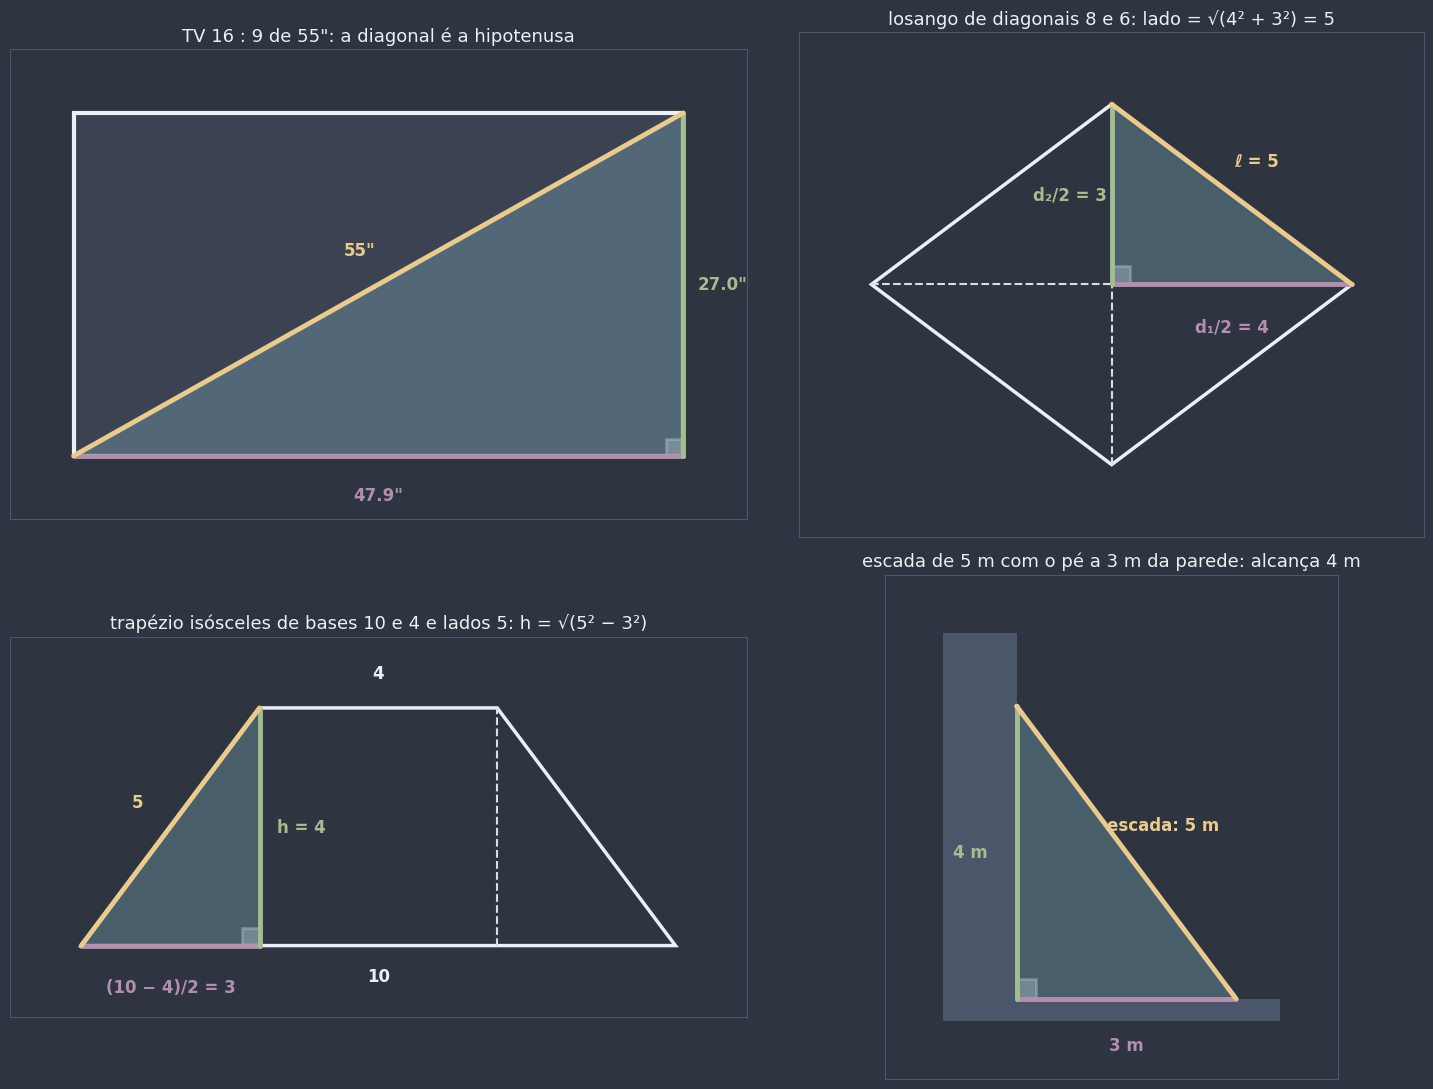

In [16]:
fig, eixos = plt.subplots(2, 2, figsize=(15, 11))
fig.patch.set_facecolor(NORD_FUNDO)


def destacar_retangulo(ax, R, P, Q, rotulos, raio: float = 0.35) -> None:
    """Pinta o triângulo retângulo escondido (reto em R) com as cores fixas: cateto RP roxo, cateto RQ verde e
    hipotenusa PQ amarela, e escreve os rótulos dos três lados."""
    ax.add_patch(Polygon([R, P, Q], closed=True, facecolor=COR_TRIANGULO, alpha=0.3, edgecolor="none", zorder=2))
    centro = (R + P + Q) / 3
    for (X, Y), cor, rotulo in zip(((R, P), (R, Q), (P, Q)), (COR_CATETO_C, COR_CATETO_B, COR_HIPOTENUSA), rotulos):
        desenhar_segmento(ax, X, Y, cor=cor, largura=3.5)
        rotular_segmento(ax, X, Y, rotulo, cor=cor, distancia=raio * 1.4, longe_de=centro, tamanho=12)
    desenhar_arco(ax, R, P, Q, raio=raio, cor=NORD_TEXTO_SEC)


# A TV de 55"
ax = eixos[0, 0]
ax.add_patch(Rectangle((0, 0), largura, altura, facecolor=NORD_PAINEL, edgecolor=NORD_TEXTO, lw=3))
destacar_retangulo(ax, np.array([largura, 0.0]), np.array([0.0, 0.0]), np.array([largura, altura]),
                   (f"{largura:.1f}\"", f"{altura:.1f}\"", "55\""), raio=2.2)
preparar_eixo(ax, [(0, 0), (largura, altura)], margem=5)
ax.set_title("TV 16 : 9 de 55\": a diagonal é a hipotenusa", color=NORD_TEXTO, fontsize=13)

# O losango de diagonais 6 e 8
ax = eixos[0, 1]
losango = [np.array(p, dtype=float) for p in ((-4, 0), (0, -3), (4, 0), (0, 3))]
ax.add_patch(Polygon(losango, closed=True, fill=False, edgecolor=NORD_TEXTO, lw=2.5))
desenhar_segmento(ax, losango[0], losango[2], cor=NORD_TEXTO_SEC, largura=1.5, estilo="--")
desenhar_segmento(ax, losango[1], losango[3], cor=NORD_TEXTO_SEC, largura=1.5, estilo="--")
destacar_retangulo(ax, np.array([0.0, 0.0]), np.array([4.0, 0.0]), np.array([0.0, 3.0]), ("d₁/2 = 4", "d₂/2 = 3",
                   "ℓ = 5"), raio=0.5)
preparar_eixo(ax, losango, margem=1.2)
ax.set_title("losango de diagonais 8 e 6: lado = √(4² + 3²) = 5", color=NORD_TEXTO, fontsize=13)

# O trapézio isósceles de bases 10 e 4 e lados 5
ax = eixos[1, 0]
trapezio = [np.array(p, dtype=float) for p in ((0, 0), (10, 0), (7, 4), (3, 4))]
ax.add_patch(Polygon(trapezio, closed=True, fill=False, edgecolor=NORD_TEXTO, lw=2.5))
desenhar_segmento(ax, (3, 0), (3, 4), cor=NORD_TEXTO_SEC, largura=1.5, estilo="--")
desenhar_segmento(ax, (7, 0), (7, 4), cor=NORD_TEXTO_SEC, largura=1.5, estilo="--")
destacar_retangulo(ax, np.array([3.0, 0.0]), np.array([0.0, 0.0]), np.array([3.0, 4.0]), ("(10 − 4)/2 = 3", "h = 4",
                   "5"), raio=0.5)
ax.text(5, 4.5, "4", color=NORD_TEXTO, fontsize=12, ha="center", fontweight="bold")
ax.text(5, -0.6, "10", color=NORD_TEXTO, fontsize=12, ha="center", fontweight="bold")
preparar_eixo(ax, trapezio, margem=1.2)
ax.set_title("trapézio isósceles de bases 10 e 4 e lados 5: h = √(5² − 3²)", color=NORD_TEXTO, fontsize=13)

# A escada
ax = eixos[1, 1]
ax.add_patch(Rectangle((-1, -0.3), 4.6, 0.3, facecolor=NORD_LINHA, edgecolor="none"))
ax.add_patch(Rectangle((-1, 0), 1, 5, facecolor=NORD_LINHA, edgecolor="none"))
destacar_retangulo(ax, np.array([0.0, 0.0]), np.array([3.0, 0.0]), np.array([0.0, 4.0]), ("3 m", "4 m",
                   "escada: 5 m"), raio=0.45)
preparar_eixo(ax, [(-1, -0.3), (3.6, 5)], margem=0.8)
ax.set_title("escada de 5 m com o pé a 3 m da parede: alcança 4 m", color=NORD_TEXTO, fontsize=13)
plt.tight_layout()
plt.show()

🕹️ **Widget interativo — a distância entre dois pontos:** os sliders mudam as coordenadas de $P$ e $Q$. O ponto $R$, com a abscissa de $Q$ e a ordenada de $P$, fecha o triângulo retângulo: o cateto horizontal mede $|\Delta x|$ e o vertical, $|\Delta y|$. O painel compara a hipotenusa calculada por Pitágoras com `math.dist`. O que acontece quando $P$ e $Q$ ficam na mesma horizontal?

In [17]:
def explorar_distancia(xP: float, yP: float, xQ: float, yQ: float) -> None:
    P_w, Q_w = np.array([xP, yP]), np.array([xQ, yQ])
    R_w = np.array([xQ, yP])
    dx, dy = abs(xQ - xP), abs(yQ - yP)
    d = distancia(P_w, Q_w)

    fig, (ax, ax_lista) = plt.subplots(1, 2, figsize=(15, 6.6), gridspec_kw={"width_ratios": [1.1, 1]})
    fig.patch.set_facecolor(NORD_FUNDO)
    estilizar_eixo(ax)
    ax.axhline(0, color=NORD_TEXTO_SEC, lw=1)
    ax.axvline(0, color=NORD_TEXTO_SEC, lw=1)
    if dx > 0 and dy > 0:
        ax.add_patch(Polygon([R_w, P_w, Q_w], closed=True, facecolor=COR_TRIANGULO, alpha=0.25, edgecolor="none"))
        desenhar_arco(ax, R_w, P_w, Q_w, raio=0.5, cor=NORD_TEXTO_SEC)
    desenhar_segmento(ax, P_w, R_w, cor=COR_CATETO_C, largura=3, estilo="--")
    desenhar_segmento(ax, R_w, Q_w, cor=COR_CATETO_B, largura=3, estilo="--")
    desenhar_segmento(ax, P_w, Q_w, cor=COR_HIPOTENUSA, largura=3.5)
    if dx > 0:
        ax.text((xP + xQ) / 2, yP - 0.55 * np.sign(yQ - yP or 1), f"|Δx| = {dx:g}", color=COR_CATETO_C, fontsize=12,
                fontweight="bold", ha="center", va="center")
    if dy > 0:
        ax.text(xQ + 0.3 * np.sign(xQ - xP or 1), (yP + yQ) / 2, f"|Δy| = {dy:g}", color=COR_CATETO_B,
                fontsize=12, fontweight="bold", ha="left" if xQ >= xP else "right", va="center")
    for X, nome in ((P_w, "P"), (Q_w, "Q")):
        desenhar_ponto(ax, X, nome, cor=NORD_TEXTO)
    if dx > 0 and dy > 0:
        desenhar_ponto(ax, R_w, "R", cor=NORD_TEXTO_SEC)
    ax.set_xlim(-6.5, 6.5)
    ax.set_ylim(-6.5, 6.5)
    ax.set_aspect("equal")
    ax.set_title(f"P({xP:g}, {yP:g})  e  Q({xQ:g}, {yQ:g})", color=NORD_TEXTO, fontsize=13)

    itens = [
        (f"catetos: |Δx| = {dx:g} e |Δy| = {dy:g}", True),
        (f"d = √({dx:g}² + {dy:g}²) = √{dx**2 + dy**2:g} = {d:.4f}", True),
        (f"math.dist(P, Q) = {math.dist(P_w, Q_w):.4f}", iguais(d, math.dist(P_w, Q_w))),
    ]
    if dx == 0 or dy == 0:
        itens.append(("um cateto é zero: o triângulo 'achata' e d = |Δx| + |Δy|", True))
    escrever_checklist(ax_lista, itens, "Distância entre dois pontos")
    plt.tight_layout()
    plt.show()


widgets.interact(
    explorar_distancia,
    xP=widgets.FloatSlider(value=-4.0, min=-6, max=6, step=0.5, description="x de P:"),
    yP=widgets.FloatSlider(value=-2.0, min=-6, max=6, step=0.5, description="y de P:"),
    xQ=widgets.FloatSlider(value=4.0, min=-6, max=6, step=0.5, description="x de Q:"),
    yQ=widgets.FloatSlider(value=4.0, min=-6, max=6, step=0.5, description="y de Q:"),
);

interactive(children=(FloatSlider(value=-4.0, description='x de P:', max=6.0, min=-6.0, step=0.5), FloatSlider…

Com $P(-4, -2)$ e $Q(4, 4)$, os catetos medem 8 e 6, e a distância é $\sqrt{64 + 36} = 10$: um terno pitagórico escondido no plano cartesiano.

💡 **Dica:** sempre que um problema tiver uma **perpendicular** (uma altura, uma distância de ponto a reta, as diagonais de um losango ou de um quadrado, um raio e uma tangente), procure o triângulo retângulo escondido e pergunte: "**o que eu sei sobre dois dos lados dele?**". Com dois lados, Pitágoras dá o terceiro.

🎯 **Aplicação prática — mapas e GPS:** num mapa de uma cidade, a distância "em linha reta" entre dois pontos (a distância que um drone voaria) é a hipotenusa do triângulo formado pelo deslocamento leste–oeste e pelo norte–sul. Para distâncias pequenas, a curvatura da Terra é desprezível e a fórmula plana funciona muito bem.

**Pergunta de checagem:** um losango tem diagonais de 10 cm e 24 cm. Quanto mede o lado? E o perímetro?

## 5. O triângulo retângulo e a circunferência

### 1. Circunferência circunscrita e mediana relativa à hipotenusa

Pelo [`0413a_angulos_na_circunferencia.ipynb`](0413a_angulos_na_circunferencia.ipynb), o ângulo inscrito de 90° "enxerga" uma **semicircunferência**: o vértice $A$ do ângulo reto está na circunferência de **diâmetro $\overline{BC}$**. Então essa é a circunferência circunscrita ao triângulo, e o **circuncentro é o ponto médio $M$ da hipotenusa** (cumprindo a promessa de [`0410a_pontos_notaveis_do_triangulo.ipynb`](0410a_pontos_notaveis_do_triangulo.ipynb)). Consequências:

$$R = \frac{a}{2} \qquad\text{e}\qquad AM = \frac{a}{2}\ \text{(a mediana relativa à hipotenusa mede metade da hipotenusa)}.$$

Por que a mediana mede $\frac{a}{2}$? Porque $M$ é **equidistante dos três vértices**: $MB = MC$ (ponto médio) e $MA = MB$ (os três são raios da mesma circunferência).

### 2. Circunferência inscrita

Seja $I$ o incentro e $r$ o raio da circunferência inscrita, que toca os catetos em $T_c$ (em $\overline{AB}$) e $T_b$ (em $\overline{AC}$) e a hipotenusa em $T_a$.

| Passo | Afirmação | Justificativa |
|---|---|---|
| 1 | $I\hat{T_c}A = I\hat{T_b}A = 90°$ | o raio é perpendicular à tangente no ponto de tangência ([`0412a_circunferencia_e_circulo.ipynb`](0412a_circunferencia_e_circulo.ipynb)) |
| 2 | $AT_cIT_b$ é um **quadrado de lado $r$** | três ângulos retos ($\hat{A}$, $\hat{T_c}$, $\hat{T_b}$), logo é retângulo; e dois lados consecutivos iguais ($IT_c = IT_b = r$), logo é quadrado ([`0409a_paralelogramos_e_casos_particulares.ipynb`](0409a_paralelogramos_e_casos_particulares.ipynb)) |
| 3 | $AT_c = AT_b = r$, $BT_c = c - r$ e $CT_b = b - r$ | lados do quadrado e o que sobra de cada cateto |
| 4 | $BT_a = BT_c = c - r$ e $CT_a = CT_b = b - r$ | os dois segmentos tangentes traçados de um mesmo ponto são congruentes ([`0412a_circunferencia_e_circulo.ipynb`](0412a_circunferencia_e_circulo.ipynb)) |
| 5 | $a = BT_a + T_aC = (c - r) + (b - r)$ | $T_a$ está entre $B$ e $C$ |

Isolando $r$ no passo 5:

$$r = \frac{b + c - a}{2}.$$

Exemplo: o triângulo 6–8–10 tem $R = 5$ e $r = \frac{6 + 8 - 10}{2} = 2$.

### 3. O segmento tangente

De um ponto $P$ exterior a uma circunferência de centro $O$ e raio $r$, a tangente toca a circunferência em $T$. Como $\overline{OT} \perp \overline{PT}$ ([`0412a_circunferencia_e_circulo.ipynb`](0412a_circunferencia_e_circulo.ipynb)), o triângulo $OTP$ é **retângulo em $T$**, com hipotenusa $\overline{PO}$:

$$PT^2 = PO^2 - r^2.$$

É exatamente a **potência de ponto** de [`0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb`](0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb), $\operatorname{Pot}(P) = OP^2 - r^2 = PT^2$, agora obtida por outro caminho: lá ela veio da semelhança, aqui vem de Pitágoras.

### 4. Corda e flecha

Numa circunferência de raio $r$, a perpendicular baixada do centro a uma corda de comprimento $c$ cai no **ponto médio** dela ([`0412a_circunferencia_e_circulo.ipynb`](0412a_circunferencia_e_circulo.ipynb)), e forma um triângulo retângulo de hipotenusa $r$ e catetos $\frac{c}{2}$ e $d$ (a distância do centro à corda):

$$d = \sqrt{r^2 - \left(\frac{c}{2}\right)^2} \qquad\text{e a flecha (a "altura" do arco sobre a corda) vale}\qquad f = r - d.$$

É a regularidade $r^2 = d^2 + \left(\frac{c}{2}\right)^2$ que em [`0412a_circunferencia_e_circulo.ipynb`](0412a_circunferencia_e_circulo.ipynb) apareceu só como conferência numérica: agora está demonstrada.

### 5. Tangentes comuns a duas circunferências (aplicação extra)

Duas circunferências de raios $r_1$ e $r_2$, com centros a uma distância $d$. Traçando por um dos centros a **paralela** à tangente comum, forma-se um triângulo retângulo de hipotenusa $d$. O cateto que fica sobre a paralela tem o comprimento do segmento tangente, e o outro cateto é a diferença (tangente **externa**) ou a soma (tangente **interna**) dos raios:

$$\text{externa: } \sqrt{d^2 - (r_1 - r_2)^2} \qquad\qquad \text{interna: } \sqrt{d^2 - (r_1 + r_2)^2}.$$

📌 **Definição formal (o triângulo retângulo e a circunferência):**

| Situação | Fórmula |
|---|---|
| raio da circunscrita ao triângulo retângulo | $R = \dfrac{a}{2}$ (circuncentro no ponto médio da hipotenusa) |
| mediana relativa à hipotenusa | $\dfrac{a}{2}$ |
| raio da inscrita no triângulo retângulo | $r = \dfrac{b + c - a}{2}$ |
| segmento tangente por $P$ exterior | $PT^2 = PO^2 - r^2$ |
| distância do centro a uma corda $c$ | $d = \sqrt{r^2 - \left(\frac{c}{2}\right)^2}$; flecha $f = r - d$ |
| tangentes comuns | externa $\sqrt{d^2 - (r_1 - r_2)^2}$; interna $\sqrt{d^2 - (r_1 + r_2)^2}$ |

**No código:** `circuncentro` (cruzamento das mediatrizes) e `incentro` (média ponderada pelos lados) vêm de [`0410a_pontos_notaveis_do_triangulo.ipynb`](0410a_pontos_notaveis_do_triangulo.ipynb) e **não sabem nada** sobre triângulos retângulos. A célula abaixo sorteia 500 triângulos retângulos (girados e deslocados ao acaso) e confere, em todos, que o circuncentro cai no ponto médio da hipotenusa, que $R = \frac{a}{2}$ e que o raio inscrito medido (a distância do incentro a cada lado) é $\frac{b + c - a}{2}$.

In [18]:
def girar_e_deslocar(pontos, angulo: float, deslocamento) -> list[np.ndarray]:
    """Gira os pontos `angulo` graus em torno da origem e depois os desloca: um movimento rígido (0405a)."""
    return [p[0] * direcao(angulo) + p[1] * direcao(angulo + 90) + np.asarray(deslocamento, dtype=float)
            for p in pontos]


gerador = np.random.default_rng(16)
erros = {"circuncentro × ponto médio": 0.0, "R − a/2": 0.0, "r medido − (b + c − a)/2": 0.0}
for _ in range(500):
    A_s, B_s, C_s = girar_e_deslocar(triangulo_retangulo(gerador.uniform(1, 30), gerador.uniform(5, 175)),
                                     gerador.uniform(0, 360), gerador.uniform(-20, 20, 2))
    a_s, b_s, c_s = lados([A_s, B_s, C_s])
    O_s, I_s = circuncentro(A_s, B_s, C_s), incentro(A_s, B_s, C_s)
    r_medido = [distancia_ponto_reta(I_s, P, Q) for P, Q in ((B_s, C_s), (C_s, A_s), (A_s, B_s))]
    erros["circuncentro × ponto médio"] = max(erros["circuncentro × ponto médio"],
                                              math.dist(O_s, ponto_medio(B_s, C_s)))
    erros["R − a/2"] = max(erros["R − a/2"], abs(math.dist(O_s, A_s) - a_s / 2))
    erros["r medido − (b + c − a)/2"] = max(erros["r medido − (b + c − a)/2"],
                                            max(abs(r - (b_s + c_s - a_s) / 2) for r in r_medido))
for nome, erro in erros.items():
    print(f"maior erro em 500 triângulos, {nome}: {erro:.1e}")

linhas = []
for b_t, c_t in ((4, 3), (12, 5), (8, 6), (15, 8), (24, 7), (21, 20), (1, 1)):
    A_t, B_t, C_t = np.array([0.0, 0.0]), np.array([float(c_t), 0.0]), np.array([0.0, float(b_t)])
    a_t = math.dist(B_t, C_t)
    linhas.append({"catetos b, c": f"{b_t}, {c_t}", "a": f"{a_t:.4f}", "R = a/2": f"{a_t / 2:.4f}",
                   "R medido": f"{math.dist(circuncentro(A_t, B_t, C_t), A_t):.4f}",
                   "r = (b + c − a)/2": f"{(b_t + c_t - a_t) / 2:.4f}",
                   "r medido": f"{distancia_ponto_reta(incentro(A_t, B_t, C_t), B_t, C_t):.4f}"})
display(pd.DataFrame(linhas))

maior erro em 500 triângulos, circuncentro × ponto médio: 5.6e-14
maior erro em 500 triângulos, R − a/2: 7.1e-15
maior erro em 500 triângulos, r medido − (b + c − a)/2: 1.2e-14


,"catetos b, c",a,R = a/2,R medido,r = (b + c − a)/2,r medido
0,"4, 3",5.0000,2.5000,2.5000,1.0000,1.0000
1,"12, 5",13.0000,6.5000,6.5000,2.0000,2.0000
2,"8, 6",10.0000,5.0000,5.0000,2.0000,2.0000
3,"15, 8",17.0000,8.5000,8.5000,3.0000,3.0000
4,"24, 7",25.0000,12.5000,12.5000,3.0000,3.0000
5,"21, 20",29.0000,14.5000,14.5000,6.0000,6.0000
6,"1, 1",1.4142,0.7071,0.7071,0.2929,0.2929


Nos 500 sorteios, os erros são da ordem de $10^{-14}$: só arredondamento. Na tabela, os ternos pitagóricos têm **raio inscrito inteiro** (1, 2, 2, 3, 3, 6). Não é coincidência: num terno, $b + c - a$ é sempre par. (Por quê? Pense nas paridades de $a$, $b$, $c$ e de $a^2 = b^2 + c^2$.)

A próxima célula confere as fórmulas do segmento tangente e da corda. Para o ponto de tangência, ela **não usa** Pitágoras: procura, por bissecção, o ponto $T$ da circunferência em que $\overrightarrow{OT}$ e $\overrightarrow{PT}$ são perpendiculares (produto escalar zero, como em [`0407a_perpendicularidade.ipynb`](0407a_perpendicularidade.ipynb)), e só depois mede $PT$.

In [19]:
def ponto_de_tangencia(O, r: float, P) -> np.ndarray:
    """Um ponto T da circunferência λ(O, r) em que a reta PT é tangente: (T − O)·(T − P) = 0, isto é, OT ⊥ PT.
    Achado por bissecção na direção do ângulo θ (T = O + r·direcao(θ)), sem usar Pitágoras."""
    O, P = np.asarray(O, dtype=float), np.asarray(P, dtype=float)

    def produto(theta: float) -> float:
        T = O + r * direcao(theta)
        return float(np.dot(T - O, T - P))

    esquerda = direcao_de(O, P)  # T virado para P: produto = r(r − OP) < 0
    direita = esquerda + 90  # T a 90°: produto = r² > 0
    for _ in range(80):
        meio = (esquerda + direita) / 2
        if produto(meio) < 0:
            esquerda = meio
        else:
            direita = meio
    return O + r * direcao(esquerda)


gerador = np.random.default_rng(160)
linhas = []
for _ in range(6):
    O_t, r_t = gerador.uniform(-5, 5, 2), gerador.uniform(1, 5)
    P_t = O_t + gerador.uniform(r_t + 0.5, 15) * direcao(gerador.uniform(0, 360))
    T_t = ponto_de_tangencia(O_t, r_t, P_t)
    linhas.append({"r": f"{r_t:.3f}", "PO": f"{math.dist(P_t, O_t):.3f}",
                   "ângulo OTP (medido)": f"{medir_angulo(T_t, O_t, P_t):.6f}°",
                   "PT medido": f"{math.dist(P_t, T_t):.6f}",
                   "√(PO² − r²)": f"{math.sqrt(math.dist(P_t, O_t) ** 2 - r_t**2):.6f}"})
display(pd.DataFrame(linhas))

r_c = 10
linhas = []
for corda in (12, 16, 19.6, 20):
    d_c = math.sqrt(r_c**2 - (corda / 2) ** 2)
    X1, X2 = np.array([-corda / 2, d_c]), np.array([corda / 2, d_c])  # as pontas da corda, à distância d do centro
    linhas.append({"corda c": corda, "distância d ao centro": f"{d_c:.4f}", "flecha r − d": f"{r_c - d_c:.4f}",
                   "pontas na circunferência? (|OX| = r)": "✅" if iguais(math.dist((0, 0), X1), r_c)
                   and iguais(math.dist((0, 0), X2), r_c) else "❌"})
display(pd.DataFrame(linhas))

# O horizonte: de uma altura h, a linha de visada tangente à Terra (raio ≈ 6371 km)
R_terra = 6371.0
linhas = [{"observador": nome, "altura": rotulo, "distância até o horizonte (km)":
           f"{math.sqrt((R_terra + h_km) ** 2 - R_terra**2):.1f}"}
          for nome, rotulo, h_km in (("pessoa na praia", "1,7 m", 0.0017), ("prédio de 10 andares", "30 m", 0.03),
                                     ("farol", "100 m", 0.1), ("Burj Khalifa (topo)", "828 m", 0.828),
                                     ("avião", "10 km", 10.0))]
display(pd.DataFrame(linhas))

,r,PO,ângulo OTP (medido),PT medido,√(PO² − r²)
0,2.425,10.687,90.000000°,10.407898,10.407898
1,1.038,7.953,90.000000°,7.884642,7.884642
2,2.056,8.864,90.000000°,8.622537,8.622537
3,1.478,7.446,90.000000°,7.297897,7.297897
4,1.118,12.039,90.000000°,11.987191,11.987191
5,3.788,9.344,90.000000°,8.542119,8.542119


,corda c,distância d ao centro,flecha r − d,pontas na circunferência? (|OX| = r)
0,12.0,8.0000,2.0000,✅
1,16.0,6.0000,4.0000,✅
2,19.6,1.9900,8.0100,✅
3,20.0,0.0000,10.0000,✅


,observador,altura,distância até o horizonte (km)
0,pessoa na praia,"1,7 m",4.7
1,prédio de 10 andares,30 m,19.6
2,farol,100 m,35.7
3,Burj Khalifa (topo),828 m,102.7
4,avião,10 km,357.1


O ângulo $O\hat{T}P$ é 90° e $PT = \sqrt{PO^2 - r^2}$ em todos os sorteios. A corda de 20 é o diâmetro: distância zero ao centro e flecha igual ao raio.

🎯 **Aplicação prática — até onde a vista alcança:** a linha de visada de quem está a uma altura $h$ e olha para o horizonte é **tangente** à superfície da Terra. Com $O$ o centro da Terra e $P$ o olho do observador, $PO = R + h$, e a distância até o horizonte é $\sqrt{(R + h)^2 - R^2}$. Na praia, com os olhos a 1,7 m, o horizonte está a menos de **5 km**; do alto de um farol de 100 m, a cerca de 36 km. (Um modelo simplificado: ignora o relevo e a refração da luz na atmosfera.)

🎯 **Aplicação prática — correias e polias:** numa correia aberta ligando duas polias (no motor de um carro, numa bicicleta, numa máquina de costura), os trechos retos da correia são as **tangentes comuns externas**; numa correia cruzada, as **internas**. O comprimento de cada trecho reto sai das fórmulas acima (o comprimento total ainda tem os arcos em volta das polias, que dependem de ângulos: assunto para depois).

A representação gráfica: o segmento tangente, a corda com a sua flecha e a correia entre duas polias, cada uma com o triângulo retângulo em destaque.

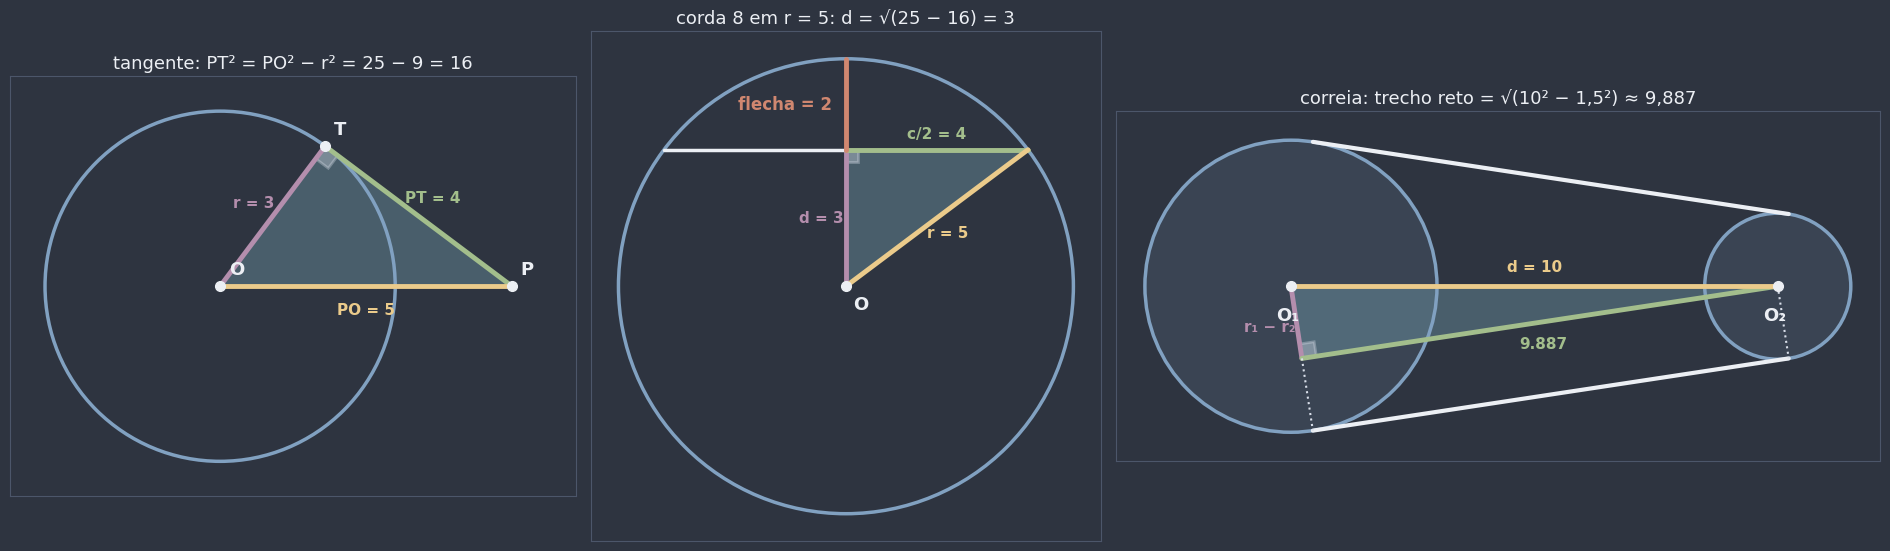

trecho reto da correia: medido 9.8869, pela fórmula 9.8869


In [20]:
def tangente_comum(O1, r1: float, O2, r2: float, interna: bool = False):
    """Pontos de tangência (T1, T2) de uma tangente comum às circunferências λ(O1, r1) e λ(O2, r2). A direção n,
    perpendicular à tangente, tem componente (r2 ∓ r1)/d ao longo de O1O2; a outra componente sai de Pitágoras
    (n tem tamanho 1)."""
    O1, O2 = np.asarray(O1, dtype=float), np.asarray(O2, dtype=float)
    d = math.dist(O1, O2)
    u = (O2 - O1) / d
    v = np.array([-u[1], u[0]])
    ao_longo = (r2 + r1) / d if interna else (r2 - r1) / d
    n = ao_longo * u + math.sqrt(1 - ao_longo**2) * v
    return O1 - r1 * n, O2 + (r2 if interna else -r2) * n


fig, eixos = plt.subplots(1, 3, figsize=(19, 6.6), gridspec_kw={"width_ratios": [1, 0.9, 1.35]})
fig.patch.set_facecolor(NORD_FUNDO)

# O segmento tangente: O = (0, 0), r = 3, P = (5, 0)
ax = eixos[0]
O_f, r_f, P_f = np.array([0.0, 0.0]), 3.0, np.array([5.0, 0.0])
T_f = ponto_de_tangencia(O_f, r_f, P_f)
desenhar_circunferencia(ax, O_f, r_f, cor=COR_CIRCULO)
ax.add_patch(Polygon([T_f, O_f, P_f], closed=True, facecolor=COR_TRIANGULO, alpha=0.3, edgecolor="none"))
desenhar_segmento(ax, O_f, T_f, cor=COR_CATETO_C, largura=3.5)
desenhar_segmento(ax, T_f, P_f, cor=COR_CATETO_B, largura=3.5)
desenhar_segmento(ax, O_f, P_f, cor=COR_HIPOTENUSA, largura=3.5)
desenhar_arco(ax, T_f, O_f, P_f, raio=0.45, cor=NORD_TEXTO_SEC)
for P, Q, texto, cor in ((O_f, T_f, "r = 3", COR_CATETO_C), (T_f, P_f, f"PT = {math.dist(T_f, P_f):.0f}",
                         COR_CATETO_B), (O_f, P_f, "PO = 5", COR_HIPOTENUSA)):
    rotular_segmento(ax, P, Q, texto, cor=cor, distancia=0.4, longe_de=(T_f + O_f + P_f) / 3)
for X, nome in ((O_f, "O"), (T_f, "T"), (P_f, "P")):
    desenhar_ponto(ax, X, nome, cor=NORD_TEXTO, deslocamento=(0.15, 0.2))
preparar_eixo(ax, [(-3, -3), (5.5, 3)], margem=0.6)
ax.set_title("tangente: PT² = PO² − r² = 25 − 9 = 16", color=NORD_TEXTO, fontsize=13)

# A corda e a flecha: r = 5, corda 8
ax = eixos[1]
O_f, r_f, corda = np.array([0.0, 0.0]), 5.0, 8.0
d_f = math.sqrt(r_f**2 - (corda / 2) ** 2)
X1, X2, M_f = np.array([-corda / 2, d_f]), np.array([corda / 2, d_f]), np.array([0.0, d_f])
desenhar_circunferencia(ax, O_f, r_f, cor=COR_CIRCULO)
desenhar_segmento(ax, X1, X2, cor=NORD_TEXTO, largura=2.5)
ax.add_patch(Polygon([M_f, O_f, X2], closed=True, facecolor=COR_TRIANGULO, alpha=0.3, edgecolor="none"))
desenhar_segmento(ax, O_f, M_f, cor=COR_CATETO_C, largura=3.5)
desenhar_segmento(ax, M_f, X2, cor=COR_CATETO_B, largura=3.5)
desenhar_segmento(ax, O_f, X2, cor=COR_HIPOTENUSA, largura=3.5)
desenhar_segmento(ax, M_f, (0, r_f), cor=COR_ALTURA, largura=3.5)
desenhar_arco(ax, M_f, O_f, X2, raio=0.45, cor=NORD_TEXTO_SEC)
rotular_segmento(ax, O_f, M_f, f"d = {d_f:g}", cor=COR_CATETO_C, distancia=0.55, longe_de=X2)
rotular_segmento(ax, M_f, X2, "c/2 = 4", cor=COR_CATETO_B, distancia=0.35, longe_de=O_f)
rotular_segmento(ax, O_f, X2, "r = 5", cor=COR_HIPOTENUSA, distancia=0.4, longe_de=M_f)
ax.text(-0.3, (d_f + r_f) / 2, f"flecha = {r_f - d_f:g}", color=COR_ALTURA, fontsize=12, fontweight="bold",
        ha="right", va="center")
desenhar_ponto(ax, O_f, "O", cor=NORD_TEXTO, deslocamento=(0.15, -0.5))
preparar_eixo(ax, [(-5, -5), (5, 5)], margem=0.6)
ax.set_title("corda 8 em r = 5: d = √(25 − 16) = 3", color=NORD_TEXTO, fontsize=13)

# A correia entre duas polias (tangentes comuns externas)
ax = eixos[2]
O1_f, r1_f, O2_f, r2_f = np.array([0.0, 0.0]), 3.0, np.array([10.0, 0.0]), 1.5
desenhar_circunferencia(ax, O1_f, r1_f, cor=COR_CIRCULO, preencher=True)
desenhar_circunferencia(ax, O2_f, r2_f, cor=COR_CIRCULO, preencher=True)
T1, T2 = tangente_comum(O1_f, r1_f, O2_f, r2_f)
T1b, T2b = tangente_comum(O2_f, r2_f, O1_f, r1_f)  # a outra tangente externa (trocando os papéis)
for P, Q in ((T1, T2), (T1b, T2b)):
    desenhar_segmento(ax, P, Q, cor=NORD_TEXTO, largura=3)
S = O1_f - (r1_f - r2_f) * (O1_f - T1) / r1_f  # o pé da paralela à tangente traçada por O2
ax.add_patch(Polygon([S, O1_f, O2_f], closed=True, facecolor=COR_TRIANGULO, alpha=0.3, edgecolor="none"))
desenhar_segmento(ax, O1_f, S, cor=COR_CATETO_C, largura=3.5)
desenhar_segmento(ax, S, O2_f, cor=COR_CATETO_B, largura=3.5)
desenhar_segmento(ax, O1_f, O2_f, cor=COR_HIPOTENUSA, largura=3.5)
desenhar_segmento(ax, S, T1, cor=NORD_TEXTO_SEC, largura=1.5, estilo=":")
desenhar_segmento(ax, O2_f, T2, cor=NORD_TEXTO_SEC, largura=1.5, estilo=":")
desenhar_arco(ax, S, O1_f, O2_f, raio=0.5, cor=NORD_TEXTO_SEC)
rotular_segmento(ax, O1_f, S, "r₁ − r₂", cor=COR_CATETO_C, distancia=0.55, longe_de=O2_f)
rotular_segmento(ax, S, O2_f, f"{math.dist(T1, T2):.3f}", cor=COR_CATETO_B, distancia=0.45, longe_de=O1_f)
rotular_segmento(ax, O1_f, O2_f, "d = 10", cor=COR_HIPOTENUSA, distancia=0.4, longe_de=S)
for X, nome in ((O1_f, "O₁"), (O2_f, "O₂")):
    desenhar_ponto(ax, X, nome, cor=NORD_TEXTO, deslocamento=(-0.3, -0.7))
preparar_eixo(ax, [(-3, -3), (11.5, 3)], margem=0.6)
ax.set_title(f"correia: trecho reto = √(10² − 1,5²) ≈ {math.sqrt(100 - 2.25):.3f}".replace(".", ","), color=NORD_TEXTO,
             fontsize=13)
plt.tight_layout()
plt.show()

print(f"trecho reto da correia: medido {math.dist(T1, T2):.4f}, pela fórmula {math.sqrt(10**2 - 1.5**2):.4f}")

🕹️ **Widget interativo — as duas circunferências do triângulo retângulo:** de novo o vértice $A$ anda pela semicircunferência de diâmetro $\overline{BC}$, com $a = 10$. A circunscrita (azul) **não se mexe**: o seu centro é sempre o ponto médio $M$ da hipotenusa, e o raio é sempre 5. A inscrita (laranja) muda de tamanho, junto com o quadrado $AT_cIT_b$ de lado $r$. O painel confere $R = \frac{a}{2}$, a mediana $AM = \frac{a}{2}$ e $r = \frac{b + c - a}{2}$. Em que posição de $A$ o raio $r$ é o maior possível?

In [21]:
def explorar_circunferencias(posicao: float) -> None:
    A_w, B_w, C_w = triangulo_retangulo(10.0, posicao)
    a, b, c = lados([A_w, B_w, C_w])
    O_w, I_w = circuncentro(A_w, B_w, C_w), incentro(A_w, B_w, C_w)
    M_w = ponto_medio(B_w, C_w)
    r_w = distancia_ponto_reta(I_w, B_w, C_w)
    Ta, Tb, Tc = pe_da_altura(I_w, B_w, C_w), pe_da_altura(I_w, C_w, A_w), pe_da_altura(I_w, A_w, B_w)

    fig, (ax, ax_lista) = plt.subplots(1, 2, figsize=(15, 6.8), gridspec_kw={"width_ratios": [1.3, 1]})
    fig.patch.set_facecolor(NORD_FUNDO)
    desenhar_circunferencia(ax, O_w, math.dist(O_w, A_w), cor=COR_CIRCULO)
    ax.add_patch(Polygon([A_w, B_w, C_w], closed=True, facecolor=COR_TRIANGULO, alpha=0.12, edgecolor="none"))
    ax.add_patch(Polygon([A_w, Tc, I_w, Tb], closed=True, facecolor=COR_ALTURA, alpha=0.3, edgecolor=COR_ALTURA, lw=1.5))
    desenhar_circunferencia(ax, I_w, r_w, cor=COR_ALTURA, largura=2.2)
    desenhar_segmento(ax, B_w, C_w, cor=COR_HIPOTENUSA, largura=3.5)
    desenhar_segmento(ax, C_w, A_w, cor=COR_CATETO_B, largura=3.5)
    desenhar_segmento(ax, A_w, B_w, cor=COR_CATETO_C, largura=3.5)
    desenhar_segmento(ax, A_w, M_w, cor=COR_CIRCULO, largura=2, estilo="--")
    desenhar_arco(ax, A_w, B_w, C_w, raio=0.6, cor=NORD_TEXTO_SEC)
    for X, nome in ((A_w, "A"), (B_w, "B"), (C_w, "C")):
        desenhar_ponto(ax, X, cor=NORD_TEXTO)
        rotular_fora(ax, X, nome, O_w + (0, 0.01), distancia=0.5, tamanho=13)
    desenhar_ponto(ax, M_w, "M", cor=COR_CIRCULO, deslocamento=(0.1, -0.6))
    desenhar_ponto(ax, I_w, "I", cor=COR_ALTURA, deslocamento=(0.12, 0.12))
    for T in (Ta, Tb, Tc):
        desenhar_ponto(ax, T, cor=COR_ALTURA)
    rotular_segmento(ax, B_w, Tc, f"c − r = {c - r_w:.2f}", cor=COR_CATETO_C, distancia=0.5, longe_de=I_w, tamanho=10)
    rotular_segmento(ax, Tb, C_w, f"b − r = {b - r_w:.2f}", cor=COR_CATETO_B, distancia=0.5, longe_de=I_w, tamanho=10)
    preparar_eixo(ax, [(-0.2, -5.2), (10.2, 5.2)], margem=0.5)
    ax.set_title(f"R = {math.dist(O_w, A_w):.3f} (fixo)   r = {r_w:.3f}", color=NORD_TEXTO, fontsize=13)

    itens = [
        ("circuncentro = ponto médio M da hipotenusa", bool(np.allclose(O_w, M_w))),
        (f"R = MA = MB = MC = {math.dist(M_w, A_w):.3f} = a/2", iguais(math.dist(M_w, A_w), a / 2)),
        (f"mediana AM = {math.dist(A_w, M_w):.3f} = metade da hipotenusa", iguais(math.dist(A_w, M_w), a / 2)),
        (f"AT_c = AT_b = {math.dist(A_w, Tc):.3f} = r  (quadrado)", iguais(math.dist(A_w, Tc), r_w)),
        (f"BT_a = {math.dist(B_w, Ta):.3f} = c − r;  CT_a = {math.dist(C_w, Ta):.3f} = b − r",
         iguais(math.dist(B_w, Ta), c - r_w) and iguais(math.dist(C_w, Ta), b - r_w)),
        (f"r medido = {r_w:.4f}   (b + c − a)/2 = {(b + c - a) / 2:.4f}", iguais(r_w, (b + c - a) / 2)),
    ]
    escrever_checklist(ax_lista, itens, "Circunscrita e inscrita")
    plt.tight_layout()
    plt.show()


widgets.interact(
    explorar_circunferencias,
    posicao=widgets.IntSlider(value=120, min=15, max=165, step=1, description="posição:"),
);

interactive(children=(IntSlider(value=120, description='posição:', max=165, min=15), Output()), _dom_classes=(…

O raio inscrito é máximo com $A$ no ponto mais alto (posição 90°): o triângulo é **isósceles**, $b = c = \frac{a}{\sqrt{2}} = 5\sqrt{2}$ (um 45°–45°–90°!) e $r = \frac{2 \cdot 5\sqrt{2} - 10}{2} = 5\sqrt{2} - 5 \approx 2{,}07$.

⚠️ **Erro comum: dizer que o circuncentro de todo triângulo fica no ponto médio de um lado.** Isso só vale para o triângulo **retângulo**, e o lado é a **hipotenusa**. Lembre a tabela de [`0410a_pontos_notaveis_do_triangulo.ipynb`](0410a_pontos_notaveis_do_triangulo.ipynb): no acutângulo, o circuncentro fica **dentro** do triângulo; no obtusângulo, **fora**; só no retângulo ele cai **sobre** um lado.

⚠️ **Erro comum: trocar a ordem em $PT^2 = PO^2 - r^2$.** A hipotenusa do triângulo $OTP$ é $\overline{PO}$ (oposta ao ângulo reto em $T$), e não o raio nem a tangente. Se $PO = 13$ e $r = 5$, então $PT = 12$, e não $\sqrt{13^2 + 5^2}$.

**Pergunta de checagem:** um triângulo retângulo tem catetos 5 e 12. Quais são os raios das circunferências circunscrita e inscrita?

**Pergunta de checagem:** por que, no widget, a circunferência circunscrita não muda de tamanho, mas a inscrita muda?

## Resumo — cheat sheet

**Notação fixa:** triângulo $ABC$ retângulo em $A$; hipotenusa $a = BC$; catetos $b = CA$ e $c = AB$; altura relativa à hipotenusa $h = AH$; projeções $m = BH$ (de $c$) e $n = HC$ (de $b$), com $m + n = a$.

| Conceito | Ideia-chave |
|---|---|
| **Três triângulos semelhantes** | $\triangle ABC \sim \triangle HBA \sim \triangle HAC$ (AA: ângulo reto + ângulo agudo comum) |
| **Relações métricas** | $c^2 = a \cdot m$; $\;b^2 = a \cdot n$; $\;h^2 = m \cdot n$; $\;b \cdot c = a \cdot h$ ($h = \frac{bc}{a}$) |
| **Média geométrica** | $h = \sqrt{m \cdot n}$ (também pela potência de ponto de $H$) |
| **Teorema de Pitágoras** | $a^2 = b^2 + c^2$ (somando $c^2 = a \cdot m$ e $b^2 = a \cdot n$; ou por áreas no quadrado de lado $b + c$) |
| **Recíproca** | $a^2 = b^2 + c^2$ ⇒ triângulo retângulo (por LLL) |
| **Classificação pelos lados** ($a$ = maior lado) | $a^2 < b^2 + c^2$ acutângulo; $=$ retângulo; $>$ obtusângulo (antes: desigualdade triangular) |
| **Ternos pitagóricos** | $(3, 4, 5)$, $(5, 12, 13)$, $(8, 15, 17)$, $(7, 24, 25)$; múltiplos também; Euclides: $(p^2 - q^2,\ 2pq,\ p^2 + q^2)$ |
| **45°–45°–90°** | $x$, $x$, $x\sqrt{2}$ → diagonal do quadrado $\ell\sqrt{2}$ |
| **30°–60°–90°** | $x$ (oposto a 30°), $x\sqrt{3}$ (oposto a 60°), $2x$ → altura do equilátero $\frac{\ell\sqrt{3}}{2}$; raios $r = \frac{\ell\sqrt{3}}{6}$ e $R = \frac{\ell\sqrt{3}}{3}$ |
| **Distância entre pontos** | $d = \sqrt{(\Delta x)^2 + (\Delta y)^2}$ |
| **Diagonal do retângulo / lado do losango** | $\sqrt{a^2 + b^2}$ / $\sqrt{\left(\frac{d_1}{2}\right)^2 + \left(\frac{d_2}{2}\right)^2}$ |
| **Altura do trapézio isósceles** | $\sqrt{\ell^2 - \left(\frac{B - b}{2}\right)^2}$ |
| **Circunscrita** | $R = \frac{a}{2}$, circuncentro no ponto médio da hipotenusa; mediana relativa à hipotenusa $= \frac{a}{2}$ |
| **Inscrita** | $r = \frac{b + c - a}{2}$ (quadrado de lado $r$ no canto reto + segmentos tangentes) |
| **Tangente** | $PT^2 = PO^2 - r^2$ $(= \operatorname{Pot}(P))$ |
| **Corda** | distância ao centro $d = \sqrt{r^2 - \left(\frac{c}{2}\right)^2}$; flecha $r - d$ |

**A cadeia:** Tales (0414a) → semelhança (0415a) → relações métricas → Pitágoras. A partir daqui, Pitágoras é ferramenta oficial em todos os notebooks.

As figuras abaixo repetem as cores do notebook: hipotenusa amarela, cateto $b$ e a sua projeção verdes, cateto $c$ e a sua projeção roxos, altura laranja.

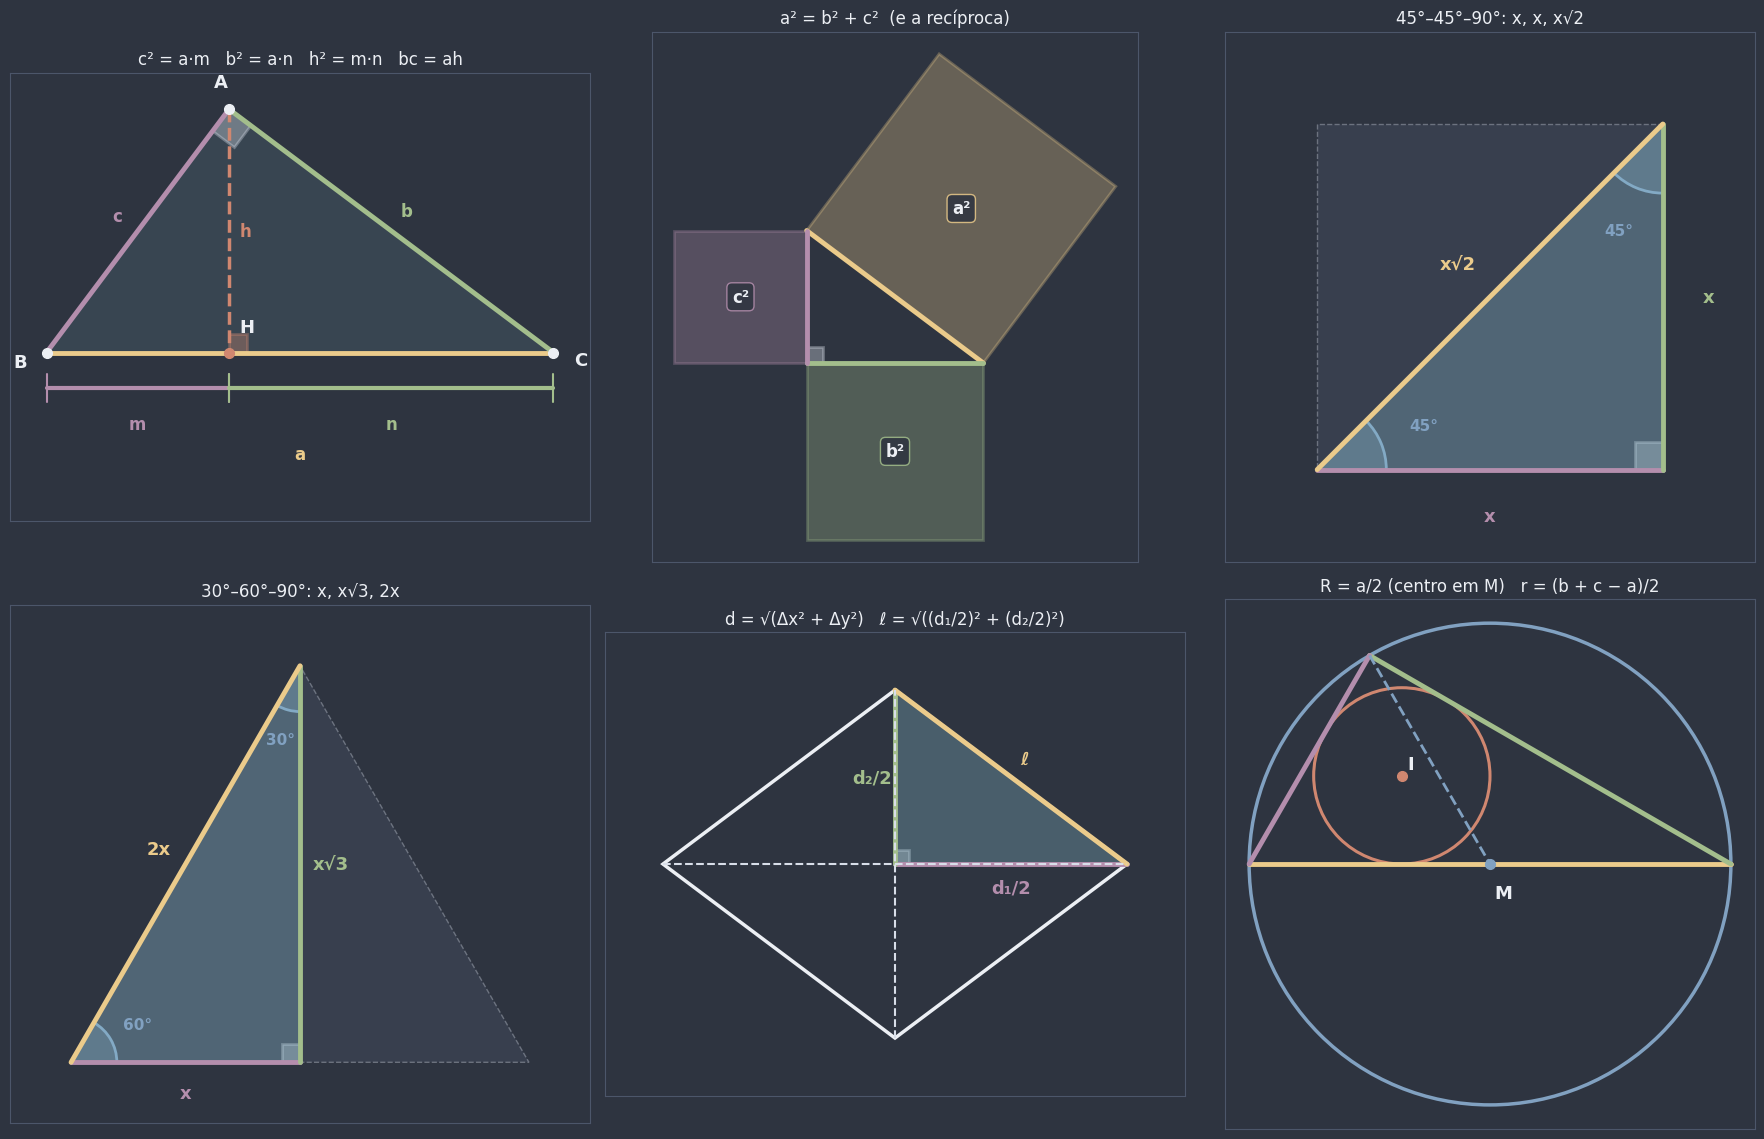

In [22]:
# Esta célula só usa as ferramentas da primeira célula de código: pode ser executada sozinha, para revisão.
def desenhar_triangulo_destacado(ax, R, P, Q, rotulos, nomes_angulos=None, raio: float = 0.5) -> None:
    # Triângulo retângulo em R com as cores fixas: RP roxo, RQ verde, PQ (hipotenusa) amarelo
    centro = (R + P + Q) / 3
    ax.add_patch(Polygon([R, P, Q], closed=True, facecolor=COR_TRIANGULO, alpha=0.3, edgecolor="none", zorder=2))
    for (X, Y), cor, rotulo in zip(((R, P), (R, Q), (P, Q)), (COR_CATETO_C, COR_CATETO_B, COR_HIPOTENUSA), rotulos):
        desenhar_segmento(ax, X, Y, cor=cor, largura=3.5)
        rotular_segmento(ax, X, Y, rotulo, cor=cor, distancia=0.8 * raio, longe_de=centro, tamanho=13)
    desenhar_arco(ax, R, P, Q, raio=0.8 * raio, cor=NORD_TEXTO_SEC)
    if nomes_angulos:
        desenhar_arco(ax, P, R, Q, raio=1.2 * raio, cor=COR_SECUNDARIA, rotulo=nomes_angulos[0], raio_rotulo=2 * raio)
        desenhar_arco(ax, Q, R, P, raio=1.2 * raio, cor=COR_SECUNDARIA, rotulo=nomes_angulos[1], raio_rotulo=2 * raio)


fig, eixos = plt.subplots(2, 3, figsize=(18, 11.5))
fig.patch.set_facecolor(NORD_FUNDO)

# Relações métricas
ax = eixos[0, 0]
A_res, B_res, C_res = np.array([9.0, 12.0]), np.array([0.0, 0.0]), np.array([25.0, 0.0])
desenhar_elementos(ax, A_res, B_res, C_res, valores=False)
preparar_eixo(ax, [A_res, B_res, C_res, (12.5, -6.5)], margem=1.8)
ax.set_title("c² = a·m   b² = a·n   h² = m·n   bc = ah", color=NORD_TEXTO, fontsize=12)

# Pitágoras (o triângulo 3–4–5 do gancho)
ax = eixos[0, 1]
A_res, B_res, C_res = np.array([0.0, 0.0]), np.array([0.0, 3.0]), np.array([4.0, 0.0])
centro_res = (A_res + B_res + C_res) / 3
pontos_res = []
for P, Q, cor, nome in ((B_res, C_res, COR_HIPOTENUSA, "a²"), (C_res, A_res, COR_CATETO_B, "b²"),
                        (A_res, B_res, COR_CATETO_C, "c²")):
    pontos_res += desenhar_quadrado_no_lado(ax, P, Q, centro_res, cor, rotulo=nome)
    desenhar_segmento(ax, P, Q, cor=cor, largura=3.5)
desenhar_arco(ax, A_res, B_res, C_res, raio=0.6, cor=NORD_TEXTO_SEC)
preparar_eixo(ax, pontos_res, margem=0.5)
ax.set_title("a² = b² + c²  (e a recíproca)", color=NORD_TEXTO, fontsize=12)

# 45°–45°–90°: metade do quadrado de lado 3
ax = eixos[0, 2]
quadrado = [np.array(p, dtype=float) for p in ((0, 0), (3, 0), (3, 3), (0, 3))]
ax.add_patch(Polygon(quadrado, closed=True, facecolor=NORD_LINHA, alpha=0.35, edgecolor=NORD_TEXTO_SEC, ls="--"))
desenhar_triangulo_destacado(ax, quadrado[1], quadrado[0], quadrado[2], ("x", "x", "x√2"), ("45°", "45°"))
preparar_eixo(ax, quadrado, margem=0.8)
ax.set_title("45°–45°–90°: x, x, x√2", color=NORD_TEXTO, fontsize=12)

# 30°–60°–90°: metade do equilátero de lado 6
ax = eixos[1, 0]
equilatero = triangulo_por_lados(6, 6, 6)
M_res = pe_da_altura(equilatero[2], equilatero[0], equilatero[1])
ax.add_patch(Polygon(equilatero, closed=True, facecolor=NORD_LINHA, alpha=0.35, edgecolor=NORD_TEXTO_SEC, ls="--"))
desenhar_triangulo_destacado(ax, M_res, equilatero[0], equilatero[2], ("x", "x√3", "2x"), ("60°", "30°"))
preparar_eixo(ax, equilatero, margem=0.8)
ax.set_title("30°–60°–90°: x, x√3, 2x", color=NORD_TEXTO, fontsize=12)

# Distância entre pontos e losango
ax = eixos[1, 1]
losango = [np.array(p, dtype=float) for p in ((-4, 0), (0, -3), (4, 0), (0, 3))]
ax.add_patch(Polygon(losango, closed=True, fill=False, edgecolor=NORD_TEXTO, lw=2.5))
desenhar_triangulo_destacado(ax, np.array([0.0, 0.0]), np.array([4.0, 0.0]), np.array([0.0, 3.0]),
                             ("d₁/2", "d₂/2", "ℓ"))
desenhar_segmento(ax, losango[0], losango[2], cor=NORD_TEXTO_SEC, largura=1.5, estilo="--")
desenhar_segmento(ax, losango[1], losango[3], cor=NORD_TEXTO_SEC, largura=1.5, estilo="--")
preparar_eixo(ax, losango, margem=1.0)
ax.set_title("d = √(Δx² + Δy²)   ℓ = √((d₁/2)² + (d₂/2)²)", color=NORD_TEXTO, fontsize=12)

# Circunscrita e inscrita
ax = eixos[1, 2]
A_res, B_res, C_res = triangulo_retangulo(10.0, 120)
O_res, I_res = circuncentro(A_res, B_res, C_res), incentro(A_res, B_res, C_res)
desenhar_circunferencia(ax, O_res, 5.0, cor=COR_CIRCULO)
desenhar_circunferencia(ax, I_res, distancia_ponto_reta(I_res, B_res, C_res), cor=COR_ALTURA, largura=2.2)
for P, Q, cor in ((B_res, C_res, COR_HIPOTENUSA), (C_res, A_res, COR_CATETO_B), (A_res, B_res, COR_CATETO_C)):
    desenhar_segmento(ax, P, Q, cor=cor, largura=3.5)
desenhar_segmento(ax, A_res, O_res, cor=COR_CIRCULO, largura=2, estilo="--")
desenhar_ponto(ax, O_res, "M", cor=COR_CIRCULO, deslocamento=(0.1, -0.7))
desenhar_ponto(ax, I_res, "I", cor=COR_ALTURA)
preparar_eixo(ax, [(0, -5), (10, 5)], margem=0.5)
ax.set_title("R = a/2 (centro em M)   r = (b + c − a)/2", color=NORD_TEXTO, fontsize=12)
plt.tight_layout()
plt.show()

## Exercícios

**Básico**
1. Pitágoras direto: lados, ternos, diagonais e alturas.
2. As relações métricas a partir de duas medidas.

**Intermediário**

3. Implementar `classifica_por_lados`, `eh_retangulo` e `ternos_primitivos` (e testar com contraexemplos).
4. As relações métricas, $R = \frac{a}{2}$ e $r = \frac{b + c - a}{2}$ conferidas com sorteios.
5. Problemas de dois ou três passos: trapézio, losango, tangente, escada e corda.

**Desafio**

6. A espiral de Teodoro.
7. Os quatro "centros" de um triângulo retângulo.

Gabarito completo com resolução comentada em [`0416b_triangulos_retangulos_gabarito.ipynb`](0416b_triangulos_retangulos_gabarito.ipynb).

### Básico

In [ ]:
# Exercício Básico 1: Pitágoras direto.
# (a) Os catetos de um triângulo retângulo medem 9 e 12. Guarde a hipotenusa em `hipotenusa_ex1a`.
# (b) A hipotenusa mede 17 e um cateto mede 8. Guarde o outro cateto em `cateto_ex1b`.
# (c) Dos trios (6, 8, 10), (5, 12, 14), (9, 40, 41), (10, 24, 26) e (7, 8, 11), guarde em `ternos_ex1c` a LISTA
#     (na mesma ordem) dos que são ternos pitagóricos.
# (d) Guarde a diagonal do quadrado de lado 6 em `diagonal_quadrado_ex1d` e a do retângulo 5 × 12 em
#     `diagonal_retangulo_ex1d`.
# (e) Guarde a altura do triângulo equilátero de lado 8 em `altura_equilatero_ex1e`.
hipotenusa_ex1a = ...
cateto_ex1b = ...
ternos_ex1c = ...
diagonal_quadrado_ex1d = ...
diagonal_retangulo_ex1d = ...
altura_equilatero_ex1e = ...

print(hipotenusa_ex1a, cateto_ex1b, ternos_ex1c, diagonal_quadrado_ex1d, diagonal_retangulo_ex1d,
      altura_equilatero_ex1e)

In [ ]:
# Verificação
assert hipotenusa_ex1a is not ... and math.isclose(hipotenusa_ex1a, 15), (
    "Tente de novo, revise: a² = b² + c² = 81 + 144 (seção 2 - O Teorema de Pitágoras, a recíproca e os ternos)."
)
assert cateto_ex1b is not ... and math.isclose(cateto_ex1b, 15), (
    "Tente de novo, revise: o cateto que falta é √(a² − c²) = √(289 − 64), e não √(17² + 8²) (seção 2 - O Teorema "
    "de Pitágoras, a recíproca e os ternos)."
)
assert ternos_ex1c is not ... and [tuple(t) for t in ternos_ex1c] == [(6, 8, 10), (9, 40, 41), (10, 24, 26)], (
    "Tente de novo, revise: compare o quadrado do MAIOR número com a soma dos quadrados dos outros dois (seção 2 - "
    "O Teorema de Pitágoras, a recíproca e os ternos)."
)
assert diagonal_quadrado_ex1d is not ... and math.isclose(diagonal_quadrado_ex1d, 6 * math.sqrt(2)), (
    "Tente de novo, revise: a diagonal do quadrado de lado ℓ é ℓ√2 (seção 3 - Triângulos retângulos notáveis)."
)
assert diagonal_retangulo_ex1d is not ... and math.isclose(diagonal_retangulo_ex1d, 13), (
    "Tente de novo, revise: a diagonal do retângulo é √(a² + b²) (seção 4 - Aplicações no plano)."
)
assert altura_equilatero_ex1e is not ... and math.isclose(altura_equilatero_ex1e, 4 * math.sqrt(3)), (
    "Tente de novo, revise: a altura do equilátero de lado ℓ é ℓ√3/2 (seção 3 - Triângulos retângulos notáveis)."
)
print("Certo!")

In [ ]:
# Exercício Básico 2: as relações métricas. Em todos os itens, ABC é retângulo em A, com a notação do notebook
# (a = hipotenusa, b e c = catetos, h = altura relativa à hipotenusa, m = projeção de c, n = projeção de b).
# (a) As projeções medem m = 2 e n = 8. Guarde h em `h_ex2a`, a em `a_ex2a`, b em `b_ex2a` e c em `c_ex2a`.
# (b) A hipotenusa mede 25 e a altura relativa a ela mede 12. Guarde as projeções, como uma tupla
#     (menor, maior), em `projecoes_ex2b`. (Dica: m + n e m · n são conhecidos; lembre a soma e o produto das
#     raízes de 0109a, ou teste valores.)
# (c) Os catetos medem c = 6 e b = 8. Guarde a altura relativa à hipotenusa em `h_ex2c` e as projeções em
#     `m_ex2c` e `n_ex2c`.
h_ex2a = ...
a_ex2a = ...
b_ex2a = ...
c_ex2a = ...
projecoes_ex2b = ...
h_ex2c = ...
m_ex2c = ...
n_ex2c = ...

print(h_ex2a, a_ex2a, b_ex2a, c_ex2a, projecoes_ex2b, h_ex2c, m_ex2c, n_ex2c)

In [ ]:
# Verificação
assert h_ex2a is not ... and math.isclose(h_ex2a, 4) and a_ex2a is not ... and math.isclose(a_ex2a, 10), (
    "Tente de novo, revise: h² = m·n e a = m + n (seção 1 - Elementos e relações métricas)."
)
assert b_ex2a is not ... and math.isclose(b_ex2a, math.sqrt(80)) and c_ex2a is not ... and \
    math.isclose(c_ex2a, math.sqrt(20)), (
    "Tente de novo, revise: b² = a·n e c² = a·m, cada cateto com a SUA projeção (seção 1 - Elementos e relações "
    "métricas)."
)
assert projecoes_ex2b is not ... and len(projecoes_ex2b) == 2 and math.isclose(projecoes_ex2b[0], 9) and \
    math.isclose(projecoes_ex2b[1], 16), (
    "Tente de novo, revise: m + n = 25 e m·n = h² = 144 (seção 1 - Elementos e relações métricas)."
)
assert h_ex2c is not ... and math.isclose(h_ex2c, 4.8), (
    "Tente de novo, revise: a = 10 por Pitágoras e b·c = a·h (seção 1 - Elementos e relações métricas)."
)
assert m_ex2c is not ... and math.isclose(m_ex2c, 3.6) and n_ex2c is not ... and math.isclose(n_ex2c, 6.4), (
    "Tente de novo, revise: m = c²/a e n = b²/a, com c = 6 e b = 8 (seção 1 - Elementos e relações métricas)."
)
print("Certo!")

### Intermediário

In [ ]:
# Exercício Intermediário 3: as funções da seção 2, escritas por você.
# (a) Complete classifica_por_lados_ex3(x, y, z), que recebe três medidas positivas em QUALQUER ordem e devolve uma
#     das strings "não forma triângulo", "acutângulo", "retângulo" ou "obtusângulo". Ordene as medidas, teste a
#     desigualdade triangular ANTES de tudo e compare o quadrado do maior lado com a soma dos quadrados dos outros
#     dois usando math.isclose (para aceitar decimais como 0.3, 0.4, 0.5). Não use classifica_por_lados.
# (b) Complete eh_retangulo_ex3(x, y, z), que devolve True ou False (pode usar a função do item a).
# (c) Complete ternos_primitivos_ex3(limite), que devolve a lista dos ternos pitagóricos PRIMITIVOS com hipotenusa
#     até `limite`, cada um como uma tupla (cateto menor, cateto maior, hipotenusa), ordenada com sorted(). Use a
#     fórmula de Euclides: p > q > 0, p e q coprimos (gcd) e de paridades diferentes. Não use ternos_primitivos.
def classifica_por_lados_ex3(x: float, y: float, z: float) -> str:
    ...


def eh_retangulo_ex3(x: float, y: float, z: float) -> bool:
    ...


def ternos_primitivos_ex3(limite: int) -> list[tuple[int, int, int]]:
    ...


print(classifica_por_lados_ex3(5, 13, 12), eh_retangulo_ex3(2, 3, 4), ternos_primitivos_ex3(30))

In [ ]:
# Verificação
casos_ex3 = [((3, 4, 5), "retângulo"), ((5, 13, 12), "retângulo"), ((0.3, 0.5, 0.4), "retângulo"),
             ((1, 1, math.sqrt(2)), "retângulo"), ((6, 7, 9), "acutângulo"), ((5, 5, 5), "acutângulo"),
             ((4, 5, 7), "obtusângulo"), ((7, 2, 6), "obtusângulo"), ((1, 2, 3), "não forma triângulo"),
             ((2, 10, 3), "não forma triângulo")]
for lados_t, resposta in casos_ex3:
    assert classifica_por_lados_ex3(*lados_t) == resposta, (
        f"Tente de novo, revise: os lados {lados_t} formam um triângulo '{resposta}'; ordene, teste a desigualdade "
        "triangular primeiro e use math.isclose (seção 2 - O Teorema de Pitágoras, a recíproca e os ternos)."
    )
for lados_t, resposta in casos_ex3:
    assert eh_retangulo_ex3(*lados_t) == (resposta == "retângulo"), (
        f"Tente de novo, revise: eh_retangulo_ex3{lados_t} deveria dar {resposta == 'retângulo'} (seção 2 - O Teorema "
        "de Pitágoras, a recíproca e os ternos)."
    )
for limite_t in (30, 100, 1000):
    certos = sorted((x, y, z) for z in range(1, limite_t + 1) for y in range(1, z) for x in range(1, y)
                    if x * x + y * y == z * z and gcd(gcd(x, y), z) == 1) if limite_t <= 100 else None
    obtidos = ternos_primitivos_ex3(limite_t)
    assert obtidos is not None and all(x * x + y * y == z * z and gcd(gcd(x, y), z) == 1 and x < y and z <= limite_t
                                       for x, y, z in obtidos), (
        "Tente de novo, revise: cada terno deve ser (cateto menor, cateto maior, hipotenusa), primitivo e com "
        "hipotenusa até o limite (seção 2 - O Teorema de Pitágoras, a recíproca e os ternos)."
    )
    assert certos is None or list(obtidos) == certos, (
        f"Tente de novo, revise: com limite {limite_t}, faltam ou sobram ternos; confira p > q, gcd(p, q) == 1 e "
        "p − q ímpar, e ordene com sorted() (seção 2 - O Teorema de Pitágoras, a recíproca e os ternos)."
    )
assert len(ternos_primitivos_ex3(1000)) == 158, (
    "Tente de novo, revise: existem 158 ternos primitivos com hipotenusa até 1000 (seção 2 - O Teorema de "
    "Pitágoras, a recíproca e os ternos)."
)
print("Certo!")

In [ ]:
# Exercício Intermediário 4: as fórmulas do notebook conferidas com sorteios.
# Com gerador_ex4 = np.random.default_rng(4), sorteie 100 triângulos retângulos: em cada um, sorteie a hipotenusa
# a_t = gerador_ex4.uniform(1, 30) e depois a posição p_t = gerador_ex4.uniform(5, 175), NESSA ORDEM, e construa
# A, B, C = triangulo_retangulo(a_t, p_t). Para cada triângulo, calcule (use elementos, circuncentro, incentro e
# distancia_ponto_reta):
#   • o erro das relações métricas: o maior entre |c² − a·m|, |b² − a·n|, |h² − m·n| e |b·c − a·h|;
#   • o erro do circunraio: |MA − a/2|, com M = circuncentro(A, B, C);
#   • o erro do inraio: |r − (b + c − a)/2|, com r = distância do incentro à reta BC.
# Guarde o MAIOR erro de cada tipo, entre os 100 triângulos, em `erro_relacoes_ex4`, `erro_R_ex4` e `erro_r_ex4`,
# e guarde em `circuncentro_no_meio_ex4` True se, em TODOS os triângulos, o circuncentro coincidiu com o ponto
# médio da hipotenusa (use np.allclose).
gerador_ex4 = np.random.default_rng(4)

erro_relacoes_ex4 = ...
erro_R_ex4 = ...
erro_r_ex4 = ...
circuncentro_no_meio_ex4 = ...

print(erro_relacoes_ex4, erro_R_ex4, erro_r_ex4, circuncentro_no_meio_ex4)

In [ ]:
# Verificação
assert erro_relacoes_ex4 is not ... and 0 <= erro_relacoes_ex4 < 1e-8, (
    "Tente de novo, revise: para cada triângulo, calcule os quatro |lado esquerdo − lado direito| e guarde o maior "
    "(seção 1 - Elementos e relações métricas)."
)
assert erro_R_ex4 is not ... and 0 <= erro_R_ex4 < 1e-8, (
    "Tente de novo, revise: R é a distância do circuncentro a um vértice, e deve ser a/2 (seção 5 - O triângulo "
    "retângulo e a circunferência)."
)
assert erro_r_ex4 is not ... and 0 <= erro_r_ex4 < 1e-8, (
    "Tente de novo, revise: r é a distância do incentro a um lado, e deve ser (b + c − a)/2 (seção 5 - O triângulo "
    "retângulo e a circunferência)."
)
assert circuncentro_no_meio_ex4 is not ... and bool(circuncentro_no_meio_ex4), (
    "Tente de novo, revise: compare circuncentro(A, B, C) com ponto_medio(B, C) usando np.allclose (seção 5 - O "
    "triângulo retângulo e a circunferência)."
)
print("Certo!")

In [ ]:
# Exercício Intermediário 5: problemas de dois ou três passos.
# (a) Um trapézio isósceles tem bases 14 e 6 e lados oblíquos 5. Guarde a altura em `altura_trapezio_ex5a` e a
#     medida de uma diagonal em `diagonal_trapezio_ex5a`. (Dica: a diagonal é a hipotenusa de um triângulo com a
#     altura e um pedaço da base maior.)
# (b) Um losango tem perímetro 52 e uma das diagonais mede 10. Guarde a outra diagonal em `outra_diagonal_ex5b`.
# (c) Um ponto P está a 17 cm do centro de uma circunferência de raio 8 cm. Guarde o comprimento do segmento
#     tangente traçado por P em `tangente_ex5c`.
# (d) Uma escada de 6,5 m está apoiada numa parede, com o pé a 2,5 m da parede. Guarde a altura que ela alcança em
#     `altura_escada_ex5d`. Se o pé escorregar e se afastar mais 1,4 m da parede, quanto o topo DESCE? Guarde em
#     `descida_ex5d`.
# (e) Numa circunferência de raio 10, uma corda mede 16. Guarde a distância da corda ao centro em
#     `distancia_corda_ex5e` e a flecha em `flecha_ex5e`.
altura_trapezio_ex5a = ...
diagonal_trapezio_ex5a = ...
outra_diagonal_ex5b = ...
tangente_ex5c = ...
altura_escada_ex5d = ...
descida_ex5d = ...
distancia_corda_ex5e = ...
flecha_ex5e = ...

print(altura_trapezio_ex5a, diagonal_trapezio_ex5a, outra_diagonal_ex5b, tangente_ex5c, altura_escada_ex5d,
      descida_ex5d, distancia_corda_ex5e, flecha_ex5e)

In [ ]:
# Verificação
assert altura_trapezio_ex5a is not ... and math.isclose(altura_trapezio_ex5a, 3), (
    "Tente de novo, revise: cada ponta da base maior mede (14 − 6)/2 = 4, e h = √(5² − 4²) (seção 4 - Aplicações "
    "no plano)."
)
assert diagonal_trapezio_ex5a is not ... and math.isclose(diagonal_trapezio_ex5a, math.sqrt(109)), (
    "Tente de novo, revise: a diagonal tem catetos h = 3 e 4 + 6 = 10 (seção 4 - Aplicações no plano)."
)
assert outra_diagonal_ex5b is not ... and math.isclose(outra_diagonal_ex5b, 24), (
    "Tente de novo, revise: o lado é 52/4 = 13 e a semidiagonal conhecida é 5; a outra semidiagonal é √(13² − 5²) "
    "(seção 4 - Aplicações no plano)."
)
assert tangente_ex5c is not ... and math.isclose(tangente_ex5c, 15), (
    "Tente de novo, revise: PT² = PO² − r², com a hipotenusa PO = 17 (seção 5 - O triângulo retângulo e a "
    "circunferência)."
)
assert altura_escada_ex5d is not ... and math.isclose(altura_escada_ex5d, 6), (
    "Tente de novo, revise: a escada é a hipotenusa: √(6,5² − 2,5²) (seção 4 - Aplicações no plano)."
)
assert descida_ex5d is not ... and math.isclose(descida_ex5d, 6 - math.sqrt(6.5**2 - 3.9**2)), (
    "Tente de novo, revise: com o pé a 2,5 + 1,4 = 3,9 m, o topo fica a √(6,5² − 3,9²) = 5,2 m (seção 4 - "
    "Aplicações no plano)."
)
assert distancia_corda_ex5e is not ... and math.isclose(distancia_corda_ex5e, 6) and flecha_ex5e is not ... and \
    math.isclose(flecha_ex5e, 4), (
    "Tente de novo, revise: d = √(r² − (c/2)²) e flecha = r − d (seção 5 - O triângulo retângulo e a circunferência)."
)
print("Certo!")

### Desafio

In [ ]:
# Exercício Desafio 6: a espiral de Teodoro.
# Comece com O = (0, 0) e P1 = (1, 0). Cada novo ponto é P(k+1) = Pk + v, em que v é o vetor de tamanho 1
# perpendicular a OPk (gire OPk de 90° no sentido anti-horário e divida pelo tamanho: v = (−y, x)/|OPk|, com
# Pk = (x, y)). Assim, o triângulo O Pk P(k+1) é retângulo em Pk, com catetos OPk e 1.
# (a) Construa a lista `pontos_ex6` com P1, P2, ..., P17 (17 arrays do numpy).
# (b) Guarde em `hipotenusas_ex6` a lista das distâncias OP2, OP3, ..., OP17 (16 números).
# (c) Pelo Teorema de Pitágoras, OP(k+1)² = OPk² + 1² (então OPk = √k). Guarde em `quadrados_ex6` a lista dos
#     quadrados das hipotenusas, arredondados para inteiros com round.
# (d) Guarde em `irracionais_ex6` a lista dos n, de 2 a 17, para os quais √n é irracional (isto é, n não é
#     quadrado perfeito: use math.isqrt).
# (e) Opcional: desenhe a espiral (os triângulos O Pk P(k+1)) com o estilo Nord.
pontos_ex6 = ...
hipotenusas_ex6 = ...
quadrados_ex6 = ...
irracionais_ex6 = ...

print(hipotenusas_ex6, quadrados_ex6, irracionais_ex6)

In [ ]:
# Verificação
assert pontos_ex6 is not ... and len(pontos_ex6) == 17 and np.allclose(pontos_ex6[0], (1, 0)), (
    "Tente de novo, revise: são 17 pontos, começando em P1 = (1, 0) (seção 2 - O Teorema de Pitágoras, a recíproca "
    "e os ternos)."
)
for k in range(16):
    P_k, P_seg = np.asarray(pontos_ex6[k], dtype=float), np.asarray(pontos_ex6[k + 1], dtype=float)
    assert math.isclose(math.dist(P_k, P_seg), 1) and abs(np.dot(P_k, P_seg - P_k)) < 1e-9, (
        f"Tente de novo, revise: P{k + 2} − P{k + 1} deve ter tamanho 1 e ser perpendicular a OP{k + 1} (seção 4 - "
        "Aplicações no plano)."
    )
assert hipotenusas_ex6 is not ... and len(hipotenusas_ex6) == 16 and \
    all(math.isclose(d, math.sqrt(n)) for d, n in zip(hipotenusas_ex6, range(2, 18))), (
    "Tente de novo, revise: as hipotenusas são OP2, ..., OP17 e devem valer √2, √3, ..., √17 (seção 2 - O Teorema "
    "de Pitágoras, a recíproca e os ternos)."
)
assert quadrados_ex6 is not ... and list(quadrados_ex6) == list(range(2, 18)), (
    "Tente de novo, revise: OP(k+1)² = OPk² + 1, então os quadrados são 2, 3, ..., 17 (seção 2 - O Teorema de "
    "Pitágoras, a recíproca e os ternos)."
)
assert irracionais_ex6 is not ... and list(irracionais_ex6) == [n for n in range(2, 18) if n not in (4, 9, 16)], (
    "Tente de novo, revise: √n só é racional quando n é quadrado perfeito (4, 9 e 16 nesse intervalo) (seção 2 - "
    "O Teorema de Pitágoras, a recíproca e os ternos)."
)
print("Certo!")

In [ ]:
# Exercício Desafio 7: os quatro "centros" de um triângulo retângulo. O triângulo tem A = (1, 1), B = (9, 7) e
# C = (−2, 5).
# (a) Confirme que ele é retângulo em A SEM medir ângulos: guarde em `reto_ex7` o resultado da recíproca de
#     Pitágoras aplicada aos três lados (eh_retangulo).
# (b) Guarde o circuncentro em `O_ex7` (use circuncentro) e o ponto médio da hipotenusa em `M_ex7`.
# (c) Complete ortocentro_ex7(A, B, C): o cruzamento das retas-suporte de duas alturas. A altura por A é
#     perpendicular a BC, então tem a inclinação direcao_de(B, C) + 90; use cruzamento(A, ..., B, ...). Guarde o
#     ortocentro deste triângulo em `ortocentro_ex7_valor`.
# (d) Guarde o baricentro em `G_ex7` e a razão AG/GM (G divide a mediana relativa à hipotenusa) em `razao_ex7`.
# (e) Guarde em `distancias_I_ex7` a tupla das distâncias do incentro às retas BC, CA e AB, e em `r_ex7` o valor
#     de (b + c − a)/2.
A_ex7, B_ex7, C_ex7 = np.array([1.0, 1.0]), np.array([9.0, 7.0]), np.array([-2.0, 5.0])


def ortocentro_ex7(A, B, C) -> np.ndarray:
    ...


reto_ex7 = ...
O_ex7 = ...
M_ex7 = ...
ortocentro_ex7_valor = ...
G_ex7 = ...
razao_ex7 = ...
distancias_I_ex7 = ...
r_ex7 = ...

print(reto_ex7, O_ex7, M_ex7, ortocentro_ex7_valor, G_ex7, razao_ex7, distancias_I_ex7, r_ex7)

In [ ]:
# Verificação
assert reto_ex7 is not ... and bool(reto_ex7), (
    "Tente de novo, revise: AB = 10, AC = 5 e BC = √125; 125 = 100 + 25 (seção 2 - O Teorema de Pitágoras, a "
    "recíproca e os ternos)."
)
assert O_ex7 is not ... and M_ex7 is not ... and np.allclose(M_ex7, (3.5, 6)) and np.allclose(O_ex7, M_ex7), (
    "Tente de novo, revise: o circuncentro do triângulo retângulo é o ponto médio da hipotenusa BC (seção 5 - O "
    "triângulo retângulo e a circunferência)."
)
assert ortocentro_ex7_valor is not ... and np.allclose(ortocentro_ex7_valor, A_ex7), (
    "Tente de novo, revise: os catetos já são alturas um do outro, então o ortocentro é o vértice do ângulo reto "
    "(seção 5 - O triângulo retângulo e a circunferência; ortocentro em 0410a)."
)
assert ortocentro_ex7((0, 0), (6, 0), (2, 4)) is not None and np.allclose(ortocentro_ex7((0, 0), (6, 0), (2, 4)), (2, 2)), (
    "Tente de novo, revise: ortocentro_ex7 deve funcionar para qualquer triângulo; cruze a altura por A "
    "(perpendicular a BC) com a altura por B (perpendicular a CA) (seção 5 - O triângulo retângulo e a "
    "circunferência; ortocentro em 0410a)."
)
assert G_ex7 is not ... and np.allclose(G_ex7, (8 / 3, 13 / 3)) and razao_ex7 is not ... and \
    math.isclose(razao_ex7, 2), (
    "Tente de novo, revise: G é a média dos vértices, e AG/GM = 2 na mediana AM (seção 3 - Triângulos retângulos "
    "notáveis; razão 2 : 1 em 0410a)."
)
r_certo_ex7 = (5 + 10 - math.sqrt(125)) / 2
assert distancias_I_ex7 is not ... and len(distancias_I_ex7) == 3 and \
    all(math.isclose(d, r_certo_ex7) for d in distancias_I_ex7) and r_ex7 is not ... and \
    math.isclose(r_ex7, r_certo_ex7), (
    "Tente de novo, revise: as três distâncias do incentro aos lados são iguais a r = (b + c − a)/2 (seção 5 - O "
    "triângulo retângulo e a circunferência)."
)
print("Certo!")

## Conexões

**Isso depende de:**
- [`0404a_triangulos_conceito_elementos_e_classificacao.ipynb`](0404a_triangulos_conceito_elementos_e_classificacao.ipynb) (catetos e hipotenusa, desigualdade triangular, "ao maior lado opõe-se o maior ângulo"; aqui foi cumprida a promessa da classificação quanto aos ângulos **só pelos lados**)
- [`0405a_congruencia_de_triangulos.ipynb`](0405a_congruencia_de_triangulos.ipynb) (caso LLL, na recíproca de Pitágoras)
- [`0407a_perpendicularidade.ipynb`](0407a_perpendicularidade.ipynb) (projeção ortogonal e distância de ponto a reta: as projeções $m$ e $n$ e a altura $h$)
- [`0409a_paralelogramos_e_casos_particulares.ipynb`](0409a_paralelogramos_e_casos_particulares.ipynb) (diagonais do quadrado, do retângulo e do losango; aqui foi demonstrado o lado do losango de diagonais 6 e 8)
- [`0410a_pontos_notaveis_do_triangulo.ipynb`](0410a_pontos_notaveis_do_triangulo.ipynb) (circuncentro, incentro e a razão 2 : 1 do baricentro; aqui foi provado que a mediana relativa à hipotenusa mede metade dela)
- [`0412a_circunferencia_e_circulo.ipynb`](0412a_circunferencia_e_circulo.ipynb) (tangente perpendicular ao raio, segmentos tangentes congruentes, corda; aqui foram demonstrados o comprimento da tangente, a relação corda–distância e o raio inscrito do triângulo retângulo)
- [`0413a_angulos_na_circunferencia.ipynb`](0413a_angulos_na_circunferencia.ipynb) (o triângulo retângulo inscrito numa semicircunferência, que dá $R = \frac{a}{2}$)
- [`0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb`](0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb) (critério AA e potência de ponto, as duas demonstrações de $h^2 = m \cdot n$)
- Referências cruzadas: [`0414a_teorema_de_tales.ipynb`](0414a_teorema_de_tales.ipynb) (a incomensurabilidade da diagonal do quadrado), [`0408a_quadrilateros_definicao_elementos_e_trapezios.ipynb`](0408a_quadrilateros_definicao_elementos_e_trapezios.ipynb) (trapézios), [`0402a_segmento_de_reta.ipynb`](0402a_segmento_de_reta.ipynb) (a fórmula da distância, agora justificada), [`0103a_conjuntos_numericos.ipynb`](../01_conjuntos_e_funcoes/0103a_conjuntos_numericos.ipynb) (números irracionais) e [`0303a_progressao_geometrica.ipynb`](../03_progressoes_matrizes_e_sistemas_lineares/0303a_progressao_geometrica.ipynb) (média geométrica)

**Isso será usado em:**
- [`0417a_triangulos_quaisquer.ipynb`](0417a_triangulos_quaisquer.ipynb) (a generalização de Pitágoras com projeções para triângulos acutângulos e obtusângulos, a altura de um triângulo qualquer por Pitágoras, as fórmulas de Herão e da mediana)
- [`0418a_poligonos_regulares_e_comprimento_da_circunferencia.ipynb`](0418a_poligonos_regulares_e_comprimento_da_circunferencia.ipynb) (apótema, raios e lados dos polígonos regulares, via Pitágoras e os triângulos notáveis)
- [`0419a_equivalencia_plana.ipynb`](0419a_equivalencia_plana.ipynb) e [`0420a_areas_de_superficies_planas.ipynb`](0420a_areas_de_superficies_planas.ipynb) (áreas de triângulos retângulos e equiláteros e a demonstração de Pitágoras por áreas, em versão completa)
- [`0503a_relacoes_fundamentais.ipynb`](../05_trigonometria/0503a_relacoes_fundamentais.ipynb), [`0505a_arcos_notaveis.ipynb`](../05_trigonometria/0505a_arcos_notaveis.ipynb) e [`0509a_triangulos_retangulos.ipynb`](../05_trigonometria/0509a_triangulos_retangulos.ipynb) (seno, cosseno e tangente; os valores de 30°, 45° e 60° saem dos triângulos notáveis, e a identidade $\operatorname{sen}^2\theta + \cos^2\theta = 1$ **é** o Teorema de Pitágoras)
- 📌 Geometria Analítica (a distância entre dois pontos no plano e no espaço)
- 📌 Números Complexos e 📌 Vetores (o módulo de um número complexo e a norma de um vetor)